# 🔬 EDA для TRAIN данных ISIC 2024 Challenge

**Датасет:** [ISIC 2024 Challenge](https://www.kaggle.com/competitions/isic-2024-challenge/data)

**Фокус:** Анализ ТОЛЬКО train-metadata.csv и train изображений для обучения модели

## 🎯 Цель анализа:

Подготовить данные для обучения модели классификации кожных поражений:

- Понять распределение данных

- Выявить проблемы (дисбаланс, пропуски, outliers)

- Определить стратегию preprocessing

- Выбрать архитектуру и гиперпараметры

- Спланировать аугментации

---

## 📋 Структура анализа:

1. 📥 Загрузка train данных

2. 🎯 Анализ целевой переменной и дисбаланса классов

3. 🕳️ Анализ пропущенных значений

4. 👤 Анализ метаданных (возраст, пол, локализация)

5. 📐 Анализ train изображений

6. 🎨 Визуализация примеров по классам

7. 🔗 Корреляционный анализ

8. 🛡️ Patient-Level Split Validation (FIXED)

9. 📊 Сводная статистика


---


## 0. 📦 Установка зависимостей


In [104]:
!pip install -q pandas numpy matplotlib seaborn pillow opencv-python scikit-learn kagglehub tqdm scipy


In [105]:
# ==========================================
# ИМПОРТ БИБЛИОТЕК
# ==========================================
import os
import glob
import warnings
from collections import Counter
import hashlib
import random
from IPython.display import display

# Data processing
import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import chi2_contingency
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Image processing
from PIL import Image
import cv2

# ML utilities
from sklearn.model_selection import StratifiedKFold, GroupKFold, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder

# Progress bar
from tqdm.auto import tqdm

# Kaggle API
import kagglehub

# Targeted warning suppression: suppress only matplotlib/UI deprecation warnings, not data/model warnings
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib')
warnings.filterwarnings('ignore', category=FutureWarning, module='seaborn')

# Настройка визуализации
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (16, 10)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
# Цвета для классов
CLASS_COLORS = {
    'benign': '#2ecc71',
    'malignant': '#e74c3c',
    0: '#2ecc71',
    1: '#e74c3c'
}

# ==========================================
# VERSION LOGGING & PATH CONFIGURATION
# ==========================================
from pathlib import Path
import sys

# Log library versions for reproducibility
print(f'Python: {sys.version}')
print(f'pandas: {pd.__version__} | numpy: {np.__version__} | sklearn: {__import__("sklearn").__version__}')

# NOTEBOOK_DIR is the directory where this notebook is located.
# Use absolute path to avoid issues when running from different directories.
NOTEBOOK_DIR = Path.cwd()  # Jupyter sets cwd to notebook's directory
PROCESSED_DIR = str(NOTEBOOK_DIR / '..' / 'data' / 'processed')
GLOBAL_RANDOM_SEED = 42
np.random.seed(GLOBAL_RANDOM_SEED)
random.seed(GLOBAL_RANDOM_SEED)

print("✅ Все библиотеки успешно импортированы!")



Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
pandas: 3.1.1 | numpy: 2.5.4 | sklearn: 1.9.1
✅ Все библиотеки успешно импортированы!


## 0.5 💾 КЭШИРОВАНИЕ РЕЗУЛЬТАТОВ

**ВАЖНО:** Первый запуск вычисляет признаки и кэширует их в `../data/processed/`.
При повторных запусках данные загружаются из кэша — экономия 5+ минут.


In [106]:
# ==========================================
# НАСТРОЙКА КЭШИРОВАНИЯ
# ==========================================
import pickle
# PROCESSED_DIR is now set in the imports cell using NOTEBOOK_DIR (see Section 0)
# It defaults to ../data/processed relative to notebook location
if "PROCESSED_DIR" not in dir():
    PROCESSED_DIR = str(Path.cwd() / ".." / "data" / "processed")
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Кэш-файлы
CACHE_IMAGES = os.path.join(PROCESSED_DIR, "isic2024_image_metrics.csv")
CACHE_RGB = os.path.join(PROCESSED_DIR, "isic2024_rgb_stats.npy")
CACHE_RGB_LABELS = os.path.join(PROCESSED_DIR, "isic2024_rgb_labels.npy")

def save_cache(obj, path, format='csv'):
    """Сохранить объект в кэш."""
    if format == 'csv' and isinstance(obj, pd.DataFrame):
        obj.to_csv(path, index=False)
    elif format == 'npy':
        np.save(path, obj)
    elif format == 'pkl':
        with open(path, 'wb') as f:
            pickle.dump(obj, f)
    print(f"💾 Кэш сохранён: {path}")

def load_cache(path, format='csv'):
    """Загрузить объект из кэша. Возвращает None если файл отсутствует."""
    if not os.path.exists(path):
        return None
    if format == 'csv':
        print(f"📂 Загружен кэш: {path}")
        return pd.read_csv(path)
    elif format == 'npy':
        print(f"📂 Загружен кэш: {path}")
        return np.load(path)
    elif format == 'pkl':
        with open(path, 'rb') as f:
            print(f"📂 Загружен кэш: {path}")
            return pickle.load(f)

print("✅ Система кэширования готова.")
print(f"   Директория: {PROCESSED_DIR}")
print(f"   Кэш метрик изображений: {CACHE_IMAGES}")
print(f"   Кэш RGB статистик: {CACHE_RGB}")

# ==========================================
# KAGGLEHUB DOWNLOAD CACHE CHECK
# ==========================================
def download_dataset_if_needed(competition_name='isic-2024-challenge', local_cache_dir=None):
    """Download dataset only if not already cached locally."""
    if local_cache_dir and os.path.exists(local_cache_dir):
        existing_csv = os.path.join(local_cache_dir, 'train-metadata.csv')
        if os.path.exists(existing_csv):
            print(f'📂 Using locally cached dataset: {local_cache_dir}')
            return local_cache_dir
    print(f'📥 Downloading dataset via kagglehub...')
    return kagglehub.competition_download(competition_name)


✅ Система кэширования готова.
   Директория: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed
   Кэш метрик изображений: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2024_image_metrics.csv
   Кэш RGB статистик: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2024_rgb_stats.npy


## 1. 📥 Загрузка TRAIN данных


In [107]:
# ==========================================
# ЗАГРУЗКА ДАТАСЕТА С KAGGLE
# ==========================================

print("📥 Загрузка датасета ISIC 2024 Challenge...")
# Try local cache first, then download
dataset_path = download_dataset_if_needed(
    "isic-2024-challenge",
    local_cache_dir=os.path.expanduser("~/.cache/kagglehub/competitions/isic-2024-challenge")
)
print(f"✅ Датасет загружен в: {dataset_path}\n")

# Определение путей к TRAIN данным
train_csv_path = os.path.join(dataset_path, "train-metadata.csv")
train_images_dir = os.path.join(dataset_path, "train-image", "image")

# Проверка существования
print("🔍 Проверка структуры TRAIN данных:")
print(f"  Train CSV: {os.path.exists(train_csv_path)} {'✅' if os.path.exists(train_csv_path) else '❌'}")
print(f"  Train Images: {os.path.exists(train_images_dir)} {'✅' if os.path.exists(train_images_dir) else '❌'}")


📥 Загрузка датасета ISIC 2024 Challenge...
📂 Using locally cached dataset: /home/dzmitry_tsetsiaruk/.cache/kagglehub/competitions/isic-2024-challenge
✅ Датасет загружен в: /home/dzmitry_tsetsiaruk/.cache/kagglehub/competitions/isic-2024-challenge

🔍 Проверка структуры TRAIN данных:
  Train CSV: True ✅
  Train Images: True ✅


In [108]:
# Загрузка метаданных TRAIN
print("\n📊 Загрузка TRAIN метаданных...")
df_train = pd.read_csv(train_csv_path)
print(f"✅ Train dataset: {df_train.shape[0]:,} записей, {df_train.shape[1]} признаков")

# Первичный осмотр
print("\n" + "="*80)
print("📋 ПЕРВЫЕ 10 ЗАПИСЕЙ TRAIN ДАТАСЕТА:")
print("="*80)
display(df_train.head(10))

print("\n" + "="*80)
print("📋 ИНФОРМАЦИЯ О TRAIN ДАННЫХ:")
print("="*80)
print(df_train.info())

print("\n" + "="*80)
print("📊 СТАТИСТИКА ПО ЧИСЛОВЫМ ПРИЗНАКАМ:")
print("="*80)
display(df_train.describe())



📊 Загрузка TRAIN метаданных...


✅ Train dataset: 401,059 записей, 55 признаков

📋 ПЕРВЫЕ 10 ЗАПИСЕЙ TRAIN ДАТАСЕТА:


/tmp/ipykernel_19139/3083011652.py:3: DtypeWarning: Columns (51: iddx_5, 52: mel_mitotic_index) have mixed types. Specify dtype option on import or set low_memory=False.
  df_train = pd.read_csv(train_csv_path)


,isic_id,target,patient_id,age_approx,sex,anatom_site_general,clin_size_long_diam_mm,image_type,tbp_tile_type,tbp_lv_A,...,lesion_id,iddx_full,iddx_1,iddx_2,iddx_3,iddx_4,iddx_5,mel_mitotic_index,mel_thick_mm,tbp_lv_dnn_lesion_confidence
0,ISIC_0015670,0,IP_1235828,60.0,male,lower extremity,3.04,TBP tile: close-up,3D: white,20.244422,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,97.517282
1,ISIC_0015845,0,IP_8170065,60.0,male,head/neck,1.10,TBP tile: close-up,3D: white,31.712570,...,IL_6727506,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,3.141455
2,ISIC_0015864,0,IP_6724798,60.0,male,posterior torso,3.40,TBP tile: close-up,3D: XP,22.575830,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,99.804040
3,ISIC_0015902,0,IP_4111386,65.0,male,anterior torso,3.22,TBP tile: close-up,3D: XP,14.242329,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,99.989998
4,ISIC_0024200,0,IP_8313778,55.0,male,anterior torso,2.73,TBP tile: close-up,3D: white,24.725520,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,70.442510
5,ISIC_0035502,0,IP_3026693,75.0,female,head/neck,2.54,TBP tile: close-up,3D: white,22.129183,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,99.619603
6,ISIC_0051648,0,IP_0218255,65.0,male,upper extremity,3.74,TBP tile: close-up,3D: XP,14.319188,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,99.918133
7,ISIC_0051665,0,IP_7734648,50.0,male,posterior torso,4.31,TBP tile: close-up,3D: XP,20.102610,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,99.972390
8,ISIC_0051710,0,IP_1307115,50.0,male,anterior torso,3.17,TBP tile: close-up,3D: white,14.166805,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,99.818963
9,ISIC_0051758,0,IP_2180091,60.0,female,upper extremity,3.97,TBP tile: close-up,3D: XP,16.251490,...,NaN,Benign,Benign,NaN,NaN,NaN,NaN,NaN,NaN,99.999690



📋 ИНФОРМАЦИЯ О TRAIN ДАННЫХ:
<class 'pandas.DataFrame'>
RangeIndex: 401059 entries, 0 to 401058
Data columns (total 55 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   isic_id                       401059 non-null  str    
 1   target                        401059 non-null  int64  
 2   patient_id                    401059 non-null  str    
 3   age_approx                    398261 non-null  float64
 4   sex                           389542 non-null  str    
 5   anatom_site_general           395303 non-null  str    
 6   clin_size_long_diam_mm        401059 non-null  float64
 7   image_type                    401059 non-null  str    
 8   tbp_tile_type                 401059 non-null  str    
 9   tbp_lv_A                      401059 non-null  float64
 10  tbp_lv_Aext                   401059 non-null  float64
 11  tbp_lv_B                      401059 non-null  float64
 12  tbp_lv_Bext              

,target,age_approx,clin_size_long_diam_mm,tbp_lv_A,tbp_lv_Aext,tbp_lv_B,tbp_lv_Bext,tbp_lv_C,tbp_lv_Cext,tbp_lv_H,...,tbp_lv_radial_color_std_max,tbp_lv_stdL,tbp_lv_stdLExt,tbp_lv_symm_2axis,tbp_lv_symm_2axis_angle,tbp_lv_x,tbp_lv_y,tbp_lv_z,mel_thick_mm,tbp_lv_dnn_lesion_confidence
count,401059.000000,398261.000000,401059.000000,401059.000000,401059.000000,401059.000000,401059.000000,401059.000000,401059.000000,401059.000000,...,401059.000000,401059.000000,401059.000000,401059.000000,401059.000000,401059.000000,401059.000000,401059.000000,63.000000,4.010590e+05
mean,0.000980,58.012986,3.930827,19.974007,14.919247,28.281706,26.913015,34.786341,30.921279,54.653689,...,1.016459,2.715190,2.238605,0.306823,86.332073,-3.091862,1039.598221,55.823389,0.670952,9.716220e+01
std,0.031288,13.596165,1.743068,3.999489,3.529384,5.278676,4.482994,5.708469,4.829345,5.520849,...,0.734631,1.738165,0.623884,0.125038,52.559511,197.257995,409.819653,87.968245,0.792798,8.995782e+00
min,0.000000,5.000000,1.000000,-2.487115,-9.080269,-0.730989,9.237066,3.054228,11.846520,-1.574164,...,0.000000,0.268160,0.636247,0.052034,0.000000,-624.870728,-1052.134000,-291.890442,0.200000,1.261082e-16
25%,0.000000,50.000000,2.840000,17.330821,12.469740,24.704372,23.848125,31.003148,27.658285,51.566273,...,0.563891,1.456570,1.834745,0.211429,40.000000,-147.022125,746.519673,-8.962647,0.300000,9.966882e+01
50%,0.000000,60.000000,3.370000,19.801910,14.713930,28.171570,26.701704,34.822580,30.804893,55.035632,...,0.902281,2.186693,2.149758,0.282297,90.000000,-5.747253,1172.803000,67.957947,0.400000,9.999459e+01
75%,0.000000,70.000000,4.380000,22.304628,17.137175,31.637429,29.679913,38.430298,33.963868,58.298184,...,1.334523,3.474565,2.531443,0.382022,130.000000,140.474835,1342.131540,126.611567,0.600000,9.999996e+01
max,1.000000,85.000000,28.400000,48.189610,37.021680,54.306900,48.372700,58.765170,54.305290,105.875784,...,11.491140,17.563650,25.534791,0.977055,175.000000,614.471700,1887.766846,319.407000,5.000000,1.000000e+02


## 1.5 🔍 АВТОМАТИЧЕСКИЙ ПОИСК КЛЮЧЕВЫХ КОЛОНОК 

**ВАЖНО:** Эта секция автоматически находит все необходимые колонки


In [109]:
# ==========================================
# АВТОМАТИЧЕСКИЙ ПОИСК КЛЮЧЕВЫХ КОЛОНОК
# ==========================================

def find_column(df, keywords, description="колонка"):
    """
    Универсальная функция поиска колонки по ключевым словам
    """
    for keyword in keywords:
        for col in df.columns:
            if keyword in col.lower():
                print(f"✅ Найдена {description}: '{col}'")
                return col
    print(f"⚠️ {description.capitalize()} не найдена")
    return None

print("\n" + "="*80)
print("🔍 ПОИСК КЛЮЧЕВЫХ КОЛОНОК")
print("="*80 + "\n")

# 1. Целевая переменная
target_col = find_column(
    df_train,
    ['target', 'diagnosis', 'malignant', 'benign_malignant', 'label'],
    "целевая переменная"
)

# 2. ID изображения
image_id_col = find_column(
    df_train,
    ['isic_id', 'isic', 'image_id', 'image_name', 'filename', 'image', 'id'],
    "ID изображения"
)
if not image_id_col:
    image_id_col = df_train.columns[0]
    print(f"⚠️ Используется первая колонка как ID: '{image_id_col}'")

# 3. ID пациента (КРИТИЧНО ДЛЯ PATIENT-LEVEL SPLIT)
patient_id_col = find_column(
    df_train,
    ['patient_id', 'patient', 'subject_id', 'subject', 'client_id'],
    "ID пациента"
)

# 4. Возраст
age_col = find_column(
    df_train,
    ['age', 'age_approx', 'patient_age'],
    "возраст"
)

# 5. Пол
sex_col = find_column(
    df_train,
    ['sex', 'gender', 'patient_sex'],
    "пол"
)

# 6. Локализация
location_col = find_column(
    df_train,
    ['anatom_site_general', 'anatom', 'location', 'site', 'body_site'],
    "локализация"
)

print("\n" + "="*80)
print("📋 ИТОГОВАЯ КАРТА КОЛОНОК:")
print("="*80)
column_map = {
    'Target': target_col,
    'Image ID': image_id_col,
    'Patient ID': patient_id_col,
    'Age': age_col,
    'Sex': sex_col,
    'Location': location_col
}

for key, val in column_map.items():
    status = "✅" if val else "❌"
    print(f"{status} {key}: {val if val else 'Not found'}")

# КРИТИЧЕСКАЯ ПРОВЕРКА
if not patient_id_col:
    print("\n" + "="*80)
    print("⚠️ ВНИМАНИЕ: Patient ID не найден!")
    print("="*80)
    print("Без patient_id невозможен корректный patient-level split!")
    print("Варианты решения:")
    print("  1. Проверьте название колонки в датасете")
    print("  2. Если пациент = 1 изображение, используйте image_id")
    print("  3. Создайте синтетические patient_id (не рекомендуется)")
    print("\nДоступные колонки:")
    print(list(df_train.columns))



🔍 ПОИСК КЛЮЧЕВЫХ КОЛОНОК

✅ Найдена целевая переменная: 'target'
✅ Найдена ID изображения: 'isic_id'
✅ Найдена ID пациента: 'patient_id'
✅ Найдена возраст: 'age_approx'
✅ Найдена пол: 'sex'
✅ Найдена локализация: 'anatom_site_general'

📋 ИТОГОВАЯ КАРТА КОЛОНОК:
✅ Target: target
✅ Image ID: isic_id
✅ Patient ID: patient_id
✅ Age: age_approx
✅ Sex: sex
✅ Location: anatom_site_general


## 2. 🎯 Анализ целевой переменной



🎯 АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ: target

📊 Распределение классов:
   0: 400,666 (99.90%)
   1: 393 (0.10%)

⚖️ Соотношение дисбаланса: 1:1019.51
   ❌ КРИТИЧЕСКИЙ ДИСБАЛАНС!
   → Требуется: SMOTE + Focal Loss + WeightedRandomSampler


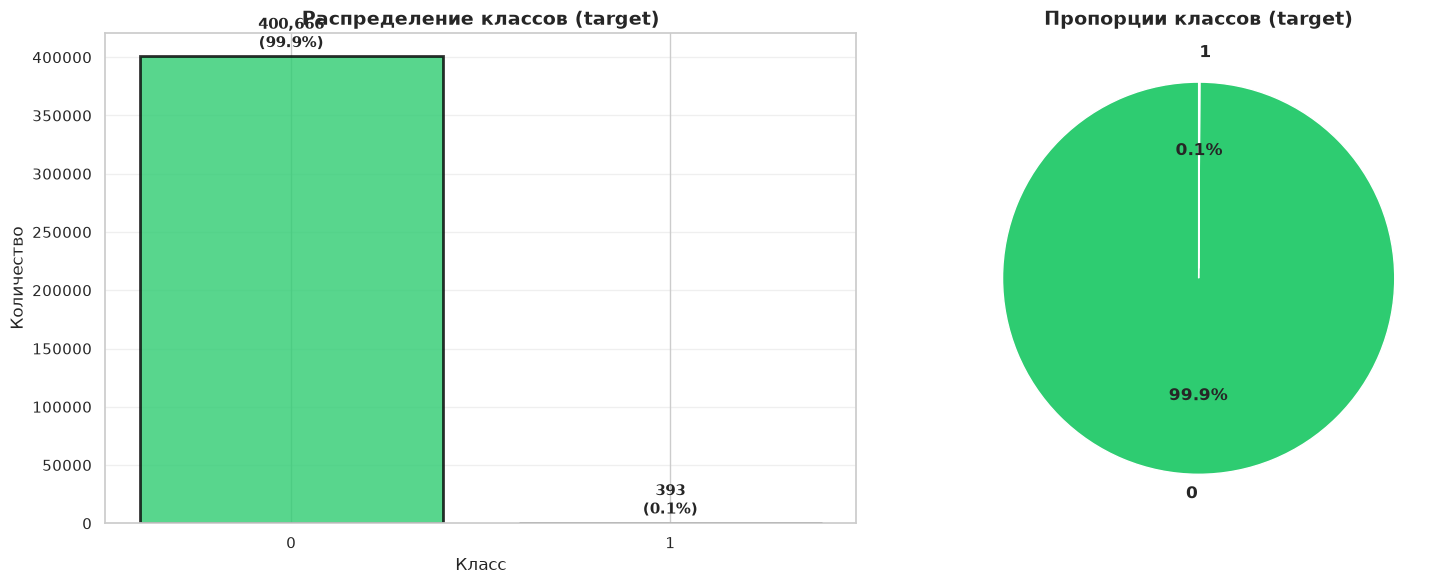


✅ График сохранен: train_class_distribution.png
\n💡 СТРАТЕГИИ БОРЬБЫ С ДИСБАЛАНСОМ (0.1% malignant):
   1. Loss: Focal Loss (γ=2-5, α~0.5) — автоматически фокусируется на hard examples
   2. Sampling: WeightedRandomSampler с weight=1/class_count — balanced batches
   3. Oversampling: SMOTE/ADASYN — синтетические minority samples (осторожно с high-dim)
   4. Threshold tuning: после обучения подобрать optimal threshold на val (не 0.5)
   5. Evaluation: PR-AUC предпочтительнее ROC-AUC при extreme imbalance
   6. Метрика для early stopping: F2-score (recall важнее precision для cancer)


In [110]:
# ==========================================
# АНАЛИЗ РАСПРЕДЕЛЕНИЯ КЛАССОВ
# ==========================================

if target_col and target_col in df_train.columns:
    print("\n" + "="*80)
    print(f"🎯 АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ: {target_col}")
    print("="*80)

    class_counts = df_train[target_col].value_counts()
    class_proportions = df_train[target_col].value_counts(normalize=True)

    print(f"\n📊 Распределение классов:")
    for cls, count in class_counts.items():
        prop = class_proportions[cls]
        print(f"   {cls}: {count:,} ({prop*100:.2f}%)")

    # Расчет дисбаланса
    if len(class_counts) == 2:
        imbalance_ratio = class_counts.max() / class_counts.min()
        print(f"\n⚖️ Соотношение дисбаланса: 1:{imbalance_ratio:.2f}")

        if imbalance_ratio > 10:
            print("   ❌ КРИТИЧЕСКИЙ ДИСБАЛАНС!")
            print("   → Требуется: SMOTE + Focal Loss + WeightedRandomSampler")
        elif imbalance_ratio > 3:
            print("   ⚠️ Значительный дисбаланс")
            print("   → Рекомендуется: Class weights + WeightedRandomSampler")
        else:
            print("   ✅ Дисбаланс в приемлемых пределах")
            print("   → Можно использовать: Standard BCE/CrossEntropy")

    # Визуализация
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Барплот
    colors = [CLASS_COLORS.get(cls, '#95a5a6') for cls in class_counts.index]
    bars = axes[0].bar(class_counts.index.astype(str), class_counts.values,
                       color=colors, alpha=0.8, edgecolor='black', linewidth=2)
    axes[0].set_title(f'Распределение классов ({target_col})', fontweight='bold', fontsize=14)
    axes[0].set_xlabel('Класс', fontsize=12)
    axes[0].set_ylabel('Количество', fontsize=12)
    axes[0].grid(alpha=0.3, axis='y')

    # Добавляем значения на столбцах
    for i, (cls, count) in enumerate(class_counts.items()):
        axes[0].text(i, count + class_counts.max()*0.02,
                    f'{count:,}\n({class_proportions[cls]*100:.1f}%)',
                    ha='center', fontweight='bold', fontsize=11)

    # Пай-чарт
    axes[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%',
               colors=colors, startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'},
               explode=[0.05 if class_counts.values[i] == class_counts.min() else 0 for i in range(len(class_counts))])
    axes[1].set_title(f'Пропорции классов ({target_col})', fontweight='bold', fontsize=14)

    plt.tight_layout()
    plt.savefig('train_class_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("\n✅ График сохранен: train_class_distribution.png")
else:
    print("\n⚠️ Целевая переменная не найдена! Анализ невозможен.")

print("\\n💡 СТРАТЕГИИ БОРЬБЫ С ДИСБАЛАНСОМ (0.1% malignant):")
print("   1. Loss: Focal Loss (γ=2-5, α~0.5) — автоматически фокусируется на hard examples")
print("   2. Sampling: WeightedRandomSampler с weight=1/class_count — balanced batches")
print("   3. Oversampling: SMOTE/ADASYN — синтетические minority samples (осторожно с high-dim)")
print("   4. Threshold tuning: после обучения подобрать optimal threshold на val (не 0.5)")
print("   5. Evaluation: PR-AUC предпочтительнее ROC-AUC при extreme imbalance")
print("   6. Метрика для early stopping: F2-score (recall важнее precision для cancer)")


## 3. 🕳️ Анализ пропущенных значений



🕳️ АНАЛИЗ ПРОПУЩЕННЫХ ЗНАЧЕНИЙ

⚠️ Обнаружены пропущенные значения:



,Признак,Пропущено,Процент
iddx_5,iddx_5,401058,100.00
mel_mitotic_index,mel_mitotic_index,401006,99.99
mel_thick_mm,mel_thick_mm,400996,99.98
iddx_4,iddx_4,400508,99.86
iddx_3,iddx_3,399994,99.73
iddx_2,iddx_2,399991,99.73
lesion_id,lesion_id,379001,94.50
sex,sex,11517,2.87
anatom_site_general,anatom_site_general,5756,1.44
age_approx,age_approx,2798,0.70


/tmp/ipykernel_19139/2074072948.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=missing_data, y='Признак', x='Процент', palette='Reds_r')


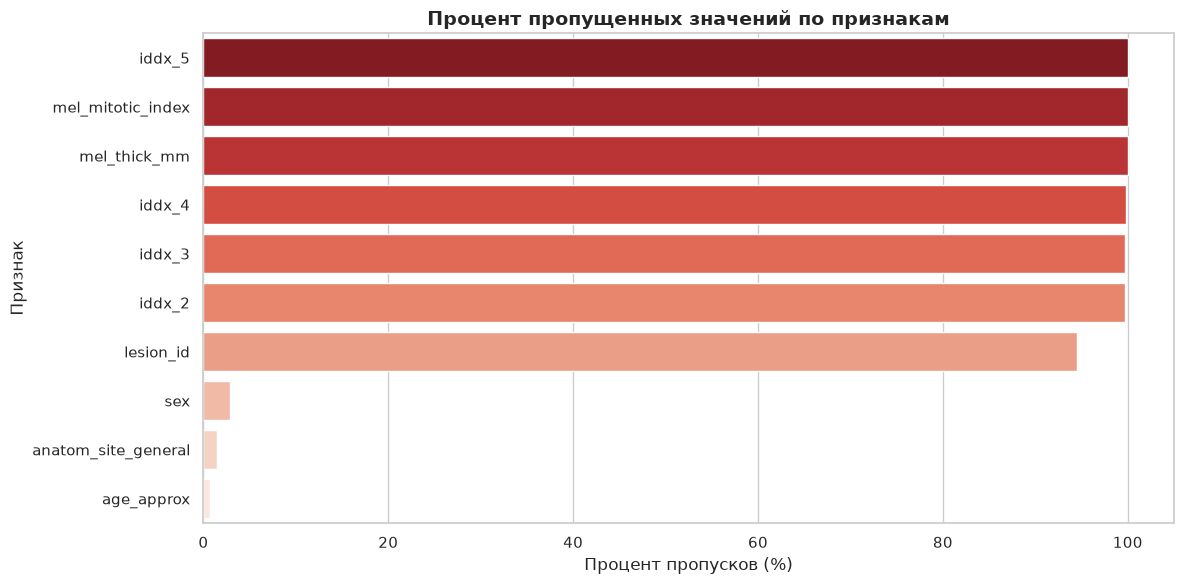


💡 РЕКОМЕНДАЦИИ ПО ОБРАБОТКЕ ПРОПУСКОВ

❌ КРИТИЧНО: 7 признаков с >50% пропусков:
   - iddx_5
   - mel_mitotic_index
   - mel_thick_mm
   - iddx_4
   - iddx_3
   - iddx_2
   - lesion_id
   → Рекомендация: Удалить эти признаки

✅ 3 признаков с <10% пропусков:
   - sex
   - anatom_site_general
   - age_approx
   → Рекомендация: Простой imputation (median/mode)

✅ График сохранен: train_missing_values.png


In [111]:
# ==========================================
# АНАЛИЗ ПРОПУСКОВ
# ==========================================

print("\n" + "="*80)
print("🕳️ АНАЛИЗ ПРОПУЩЕННЫХ ЗНАЧЕНИЙ")
print("="*80)

missing_data = pd.DataFrame({
    'Признак': df_train.columns,
    'Пропущено': df_train.isnull().sum(),
    'Процент': (df_train.isnull().sum() / len(df_train) * 100).round(2)
}).sort_values('Пропущено', ascending=False)

missing_data = missing_data[missing_data['Пропущено'] > 0]

if len(missing_data) > 0:
    print("\n⚠️ Обнаружены пропущенные значения:\n")
    display(missing_data)

    # Визуализация
    plt.figure(figsize=(12, max(6, len(missing_data) * 0.4)))
    sns.barplot(data=missing_data, y='Признак', x='Процент', palette='Reds_r')
    plt.title('Процент пропущенных значений по признакам', fontweight='bold', fontsize=14)
    plt.xlabel('Процент пропусков (%)', fontsize=12)
    plt.tight_layout()
    plt.savefig('train_missing_values.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Рекомендации
    print("\n" + "="*80)
    print("💡 РЕКОМЕНДАЦИИ ПО ОБРАБОТКЕ ПРОПУСКОВ")
    print("="*80)

    high_missing = missing_data[missing_data['Процент'] > 50]
    if len(high_missing) > 0:
        print(f"\n❌ КРИТИЧНО: {len(high_missing)} признаков с >50% пропусков:")
        for feat in high_missing['Признак'].tolist():
            print(f"   - {feat}")
        print("   → Рекомендация: Удалить эти признаки")

    moderate_missing = missing_data[(missing_data['Процент'] > 10) & (missing_data['Процент'] <= 50)]
    if len(moderate_missing) > 0:
        print(f"\n⚠️ {len(moderate_missing)} признаков с 10-50% пропусков:")
        for feat in moderate_missing['Признак'].tolist():
            print(f"   - {feat}")
        print("   → Рекомендация: Imputation (median/mode) или создать флаг 'was_missing'")

    low_missing = missing_data[missing_data['Процент'] <= 10]
    if len(low_missing) > 0:
        print(f"\n✅ {len(low_missing)} признаков с <10% пропусков:")
        for feat in low_missing['Признак'].tolist():
            print(f"   - {feat}")
        print("   → Рекомендация: Простой imputation (median/mode)")

    print("\n✅ График сохранен: train_missing_values.png")
else:
    print("\n✅ Пропущенных значений не обнаружено!")


## 4. 👤 Анализ метаданных


In [112]:
# Определение типов признаков
numeric_cols = df_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df_train.select_dtypes(include=['object', 'category']).columns.tolist()

print("\n" + "="*80)
print("📊 ТИПЫ ДАННЫХ")
print("="*80)
print(f"\n🔢 Числовые признаки ({len(numeric_cols)}): {numeric_cols}")
print(f"\n📝 Категориальные признаки ({len(categorical_cols)}): {categorical_cols}")



📊 ТИПЫ ДАННЫХ

🔢 Числовые признаки (37): ['target', 'age_approx', 'clin_size_long_diam_mm', 'tbp_lv_A', 'tbp_lv_Aext', 'tbp_lv_B', 'tbp_lv_Bext', 'tbp_lv_C', 'tbp_lv_Cext', 'tbp_lv_H', 'tbp_lv_Hext', 'tbp_lv_L', 'tbp_lv_Lext', 'tbp_lv_areaMM2', 'tbp_lv_area_perim_ratio', 'tbp_lv_color_std_mean', 'tbp_lv_deltaA', 'tbp_lv_deltaB', 'tbp_lv_deltaL', 'tbp_lv_deltaLB', 'tbp_lv_deltaLBnorm', 'tbp_lv_eccentricity', 'tbp_lv_minorAxisMM', 'tbp_lv_nevi_confidence', 'tbp_lv_norm_border', 'tbp_lv_norm_color', 'tbp_lv_perimeterMM', 'tbp_lv_radial_color_std_max', 'tbp_lv_stdL', 'tbp_lv_stdLExt', 'tbp_lv_symm_2axis', 'tbp_lv_symm_2axis_angle', 'tbp_lv_x', 'tbp_lv_y', 'tbp_lv_z', 'mel_thick_mm', 'tbp_lv_dnn_lesion_confidence']

📝 Категориальные признаки (18): ['isic_id', 'patient_id', 'sex', 'anatom_site_general', 'image_type', 'tbp_tile_type', 'tbp_lv_location', 'tbp_lv_location_simple', 'attribution', 'copyright_license', 'lesion_id', 'iddx_full', 'iddx_1', 'iddx_2', 'iddx_3', 'iddx_4', 'iddx_5', 'm

/tmp/ipykernel_19139/3935829484.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_train.select_dtypes(include=['object', 'category']).columns.tolist()


### 4.1 Анализ возраста



👤 АНАЛИЗ ВОЗРАСТА: age_approx

📊 Статистика возраста:
count    398261.000000
mean         58.012986
std          13.596165
min           5.000000
25%          50.000000
50%          60.000000
75%          70.000000
max          85.000000
Name: age_approx, dtype: float64


/tmp/ipykernel_19139/3274875042.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_temp, x=target_col, y=age_col, palette=box_colors, ax=axes[1])
/tmp/ipykernel_19139/3274875042.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_temp, x=target_col, y=age_col, palette=box_colors, ax=axes[2])


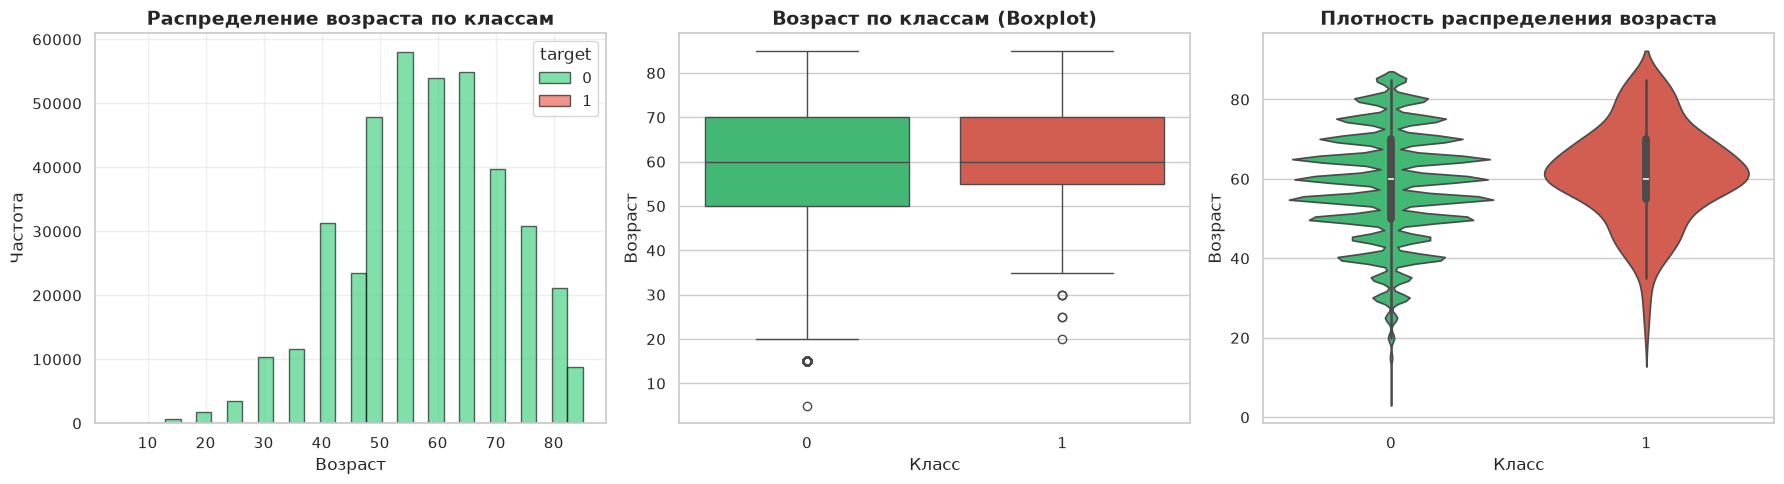


📊 Kolmogorov-Smirnov Test:
   Statistic: 0.1534
   P-value: 0.0000
   ✅ Распределения возраста статистически различаются (p < 0.05)
   → Возраст полезен для модели!

✅ График сохранен: train_age_analysis.png


In [113]:
if age_col and age_col in df_train.columns and target_col in df_train.columns:
    print("\n" + "="*80)
    print(f"👤 АНАЛИЗ ВОЗРАСТА: {age_col}")
    print("="*80)

    # Статистика
    print("\n📊 Статистика возраста:")
    print(df_train[age_col].describe())

    # Визуализация
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # График 1: Гистограмма по классам
    for cls in df_train[target_col].unique():
        subset = df_train[df_train[target_col] == cls][age_col].dropna()
        axes[0].hist(subset, bins=30, alpha=0.6, label=str(cls),
                    color=CLASS_COLORS.get(cls, '#95a5a6'), edgecolor='black')
    axes[0].legend(title=target_col)
    axes[0].set_xlabel('Возраст', fontsize=12)
    axes[0].set_ylabel('Частота', fontsize=12)
    axes[0].set_title('Распределение возраста по классам', fontweight='bold')
    axes[0].grid(alpha=0.3)

    # График 2: Boxplot
    df_temp = df_train[[age_col, target_col]].dropna()
    box_colors = [CLASS_COLORS.get(cls, '#95a5a6') for cls in df_temp[target_col].unique()]
    sns.boxplot(data=df_temp, x=target_col, y=age_col, palette=box_colors, ax=axes[1])
    axes[1].set_title('Возраст по классам (Boxplot)', fontweight='bold')
    axes[1].set_xlabel('Класс', fontsize=12)
    axes[1].set_ylabel('Возраст', fontsize=12)

    # График 3: Violin plot
    sns.violinplot(data=df_temp, x=target_col, y=age_col, palette=box_colors, ax=axes[2])
    axes[2].set_title('Плотность распределения возраста', fontweight='bold')
    axes[2].set_xlabel('Класс', fontsize=12)
    axes[2].set_ylabel('Возраст', fontsize=12)

    plt.tight_layout()
    plt.savefig('train_age_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Статистический тест
    classes = df_train[target_col].unique()
    if len(classes) == 2:
        group1 = df_train[df_train[target_col] == classes[0]][age_col].dropna()
        group2 = df_train[df_train[target_col] == classes[1]][age_col].dropna()
        
        if len(group1) > 0 and len(group2) > 0:
            statistic, pvalue = stats.ks_2samp(group1, group2)

            print(f"\n📊 Kolmogorov-Smirnov Test:")
            print(f"   Statistic: {statistic:.4f}")
            print(f"   P-value: {pvalue:.4f}")

            if pvalue < 0.05:
                print("   ✅ Распределения возраста статистически различаются (p < 0.05)")
                print("   → Возраст полезен для модели!")
            else:
                print("   ❌ Нет статистически значимых различий (p >= 0.05)")

    print("\n✅ График сохранен: train_age_analysis.png")
else:
    print(f"\n⚠️ Анализ возраста пропущен: age_col={age_col}, target_col={target_col}")


### 4.2 Анализ пола



⚥ АНАЛИЗ ПОЛА: sex

📊 Распределение по полу:
   male: 265,546 (68.17%)
   female: 123,996 (31.83%)


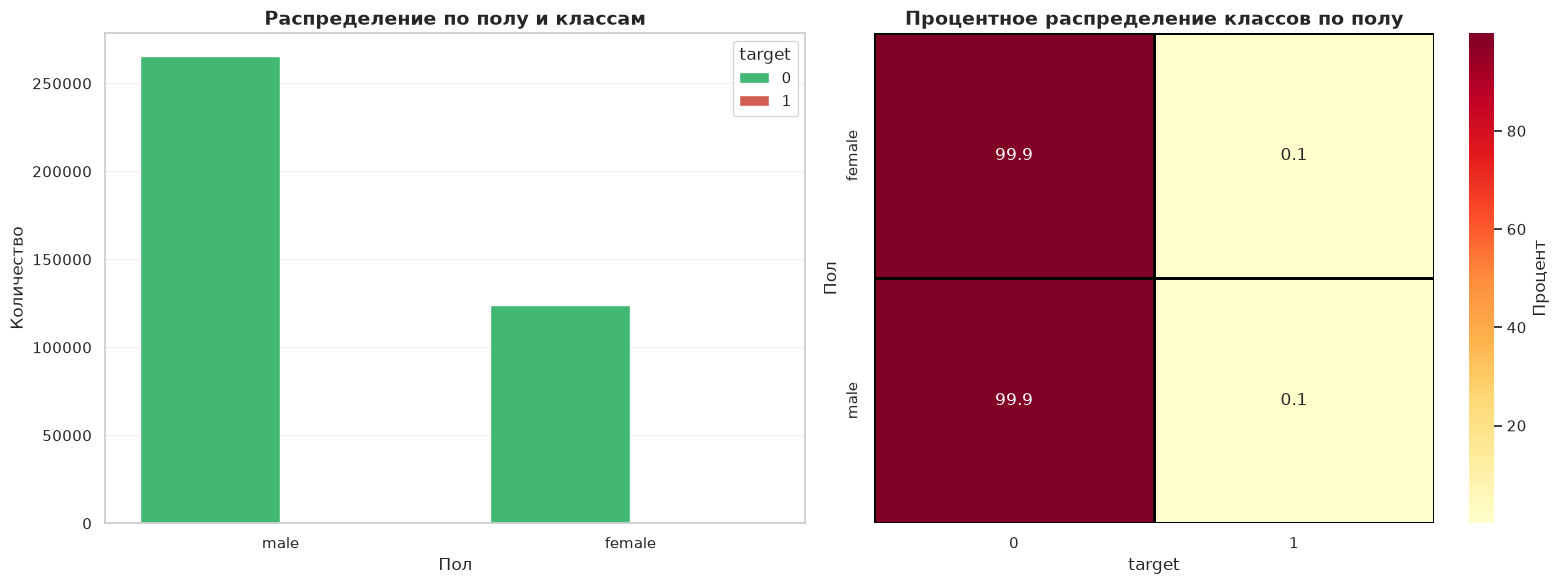


📊 Chi-Square Test:
   Chi2: 1.8560
   P-value: 0.1731
   ❌ Нет статистически значимой связи (p >= 0.05)

✅ График сохранен: train_sex_analysis.png


In [114]:
if sex_col and sex_col in df_train.columns and target_col in df_train.columns:
    print("\n" + "="*80)
    print(f"⚥ АНАЛИЗ ПОЛА: {sex_col}")
    print("="*80)

    # Статистика
    sex_counts = df_train[sex_col].value_counts()
    sex_proportions = df_train[sex_col].value_counts(normalize=True)

    print("\n📊 Распределение по полу:")
    for sex, count in sex_counts.items():
        prop = sex_proportions[sex]
        print(f"   {sex}: {count:,} ({prop*100:.2f}%)")

    # Crosstab
    ct = pd.crosstab(df_train[sex_col], df_train[target_col], normalize='index') * 100

    # Визуализация
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # График 1: Countplot
    plot_colors = [CLASS_COLORS.get(cls, '#95a5a6') for cls in df_train[target_col].unique()]
    sns.countplot(data=df_train, x=sex_col, hue=target_col, palette=plot_colors, ax=axes[0])
    axes[0].set_title('Распределение по полу и классам', fontweight='bold', fontsize=14)
    axes[0].set_xlabel('Пол', fontsize=12)
    axes[0].set_ylabel('Количество', fontsize=12)
    axes[0].legend(title=target_col)
    axes[0].grid(alpha=0.3, axis='y')

    # График 2: Heatmap пропорций
    sns.heatmap(ct, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[1],
               cbar_kws={'label': 'Процент'}, linewidths=1, linecolor='black')
    axes[1].set_title('Процентное распределение классов по полу', fontweight='bold', fontsize=14)
    axes[1].set_xlabel(target_col, fontsize=12)
    axes[1].set_ylabel('Пол', fontsize=12)

    plt.tight_layout()
    plt.savefig('train_sex_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Chi-square test
    ct_counts = pd.crosstab(df_train[sex_col], df_train[target_col])
    chi2, pvalue, dof, expected = chi2_contingency(ct_counts)

    print(f"\n📊 Chi-Square Test:")
    print(f"   Chi2: {chi2:.4f}")
    print(f"   P-value: {pvalue:.4f}")

    if pvalue < 0.05:
        print("   ✅ Пол статистически связан с классом (p < 0.05)")
        print("   → Пол полезен для модели!")
    else:
        print("   ❌ Нет статистически значимой связи (p >= 0.05)")

    print("\n✅ График сохранен: train_sex_analysis.png")
else:
    print(f"\n⚠️ Анализ пола пропущен: sex_col={sex_col}, target_col={target_col}")


### 4.3 Анализ локализации



📍 АНАЛИЗ ЛОКАЛИЗАЦИИ: anatom_site_general

📊 Топ-10 локализаций:
   1. posterior torso: 121,902 (30.4%)
   2. lower extremity: 103,028 (25.7%)
   3. anterior torso: 87,770 (21.9%)
   4. upper extremity: 70,557 (17.6%)
   5. head/neck: 12,046 (3.0%)

Всего уникальных локализаций: 5


/tmp/ipykernel_19139/1508590904.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_locs.index, x=top_locs.values, palette='viridis', ax=axes[0])


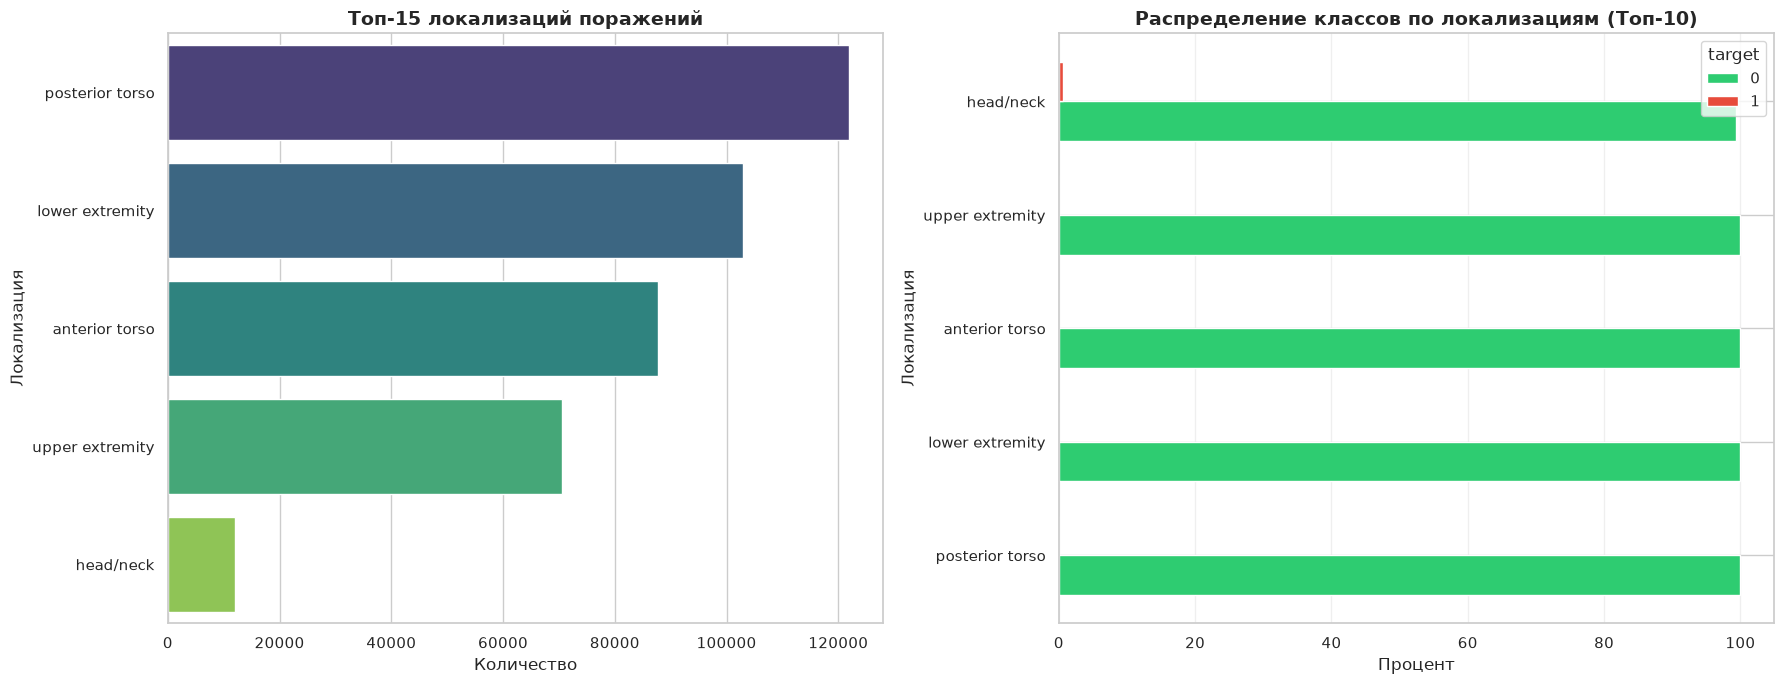


✅ График сохранен: train_location_analysis.png


In [115]:
if location_col and location_col in df_train.columns and target_col in df_train.columns:
    print("\n" + "="*80)
    print(f"📍 АНАЛИЗ ЛОКАЛИЗАЦИИ: {location_col}")
    print("="*80)

    # Статистика
    location_counts = df_train[location_col].value_counts()

    print(f"\n📊 Топ-10 локализаций:")
    for i, (loc, count) in enumerate(location_counts.head(10).items(), 1):
        prop = count / len(df_train) * 100
        print(f"   {i}. {loc}: {count:,} ({prop:.1f}%)")

    print(f"\nВсего уникальных локализаций: {df_train[location_col].nunique()}")

    # Визуализация
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    # График 1: Топ-15 локализаций
    top_locs = location_counts.head(15)
    sns.barplot(y=top_locs.index, x=top_locs.values, palette='viridis', ax=axes[0])
    axes[0].set_title('Топ-15 локализаций поражений', fontweight='bold', fontsize=14)
    axes[0].set_xlabel('Количество', fontsize=12)
    axes[0].set_ylabel('Локализация', fontsize=12)

    # График 2: Распределение по классам (топ-10)
    top_10_locs = location_counts.head(10).index
    df_temp = df_train[df_train[location_col].isin(top_10_locs)]
    ct = pd.crosstab(df_temp[location_col], df_temp[target_col], normalize='index') * 100
    ct = ct.loc[top_10_locs]  # Сохраняем порядок

    plot_colors = [CLASS_COLORS.get(cls, '#95a5a6') for cls in ct.columns]
    ct.plot(kind='barh', stacked=False, ax=axes[1], color=plot_colors, width=0.7)
    axes[1].set_title('Распределение классов по локализациям (Топ-10)', fontweight='bold', fontsize=14)
    axes[1].set_xlabel('Процент', fontsize=12)
    axes[1].set_ylabel('Локализация', fontsize=12)
    axes[1].legend(title=target_col)
    axes[1].grid(alpha=0.3, axis='x')

    plt.tight_layout()
    plt.savefig('train_location_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("\n✅ График сохранен: train_location_analysis.png")

    # Рекомендации по группировке
    rare_locs = location_counts[location_counts < 10]
    if len(rare_locs) > 0:
        print(f"\n⚠️ ВНИМАНИЕ: {len(rare_locs)} редких локализаций (<10 примеров)")
        print("   → Рекомендация: Группировать в категорию 'Other' или 'Rare'")

    if df_train[location_col].nunique() > 20:
        print(f"\n💡 Много категорий ({df_train[location_col].nunique()}) для One-Hot Encoding")
        print("   → Рекомендация: Использовать Label Encoding или Embeddings")
else:
    print(f"\n⚠️ Анализ локализации пропущен: location_col={location_col}, target_col={target_col}")


### 4.4 Пациенты с множественными снимками (TBP tile analysis)

**ВАЖНО:** В ISIC 2024 один пациент может иметь десятки TBP close-up снимков.
Это создаёт риск data leakage при случайном train/val split.


In [116]:
if patient_id_col and patient_id_col in df_train.columns:
    print("\n" + "="*80)
    print("PATIENTS WITH MULTIPLE SNAPSHOTS")
    print("="*80)
    
    patient_counts = df_train[patient_id_col].value_counts()
    print(f"   * Unique patients: {patient_counts.count()}")
    print(f"   * Avg snapshots per patient: {patient_counts.mean():.1f}")
    print(f"   * Median snapshots per patient: {patient_counts.median():.0f}")
    print(f"   * Max snapshots per patient: {patient_counts.max()}")
    
    high_risk = (patient_counts > 10).sum()
    print(f"\n   WARNING: Patients with >10 snapshots: {high_risk} ({(high_risk/patient_counts.count())*100:.1f}% patients)")
    print(f"   WARNING: Total snapshots from them: {patient_counts[patient_counts > 10].sum()} ({(patient_counts[patient_counts > 10].sum()/len(df_train))*100:.1f}% dataset)")
    print("\n   RECOMMENDATION: use StratifiedGroupKFold by patient_id")
else:
    print("WARNING: patient_id column not found -- skipping analysis")



PATIENTS WITH MULTIPLE SNAPSHOTS
   * Unique patients: 1042
   * Avg snapshots per patient: 384.9
   * Median snapshots per patient: 242
   * Max snapshots per patient: 9184


   RECOMMENDATION: use StratifiedGroupKFold by patient_id


### 4.5 Анализ lesion_id (поражения с несколькими TBP tile)

**ВАЖНО:** Один `lesion_id` может иметь несколько TBP close-up изображений.
Это дополнительный уровень группировки для предотвращения data leakage.


In [117]:
lesion_col = find_column(df_train, ['lesion_id'], 'lesion')
if lesion_col and lesion_col in df_train.columns:
    non_null = df_train[lesion_col].notna().sum()
    print("\n" + "="*80)
    print("LESION_ID ANALYSIS (lesions with multiple TBP tiles)")
    print("="*80)
    print(f"   * Non-null lesion_id: {non_null} out of {len(df_train)} ({non_null/len(df_train)*100:.1f}%)")
    
    if non_null > 0:
        lesion_counts = df_train[df_train[lesion_col].notna()][lesion_col].value_counts()
        print(f"   * Unique lesion_id: {lesion_counts.count()}")
        print(f"   * Avg TBP tiles per lesion: {lesion_counts.mean():.1f}")
        print(f"   * Max TBP tiles per lesion: {lesion_counts.max()}")
        multi_tile = (lesion_counts > 1).sum()
        print(f"   * Lesions with >1 TBP tile: {multi_tile} ({(multi_tile/lesion_counts.count())*100:.1f}% lesions)")
        print("\n   RECOMMENDATION: group by both patient_id and lesion_id")
else:
    print("WARNING: lesion_id column not found or all values null")


✅ Найдена lesion: 'lesion_id'

LESION_ID ANALYSIS (lesions with multiple TBP tiles)
   * Non-null lesion_id: 22058 out of 401059 (5.5%)
   * Unique lesion_id: 22058
   * Avg TBP tiles per lesion: 1.0
   * Max TBP tiles per lesion: 1
   * Lesions with >1 TBP tile: 0 (0.0% lesions)

   RECOMMENDATION: group by both patient_id and lesion_id


## 5. 📐 Анализ TRAIN изображений


In [118]:
# Функция извлечения метрик изображения
def extract_image_metrics(image_id, images_dir, extension='jpg'):
    """
    Извлекает метрики из изображения: разрешение, яркость, резкость, цвет
    """
    try:
        img_path = os.path.join(images_dir, f"{image_id}.{extension}")

        if not os.path.exists(img_path):
            return None

        img = cv2.imread(img_path)
        if img is None:
            return None

        h, w, c = img.shape
        aspect_ratio = w / h if h > 0 else 0

        # RGB статистика
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        r_mean, g_mean, b_mean = img_rgb.mean(axis=(0, 1))
        r_std, g_std, b_std = img_rgb.std(axis=(0, 1))

        # HSV для яркости
        img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        brightness = img_hsv[:,:,2].mean() / 255.0

        # Sharpness (Laplacian variance)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()

        # Perceptual hash для дубликатов
        gray_small = cv2.resize(gray, (8, 8))
        phash = hashlib.md5((gray_small > gray_small.mean()).astype(np.uint8).tobytes()).hexdigest()

        return {
            'width': w,
            'height': h,
            'aspect_ratio': aspect_ratio,
            'resolution': f"{w}x{h}",
            'r_mean': r_mean,
            'g_mean': g_mean,
            'b_mean': b_mean,
            'r_std': r_std,
            'g_std': g_std,
            'b_std': b_std,
            'brightness': brightness,
            'sharpness': laplacian_var,
            'phash': phash
        }
    except Exception as e:
        return None

print("✅ Функция extract_image_metrics определена")


✅ Функция extract_image_metrics определена


In [119]:
# Анализ изображений (СТРАТИФИЦИРОВАННАЯ выборка 50/50)
print("\n" + "="*80)
print("📐 АНАЛИЗ TRAIN ИЗОБРАЖЕНИЙ")
print("="*80)
# СТРАТИФИЦИРОВАННАЯ ВЫБОРКА: все malignant + равное количество benign
# Пытаемся загрузить из кэша
df_images_cached = load_cache(CACHE_IMAGES, format='csv')
if df_images_cached is not None:
    print("📂 Используем кэшированные метрики изображений.")
    df_images = df_images_cached
else:
    print("🔄 Вычисляем метрики изображений...")
# Это даёт статистически значимое сравнение классов (50/50 вместо 1:1019)
malignant_ids_sample = df_train[df_train[target_col] == 1][image_id_col].values
benign_ids_all = df_train[df_train[target_col] == 0][image_id_col].values
n_mal = len(malignant_ids_sample)
np.random.seed(GLOBAL_RANDOM_SEED)
benign_ids_sample = np.random.choice(benign_ids_all, size=n_mal, replace=False)
selected_ids = np.concatenate([malignant_ids_sample, benign_ids_sample])
df_sample = df_train[df_train[image_id_col].isin(selected_ids)]
sample_size = len(df_sample)
print(f"\n🔄 Анализируем {sample_size} изображений:")
print(f"   Malignant: {n_mal} (ВСЕ)")
print(f"   Benign:    {n_mal} (сбалансированная подвыборка)")
print(f"   Соотношение: 1:1 (сбалансировано для сравнения классов)")
# Извлечение метрик
image_metrics = []
for idx, row in tqdm(df_sample.iterrows(), total=len(df_sample), desc="Обработка изображений"):
    image_id = row[image_id_col]
    metrics = extract_image_metrics(image_id, train_images_dir)
    if metrics:
        metrics['image_id'] = image_id
        if target_col in row:
            metrics[target_col] = row[target_col]
        image_metrics.append(metrics)
df_images = pd.DataFrame(image_metrics)
print(f"\n✅ Успешно обработано: {len(df_images)} изображений")
print(f"❌ Не удалось обработать: {sample_size - len(df_images)} изображений")
if len(df_images) > 0:
    print("\n📊 Статистика по изображениям:")
    display(df_images[['width', 'height', 'aspect_ratio', 'brightness', 'sharpness']].describe())



📐 АНАЛИЗ TRAIN ИЗОБРАЖЕНИЙ
🔄 Вычисляем метрики изображений...

🔄 Анализируем 786 изображений:
   Malignant: 393 (ВСЕ)
   Benign:    393 (сбалансированная подвыборка)
   Соотношение: 1:1 (сбалансировано для сравнения классов)


Обработка изображений: 100%|██████████| 786/786 [00:00<00:00, 932.40it/s]


✅ Успешно обработано: 786 изображений
❌ Не удалось обработать: 0 изображений

📊 Статистика по изображениям:


,width,height,aspect_ratio,brightness,sharpness
count,786.000000,786.000000,786.0,786.000000,786.000000
mean,131.463104,131.463104,1.0,0.679595,94.566036
std,18.348899,18.348899,0.0,0.124063,102.826147
min,87.000000,87.000000,1.0,0.287585,10.056546
25%,119.000000,119.000000,1.0,0.605044,41.466300
50%,131.000000,131.000000,1.0,0.688756,62.082634
75%,141.000000,141.000000,1.0,0.757622,106.153120
max,215.000000,215.000000,1.0,0.990443,1162.998287


### 5.1 Визуализация метрик изображений


/tmp/ipykernel_19139/392781698.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=resolution_counts.index, x=resolution_counts.values, palette='viridis', ax=axes[0, 0])
/tmp/ipykernel_19139/392781698.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_images, x=target_col, y='brightness', palette=box_colors, ax=axes[0, 2])
/tmp/ipykernel_19139/392781698.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_images, x=target_col, y='sharpness', palette=box_colors, ax=axes[1, 0])


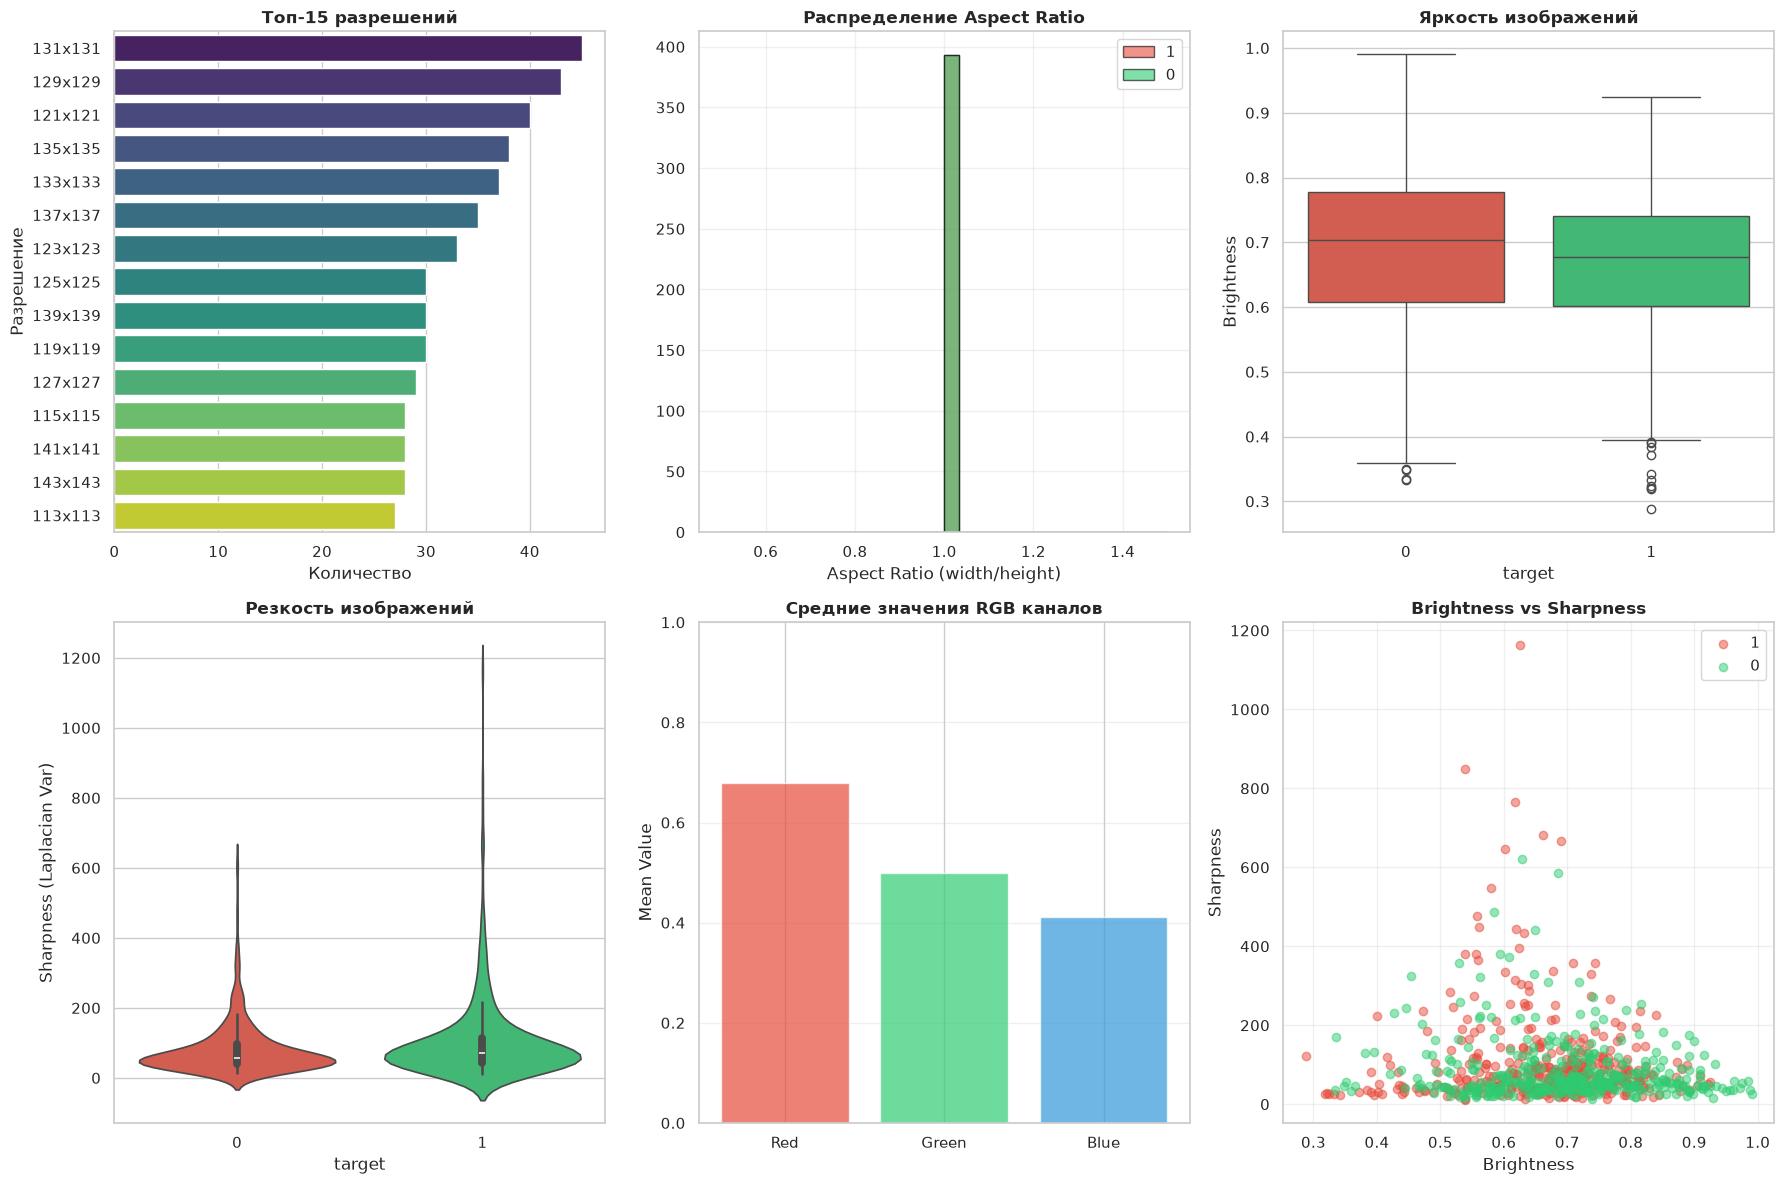


✅ График сохранен: train_image_metrics.png


In [120]:
if len(df_images) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    # 1. Распределение разрешений
    resolution_counts = df_images['resolution'].value_counts().head(15)
    sns.barplot(y=resolution_counts.index, x=resolution_counts.values, palette='viridis', ax=axes[0, 0])
    axes[0, 0].set_title('Топ-15 разрешений', fontweight='bold', fontsize=12)
    axes[0, 0].set_xlabel('Количество')
    axes[0, 0].set_ylabel('Разрешение')

    # 2. Aspect ratio
    if target_col in df_images.columns:
        for cls in df_images[target_col].unique():
            subset = df_images[df_images[target_col] == cls]['aspect_ratio']
            axes[0, 1].hist(subset, bins=30, alpha=0.6, label=str(cls),
                          color=CLASS_COLORS.get(cls, '#95a5a6'), edgecolor='black')
        axes[0, 1].legend()
    else:
        axes[0, 1].hist(df_images['aspect_ratio'], bins=30, color='skyblue', edgecolor='black')
    axes[0, 1].set_title('Распределение Aspect Ratio', fontweight='bold', fontsize=12)
    axes[0, 1].set_xlabel('Aspect Ratio (width/height)')
    axes[0, 1].grid(alpha=0.3)

    # 3. Brightness
    if target_col in df_images.columns:
        box_colors = [CLASS_COLORS.get(cls, '#95a5a6') for cls in df_images[target_col].unique()]
        sns.boxplot(data=df_images, x=target_col, y='brightness', palette=box_colors, ax=axes[0, 2])
    else:
        sns.boxplot(data=df_images, y='brightness', ax=axes[0, 2])
    axes[0, 2].set_title('Яркость изображений', fontweight='bold', fontsize=12)
    axes[0, 2].set_ylabel('Brightness')

    # 4. Sharpness
    if target_col in df_images.columns:
        sns.violinplot(data=df_images, x=target_col, y='sharpness', palette=box_colors, ax=axes[1, 0])
    else:
        sns.violinplot(data=df_images, y='sharpness', ax=axes[1, 0])
    axes[1, 0].set_title('Резкость изображений', fontweight='bold', fontsize=12)
    axes[1, 0].set_ylabel('Sharpness (Laplacian Var)')

    # 5. RGB means
    rgb_means = df_images[['r_mean', 'g_mean', 'b_mean']].mean()
    axes[1, 1].bar(['Red', 'Green', 'Blue'], rgb_means, color=['#e74c3c', '#2ecc71', '#3498db'], alpha=0.7)
    axes[1, 1].set_title('Средние значения RGB каналов', fontweight='bold', fontsize=12)
    axes[1, 1].set_ylabel('Mean Value')
    axes[1, 1].set_ylim(0, 1)
    axes[1, 1].grid(alpha=0.3, axis='y')

    # 6. Scatter: brightness vs sharpness
    if target_col in df_images.columns:
        for cls in df_images[target_col].unique():
            subset = df_images[df_images[target_col] == cls]
            axes[1, 2].scatter(subset['brightness'], subset['sharpness'],
                             alpha=0.5, label=str(cls), color=CLASS_COLORS.get(cls, '#95a5a6'))
        axes[1, 2].legend()
    else:
        axes[1, 2].scatter(df_images['brightness'], df_images['sharpness'], alpha=0.5)
    axes[1, 2].set_xlabel('Brightness')
    axes[1, 2].set_ylabel('Sharpness')
    axes[1, 2].set_title('Brightness vs Sharpness', fontweight='bold', fontsize=12)
    axes[1, 2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('train_image_metrics.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("\n✅ График сохранен: train_image_metrics.png")


### 5.2 Рекомендации по изображениям


In [121]:
if len(df_images) > 0:
    print("\n" + "="*80)
    print("💡 РЕКОМЕНДАЦИИ ПО ОБРАБОТКЕ ИЗОБРАЖЕНИЙ")
    print("="*80)

    # 1. Разрешение
    most_common_res = df_images['resolution'].mode()[0]
    unique_resolutions = df_images['resolution'].nunique()

    print(f"\n1️⃣ РАЗРЕШЕНИЕ:")
    print(f"   • Найдено {unique_resolutions} различных разрешений")
    print(f"   • Наиболее частое: {most_common_res}")

    # Определяем target size
    w, h = map(int, most_common_res.split('x'))
    if max(w, h) >= 1024:
        target_size = 512
    elif max(w, h) >= 512:
        target_size = 384
    else:
        target_size = 224

    print(f"   → Рекомендация: Resize к {target_size}x{target_size}")

    # 2. Aspect ratio
    ar_std = df_images['aspect_ratio'].std()
    print(f"\n2️⃣ ASPECT RATIO:")
    print(f"   • Стандартное отклонение: {ar_std:.4f}")

    if ar_std > 0.1:
        print("   → Рекомендация: Использовать padding перед resize (сохранение пропорций)")
    else:
        print("   → Рекомендация: Можно использовать прямой resize")

    # 3. Brightness
    brightness_std = df_images['brightness'].std()
    print(f"\n3️⃣ ЯРКОСТЬ:")
    print(f"   • Среднее: {df_images['brightness'].mean():.3f}")
    print(f"   • Стандартное отклонение: {brightness_std:.3f}")

    if brightness_std > 0.15:
        print("   → Рекомендация: RandomBrightnessContrast в аугментациях")

    # 4. Sharpness
    low_sharpness_ratio = (df_images['sharpness'] < df_images['sharpness'].quantile(0.1)).mean()
    print(f"\n4️⃣ РЕЗКОСТЬ:")
    print(f"   • Изображений с низкой резкостью (<10 перцентиль): {low_sharpness_ratio*100:.1f}%")

    if low_sharpness_ratio > 0.1:
        print("   → Рекомендация: Рассмотреть фильтрацию размытых изображений")

    # 5. Дубликаты
    if 'phash' in df_images.columns:
        phash_counts = df_images['phash'].value_counts()
        duplicates = phash_counts[phash_counts > 1]

        if len(duplicates) > 0:
            total_dup = duplicates.sum() - len(duplicates)
            print(f"\n5️⃣ ДУБЛИКАТЫ:")
            print(f"   ⚠️ Найдено {len(duplicates)} групп дубликатов ({total_dup} изображений)")
            print("   → Рекомендация: Удалить дубликаты перед обучением")

    # 6. Blur detection
    if 'sharpness' in df_images.columns:
        blur_threshold = df_images['sharpness'].quantile(0.05)
        n_blurry = (df_images['sharpness'] < blur_threshold).sum()
        print(f"\n6️⃣ BLUR DETECTION:")
        print(f"   • Potentially blurry images (<5th percentile): {n_blurry} ({n_blurry/len(df_images)*100:.1f}%)")
        if n_blurry > len(df_images) * 0.05:
            print("   → Рекомендация: Рассмотреть фильтрацию размытых изображений при инференсе")

else:
    print("\n⚠️ Изображения не были проанализированы")



💡 РЕКОМЕНДАЦИИ ПО ОБРАБОТКЕ ИЗОБРАЖЕНИЙ

1️⃣ РАЗРЕШЕНИЕ:
   • Найдено 55 различных разрешений
   • Наиболее частое: 131x131
   → Рекомендация: Resize к 224x224

2️⃣ ASPECT RATIO:
   • Стандартное отклонение: 0.0000
   → Рекомендация: Можно использовать прямой resize

3️⃣ ЯРКОСТЬ:
   • Среднее: 0.680
   • Стандартное отклонение: 0.124

4️⃣ РЕЗКОСТЬ:
   • Изображений с низкой резкостью (<10 перцентиль): 10.1%
   → Рекомендация: Рассмотреть фильтрацию размытых изображений

5️⃣ ДУБЛИКАТЫ:
   ⚠️ Найдено 2 групп дубликатов (5 изображений)
   → Рекомендация: Удалить дубликаты перед обучением

6️⃣ BLUR DETECTION:
   • Potentially blurry images (<5th percentile): 40 (5.1%)
   → Рекомендация: Рассмотреть фильтрацию размытых изображений при инференсе


## 6. 🎨 Визуализация примеров по классам



🎨 ВИЗУАЛИЗАЦИЯ ПРИМЕРОВ ПО КЛАССАМ


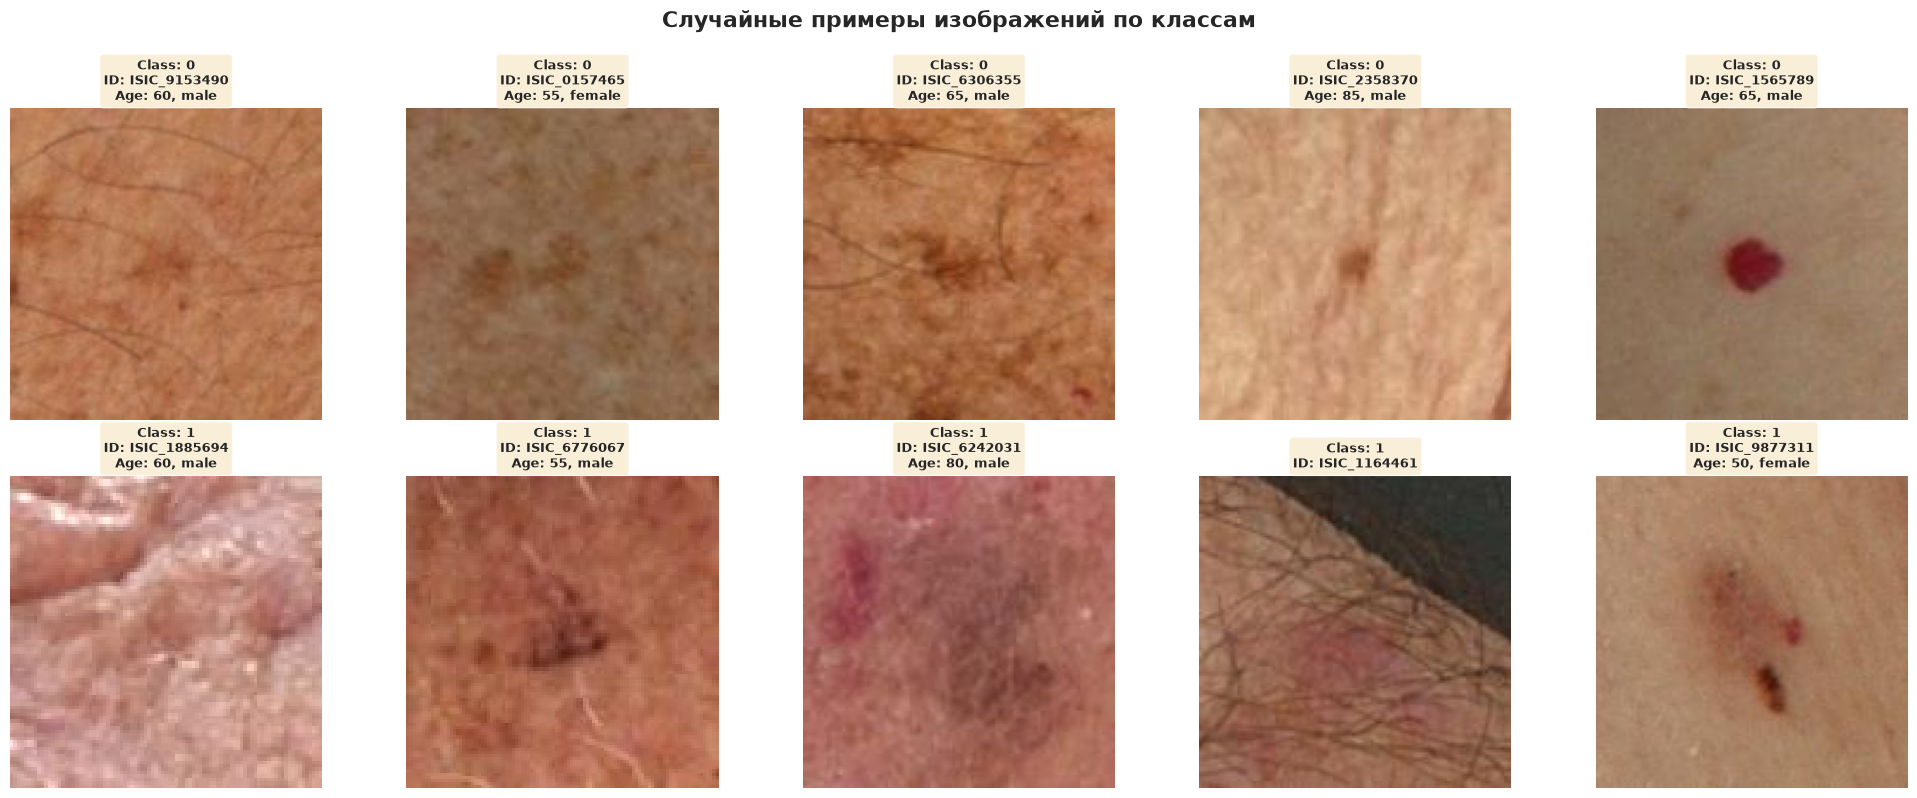

✅ График сохранен: train_sample_images.png


In [122]:
if target_col in df_train.columns and image_id_col:
    print("\n" + "="*80)
    print("🎨 ВИЗУАЛИЗАЦИЯ ПРИМЕРОВ ПО КЛАССАМ")
    print("="*80)

    # Проверяем наличие изображений
    sample_image_files = glob.glob(os.path.join(train_images_dir, "*.jpg"))
    if len(sample_image_files) == 0:
        print("⚠️ Изображения не найдены в директории!")
        print(f"   Путь: {train_images_dir}")
    else:
        classes = df_train[target_col].unique()
        n_classes = len(classes)
        n_samples_per_class = 5

        fig, axes = plt.subplots(n_classes, n_samples_per_class,
                                figsize=(20, n_classes*4))

        # Обработка случая с одним классом
        if n_classes == 1:
            axes = axes.reshape(1, -1)

        for i, cls in enumerate(classes):
            # Выбираем случайные примеры для класса
            class_df = df_train[df_train[target_col] == cls]

            if len(class_df) == 0:
                continue

            class_samples = class_df.sample(
                n=min(n_samples_per_class, len(class_df)),
                random_state=42
            )

            for j, (idx, row) in enumerate(class_samples.iterrows()):
                image_id = row[image_id_col]

                # Пробуем разные расширения
                img_path = None
                for ext in ['jpg', 'JPG', 'jpeg', 'JPEG', 'png', 'PNG']:
                    potential_path = os.path.join(train_images_dir, f"{image_id}.{ext}")
                    if os.path.exists(potential_path):
                        img_path = potential_path
                        break

                if img_path and os.path.exists(img_path):
                    try:
                        # Читаем изображение
                        img = cv2.imread(img_path)
                        if img is not None:
                            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                            # Отображаем
                            ax = axes[i, j] if n_classes > 1 else axes[j]
                            ax.imshow(img)
                            ax.axis('off')

                            # Заголовок с информацией
                            title = f"Class: {cls}\nID: {str(image_id)[:15]}"

                            # Добавляем метаданные если есть
                            metadata_parts = []
                            if age_col and age_col in row and pd.notna(row[age_col]):
                                metadata_parts.append(f"Age: {int(row[age_col])}")
                            if sex_col and sex_col in row and pd.notna(row[sex_col]):
                                metadata_parts.append(str(row[sex_col]))

                            if metadata_parts:
                                title += f"\n{', '.join(metadata_parts)}"

                            ax.set_title(title, fontsize=9, fontweight='bold',
                                       bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
                        else:
                            # Если не удалось прочитать
                            ax = axes[i, j] if n_classes > 1 else axes[j]
                            ax.text(0.5, 0.5, f'Ошибка\nчтения\n{image_id}',
                                   ha='center', va='center')
                            ax.axis('off')
                    except Exception as e:
                        ax = axes[i, j] if n_classes > 1 else axes[j]
                        ax.text(0.5, 0.5, f'Error:\n{str(e)[:20]}',
                               ha='center', va='center')
                        ax.axis('off')
                else:
                    # Если файл не найден
                    ax = axes[i, j] if n_classes > 1 else axes[j]
                    ax.text(0.5, 0.5, f'Not found:\n{image_id}',
                           ha='center', va='center', fontsize=8)
                    ax.axis('off')

        plt.suptitle('Случайные примеры изображений по классам',
                    fontsize=16, fontweight='bold', y=0.995)
        plt.tight_layout()
        plt.savefig('train_sample_images.png', dpi=200, bbox_inches='tight')
        plt.show()

        print("✅ График сохранен: train_sample_images.png")
else:
    print("\n⚠️ Не удалось визуализировать: отсутствует целевая переменная или ID колонка")


## 6.5 🔍 Детектирование дубликатов изображений

**Цель:** поиск точных дубликатов изображений через хеширование.
Дубликаты могут привести к data leakage между train/val.


In [123]:
print("\\n" + "="*80)
print("🔍 ДЕТЕКТИРОВАНИЕ ДУБЛИКАТОВ ИЗОБРАЖЕНИЙ")
print("="*80)

# Используем MD5-хеш для поиска точных дубликатов
hash_list = []
sample_size_dup = len(df_train) # ограничиваем для скорости
sample_for_dup = df_train.sample(n=sample_size_dup, random_state=GLOBAL_RANDOM_SEED) if len(df_train) > 5000 else df_train

if image_id_col:
    for _, row in tqdm(sample_for_dup.iterrows(), total=len(sample_for_dup), desc="Hashing images"):
        img_file = os.path.join(train_images_dir, f"{row[image_id_col]}.jpg")
        if os.path.exists(img_file):
            try:
                with open(img_file, 'rb') as f:
                    file_hash = hashlib.md5(f.read()).hexdigest()
                hash_list.append({'image_id': row[image_id_col], 'md5_hash': file_hash})
            except Exception:
                pass

if hash_list:
    df_hashes = pd.DataFrame(hash_list)
    dup_hashes = df_hashes['md5_hash'].value_counts()
    dup_hashes = dup_hashes[dup_hashes > 1]
    print(f"   • Просканировано изображений: {len(df_hashes)}")
    print(f"   • Найдено дубликатов (групп): {len(dup_hashes)}")
    print(f"   • Всего дублированных файлов: {dup_hashes.sum()}")
    if len(dup_hashes) > 0:
        print("\\n   ⚠️ Обнаружены дубликаты! Рекомендуется удалить перед split.")
        print("   Первые 5 групп:")
        for h, cnt in dup_hashes.head(5).items():
            files = df_hashes[df_hashes['md5_hash'] == h]['image_id'].tolist()
            print(f"     - {cnt}x: {files}")
    else:
        print("   ✅ Дубликатов не обнаружено")
else:
    print("⚠️ Невозможно проверить дубликаты: image_id_col не найден")


\n================================================================================
🔍 ДЕТЕКТИРОВАНИЕ ДУБЛИКАТОВ ИЗОБРАЖЕНИЙ


Hashing images: 100%|██████████| 401059/401059 [01:43<00:00, 3890.92it/s]


   • Просканировано изображений: 401059
   • Найдено дубликатов (групп): 0
   • Всего дублированных файлов: 0
   ✅ Дубликатов не обнаружено


## 7. 🔗 Корреляционный анализ



🔗 КОРРЕЛЯЦИОННЫЙ АНАЛИЗ


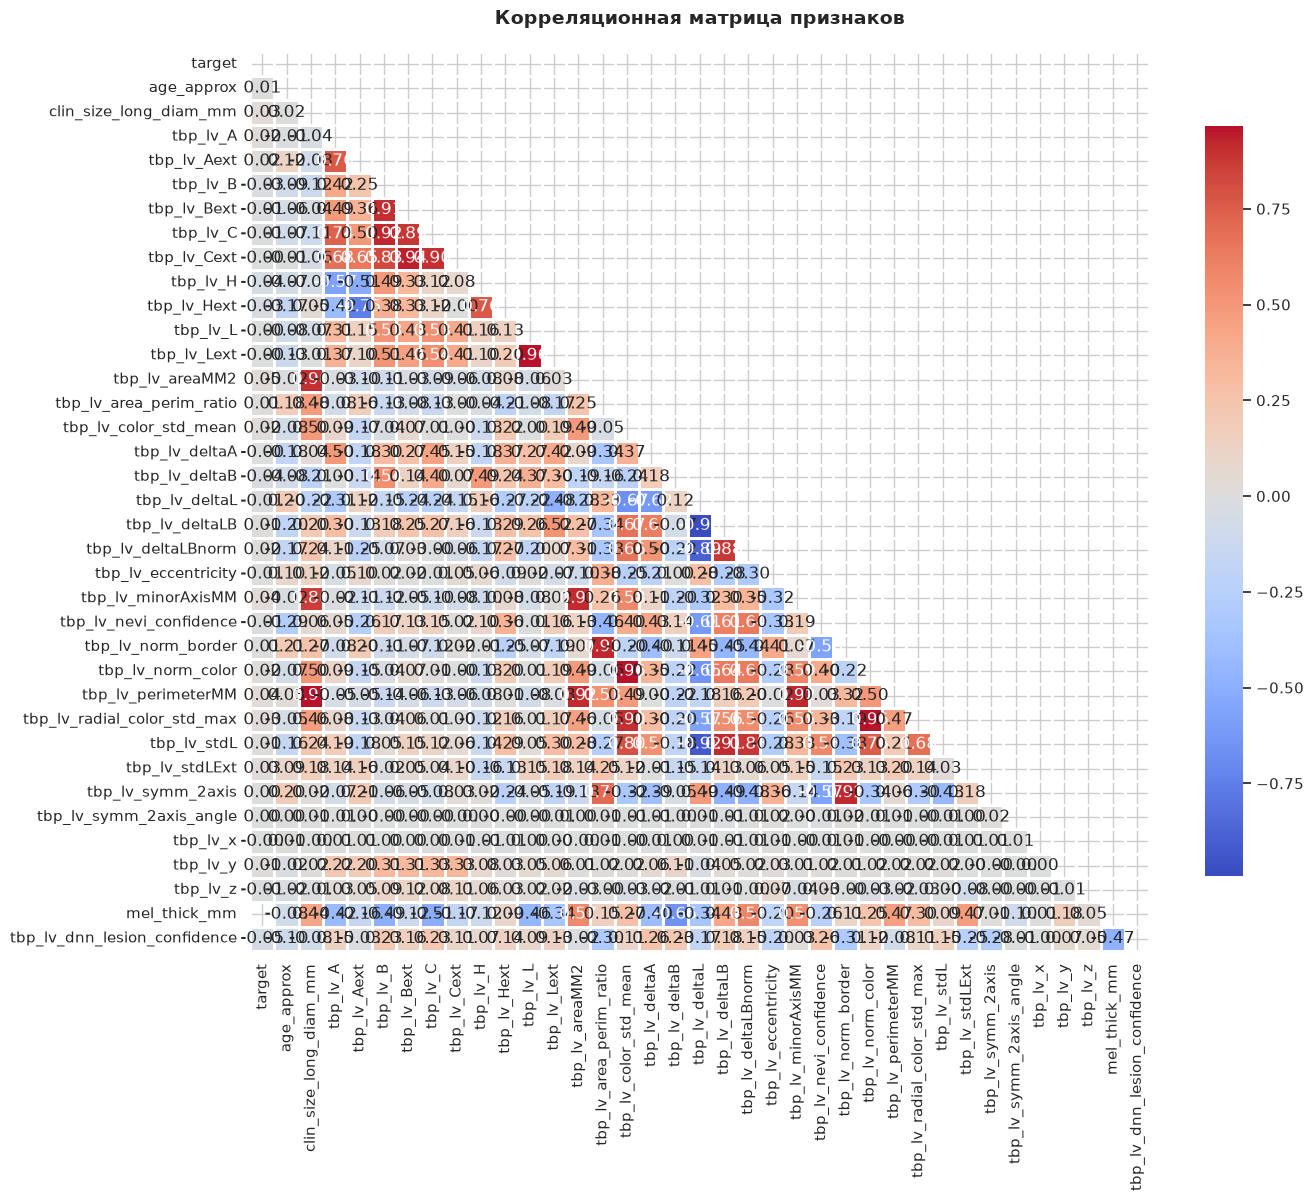


✅ График сохранен: train_correlation_matrix.png


In [124]:
if len(numeric_cols) > 1:
    print("\n" + "="*80)
    print("🔗 КОРРЕЛЯЦИОННЫЙ АНАЛИЗ")
    print("="*80)

    # Подготовка данных
    df_numeric = df_train[numeric_cols].copy()

    # Кодируем target если есть
    if target_col in df_train.columns and target_col not in numeric_cols:
        le = LabelEncoder()
        df_numeric[f'{target_col}_encoded'] = le.fit_transform(df_train[target_col].fillna('Unknown'))

    # Расчет корреляции
    corr_matrix = df_numeric.corr()

    # Визуализация
    plt.figure(figsize=(14, 12))
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
                center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
    plt.title('Корреляционная матрица признаков', fontweight='bold', fontsize=14, pad=20)
    plt.tight_layout()
    plt.savefig('train_correlation_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Топ коррелирующих с target
    if f'{target_col}_encoded' in corr_matrix.columns:
        target_corr = corr_matrix[f'{target_col}_encoded'].drop(f'{target_col}_encoded').abs().sort_values(ascending=False)

        print(f"\n📊 Топ-10 признаков, коррелирующих с {target_col}:")
        for i, (feat, corr_val) in enumerate(target_corr.head(10).items(), 1):
            direction = "положительная" if corr_matrix.loc[feat, f'{target_col}_encoded'] > 0 else "отрицательная"
            print(f"   {i}. {feat}: {corr_val:.4f} ({direction})")

        important_features = target_corr[target_corr > 0.1].index.tolist()
        if len(important_features) > 0:
            print(f"\n✅ Признаки с корреляцией >0.1: {', '.join(important_features)}")
        else:
            print("\n💡 Нет признаков с сильной корреляцией (>0.1)")
            print("   Это НОРМАЛЬНО для CV задач - паттерны в изображениях важнее метаданных")

    print("\n✅ График сохранен: train_correlation_matrix.png")
else:
    print("\n⚠️ Недостаточно числовых признаков для корреляционного анализа")


## 7.5 🔬 KS-TEST TBP-ПРИЗНАКОВ: BENIGN vs MALIGNANT

**Цель:** определить, какие из 43 TBP-признаков статистически значимо различаются между benign и malignant.
Это позволяет отобрать наиболее информативные признаки для модели.
Используем двухвыборочный тест Колмогорова-Смирнова (KS-test) — он НЕ предполагает нормальность распределения.


In [125]:
# Check dtype for sparse columns (in case they contain strings, not floats)
for sparse_col in ['mel_mitotic_index', 'mel_thick_mm']:
    if sparse_col in df_train.columns:
        col = df_train[sparse_col]
        non_null = col.dropna()
        print(f"   * {sparse_col}: dtype={col.dtype}, unique non-null values={non_null.nunique()}")
        
        # Try numeric conversion regardless of dtype
        numeric_vals = pd.to_numeric(non_null, errors='coerce').dropna()
        
        if len(numeric_vals) == 0:
            print(f"     WARNING: {sparse_col} has no numeric values! Sample values:")
            print(f"     {non_null.head(10).tolist()}")
        else:
            print(f"     min={numeric_vals.min():.4f}, max={numeric_vals.max():.4f}")
            if len(numeric_vals) < len(non_null):
                print(f"     WARNING: {len(non_null) - len(numeric_vals)} non-numeric values detected (coerced to NaN)")


   * mel_mitotic_index: dtype=str, unique non-null values=7
     ['4/mm^2', '0/mm^2', '3/mm^2', '<1/mm^2', '0/mm^2', '<1/mm^2', '0/mm^2', '<1/mm^2', '2/mm^2', '1/mm^2']
   * mel_thick_mm: dtype=float64, unique non-null values=19
     min=0.2000, max=5.0000


In [126]:
# ==========================================
# KS-TEST ДЛЯ КАЖДОГО TBP-ПРИЗНАКА
# ==========================================
from scipy.stats import ks_2samp
# warnings already configured in imports cell
# Выделяем TBP-признаки (все float64 колонки, начинающиеся с 'tbp_lv_')
tbp_feature_cols = [c for c in df_train.columns if c.startswith('tbp_lv_') and df_train[c].dtype in ('float64', 'int64')]
# Исключаем координатные и неинформативные
tbp_feature_cols = [c for c in tbp_feature_cols if c not in ('tbp_lv_x', 'tbp_lv_y', 'tbp_lv_z', 'tbp_lv_symm_2axis_angle')]
print(f"🔍 Анализируем {len(tbp_feature_cols)} TBP-признаков\n")
# Разделяем данные на benign и malignant
mask_benign = df_train[target_col] == 0
mask_malignant = df_train[target_col] == 1
benign_data = df_train.loc[mask_benign, tbp_feature_cols]
malignant_data = df_train.loc[mask_malignant, tbp_feature_cols]
# KS-test для каждого признака
ks_results = []
for col in tbp_feature_cols:
    stat, p_value = ks_2samp(
        benign_data[col].dropna().values,
        malignant_data[col].dropna().values
    )
    # Cohen's d для размера эффекта
    mean_diff = malignant_data[col].mean() - benign_data[col].mean()
    pooled_std = np.sqrt((benign_data[col].std()**2 + malignant_data[col].std()**2) / 2)
    cohens_d = mean_diff / pooled_std if pooled_std > 0 else 0
    ks_results.append({
        'feature': col,
        'ks_statistic': stat,
        'p_value': p_value,
        'cohens_d': cohens_d,
        'benign_mean': benign_data[col].mean(),
        'malignant_mean': malignant_data[col].mean(),
        'mean_diff': mean_diff
    })
df_ks = pd.DataFrame(ks_results).sort_values('ks_statistic', ascending=False)
# Поправка Бонферрони
alpha_bonferroni = 0.05 / len(tbp_feature_cols)
df_ks['significant'] = df_ks['p_value'] < alpha_bonferroni
n_significant = df_ks['significant'].sum()
# ==========================================
# PERMUTATION BASELINE: какой KS-statistic считать значимым?
# ==========================================
# При 400K+ записей любой признак будет статистически значим.
# Нужно понять, какой KS-statistic является "большим" относительно случайного шума.
np.random.seed(42)
permuted_target = np.random.permutation(df_train[target_col].values)
perm_mask_benign = permuted_target == 0
perm_mask_malignant = permuted_target == 1
perm_ks_values = []
for col in tbp_feature_cols:
    stat, _ = ks_2samp(
        df_train.loc[perm_mask_benign, col].dropna().values,
        df_train.loc[perm_mask_malignant, col].dropna().values
    )
    perm_ks_values.append(stat)
perm_baseline_95 = np.percentile(perm_ks_values, 95)
perm_baseline_99 = np.percentile(perm_ks_values, 99)
perm_baseline_max = np.max(perm_ks_values)
print(f"\n📏 Permutation baseline (случайный target):")
print(f"   KS 95th percentile: {perm_baseline_95:.4f}")
print(f"   KS 99th percentile: {perm_baseline_99:.4f}")
print(f"   KS max: {perm_baseline_max:.4f}")
# Маркируем признаки, KS которых выше baseline
df_ks['above_perm_baseline'] = df_ks['ks_statistic'] > perm_baseline_99
n_above_baseline = df_ks['above_perm_baseline'].sum()
print(f"   Признаков выше пермутационного baseline (p99): {n_above_baseline}/{len(tbp_feature_cols)}")
print(f"📊 Результаты KS-test (α Бонферрони = {alpha_bonferroni:.2e}):")
print(f"   Статистически значимых признаков: {n_significant}/{len(tbp_feature_cols)}")
print(f"   Топ-5 признаков по KS-статистике:")
for i, row in df_ks.head(5).iterrows():
    print(f"   {row['feature']}: KS={row['ks_statistic']:.4f}, p={row['p_value']:.2e}, d={row['cohens_d']:.2f}")
print(f"\n   Незначимые признаки (p > {alpha_bonferroni:.2e}):")
non_sig = df_ks[~df_ks['significant']]
if len(non_sig) > 0:
    for _, row in non_sig.iterrows():
        print(f"   {row['feature']}: p={row['p_value']:.2e}")
else:
    print("   ✅ Все признаки статистически значимы!")


🔍 Анализируем 29 TBP-признаков


📏 Permutation baseline (случайный target):
   KS 95th percentile: 0.0570
   KS 99th percentile: 0.0681
   KS max: 0.0714
   Признаков выше пермутационного baseline (p99): 27/29
📊 Результаты KS-test (α Бонферрони = 1.72e-03):
   Статистически значимых признаков: 24/29
   Топ-5 признаков по KS-статистике:
   tbp_lv_H: KS=0.4903, p=1.15e-87, d=-1.19
   tbp_lv_deltaB: KS=0.3907, p=1.52e-54, d=-0.91
   tbp_lv_minorAxisMM: KS=0.3853, p=5.30e-53, d=0.65
   tbp_lv_areaMM2: KS=0.3659, p=1.16e-47, d=0.68
   tbp_lv_perimeterMM: KS=0.3629, p=6.82e-47, d=0.65

   Незначимые признаки (p > 1.72e-03):
   tbp_lv_norm_border: p=2.98e-03
   tbp_lv_symm_2axis: p=2.72e-02
   tbp_lv_L: p=2.98e-02
   tbp_lv_Lext: p=3.62e-01
   tbp_lv_Cext: p=4.98e-01


/tmp/ipykernel_19139/3153779776.py:42: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_19139/3153779776.py:43: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  plt.savefig('train_tbp_ks_test.png', dpi=300, bbox_inches='tight')
/home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


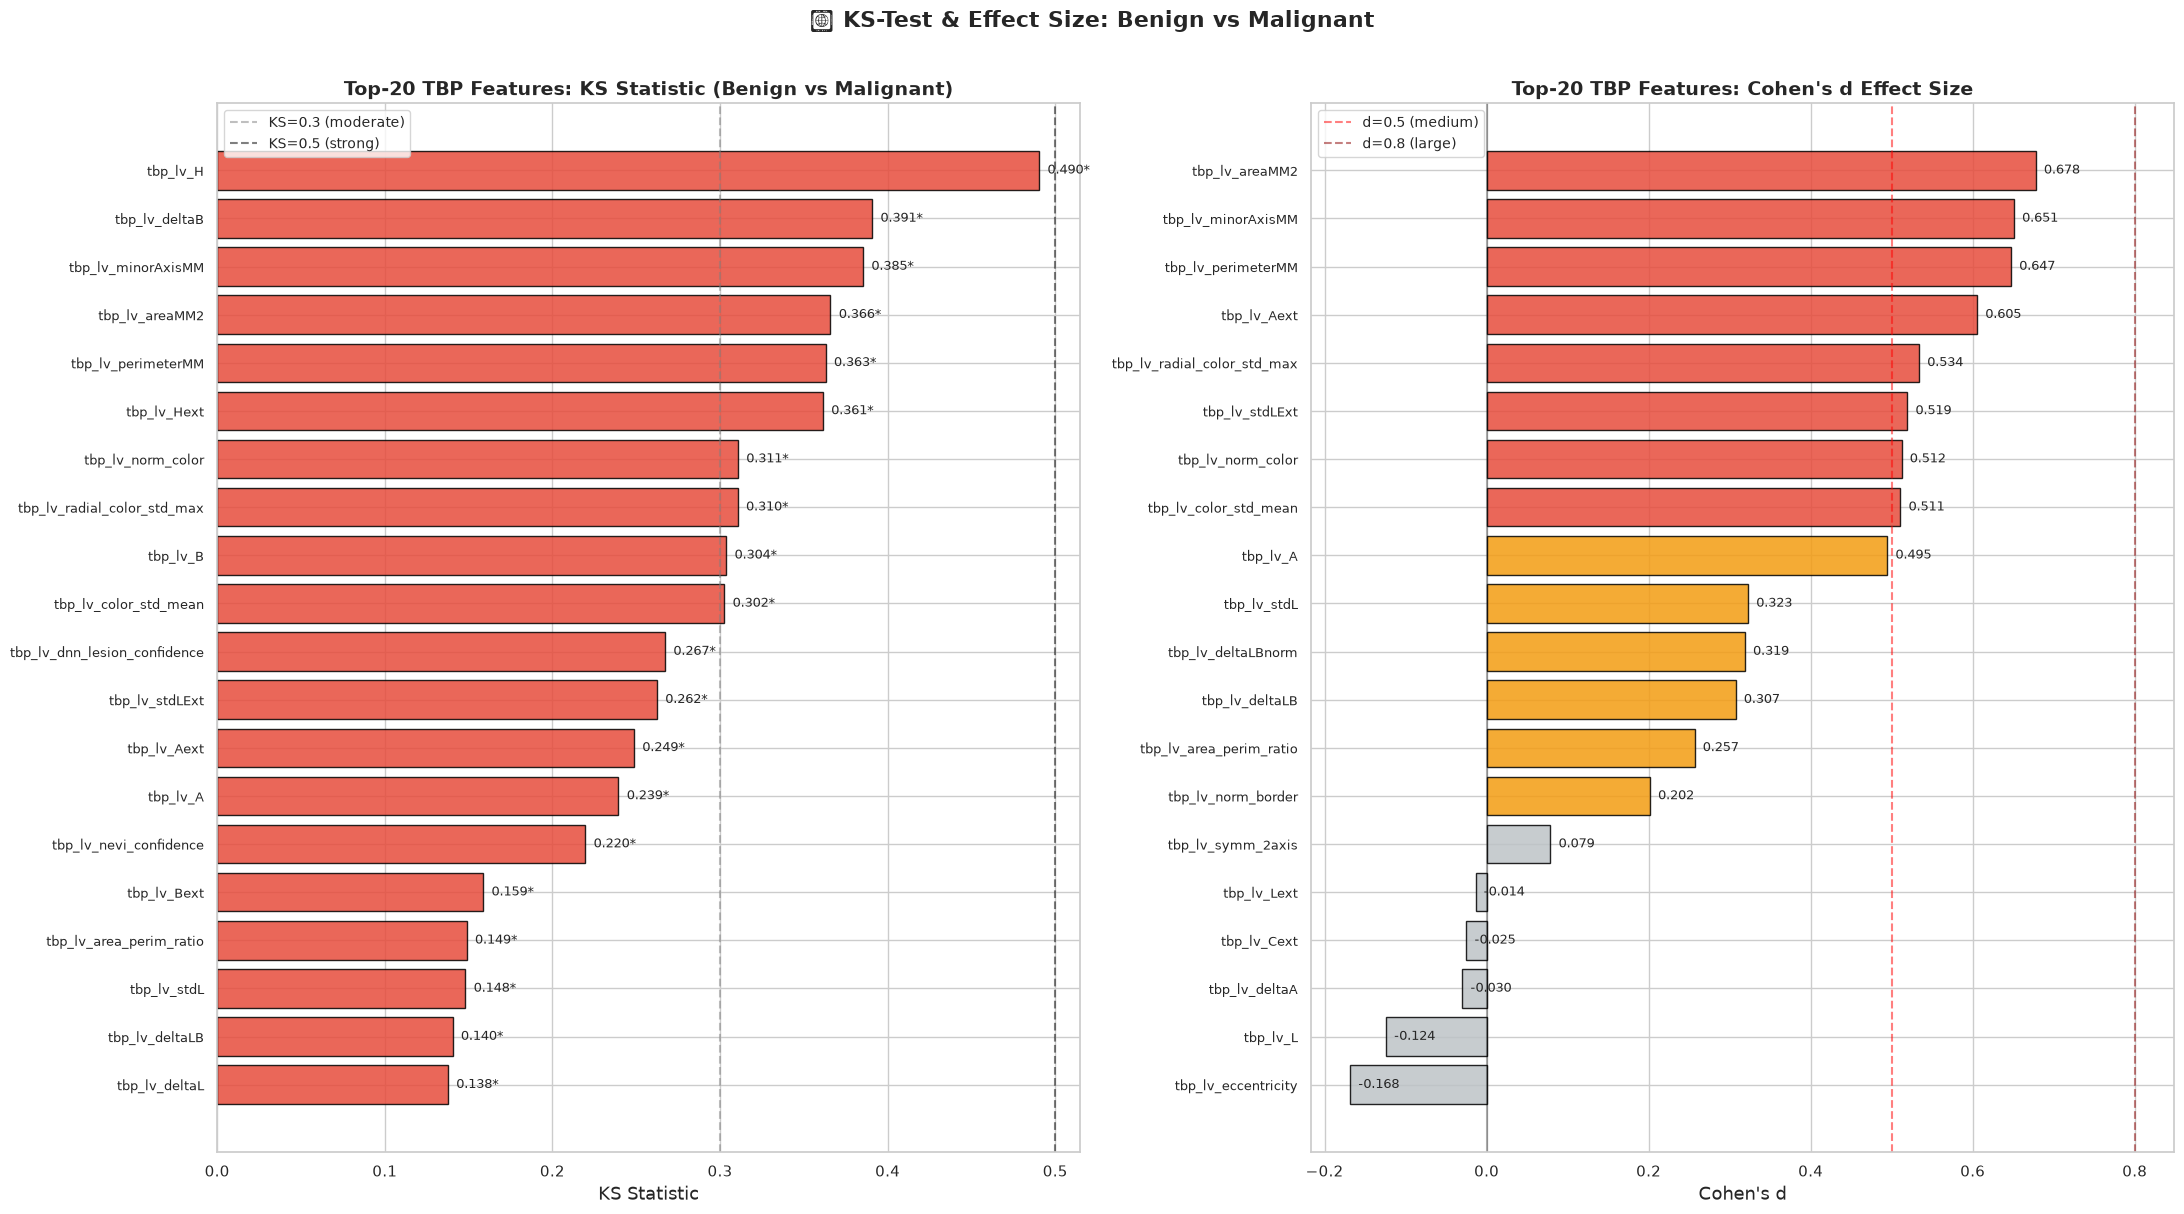

✅ Результаты сохранены в tbp_features_ks_test.csv


In [127]:
# ==========================================
# ВИЗУАЛИЗАЦИЯ: TOP-20 ПРИЗНАКОВ ПО KS-STATISTIC
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(22, 12))

# График 1: KS-statistic для top-20 признаков
top_ks = df_ks.head(20).iloc[::-1]  # переворачиваем для горизонтального barh
colors_ks = ['#e74c3c' if sig else '#bdc3c7' for sig in top_ks['significant']]

axes[0].barh(range(len(top_ks)), top_ks['ks_statistic'], color=colors_ks, edgecolor='black', alpha=0.85)
axes[0].set_yticks(range(len(top_ks)))
axes[0].set_yticklabels(top_ks['feature'], fontsize=9)
axes[0].set_xlabel('KS Statistic', fontsize=13)
axes[0].set_title('Top-20 TBP Features: KS Statistic (Benign vs Malignant)', fontsize=14, fontweight='bold')
axes[0].axvline(x=0.3, color='gray', linestyle='--', alpha=0.5, label='KS=0.3 (moderate)')
axes[0].axvline(x=0.5, color='black', linestyle='--', alpha=0.5, label='KS=0.5 (strong)')
axes[0].legend(fontsize=10)

# Добавляем значения
for i, (ks, sig) in enumerate(zip(top_ks['ks_statistic'], top_ks['significant'])):
    axes[0].text(ks + 0.005, i, f'{ks:.3f}{"*" if sig else ""}', va='center', fontsize=9)

# График 2: Cohen's d для top-20
top_d = df_ks.nlargest(20, 'cohens_d').iloc[::-1]
colors_d = ['#e74c3c' if abs(d) > 0.5 else '#f39c12' if abs(d) > 0.2 else '#bdc3c7' for d in top_d['cohens_d']]

axes[1].barh(range(len(top_d)), top_d['cohens_d'], color=colors_d, edgecolor='black', alpha=0.85)
axes[1].set_yticks(range(len(top_d)))
axes[1].set_yticklabels(top_d['feature'], fontsize=9)
axes[1].set_xlabel("Cohen's d", fontsize=13)
axes[1].set_title("Top-20 TBP Features: Cohen's d Effect Size", fontsize=14, fontweight='bold')
axes[1].axvline(x=0, color='black', linestyle='-', alpha=0.3)
axes[1].axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='d=0.5 (medium)')
axes[1].axvline(x=0.8, color='darkred', linestyle='--', alpha=0.5, label='d=0.8 (large)')
axes[1].legend(fontsize=10)

for i, d in enumerate(top_d['cohens_d']):
    axes[1].text(d + 0.01, i, f'{d:.3f}', va='center', fontsize=9)

plt.suptitle('🔬 KS-Test & Effect Size: Benign vs Malignant', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('train_tbp_ks_test.png', dpi=300, bbox_inches='tight')
plt.show()

# Сохраняем результаты
df_ks.to_csv(os.path.join(PROCESSED_DIR, 'tbp_features_ks_test.csv'), index=False)
print("✅ Результаты сохранены в tbp_features_ks_test.csv")


/tmp/ipykernel_19139/4068106537.py:26: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_19139/4068106537.py:27: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  plt.savefig('train_tbp_top6_boxplots.png', dpi=300, bbox_inches='tight')
/home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


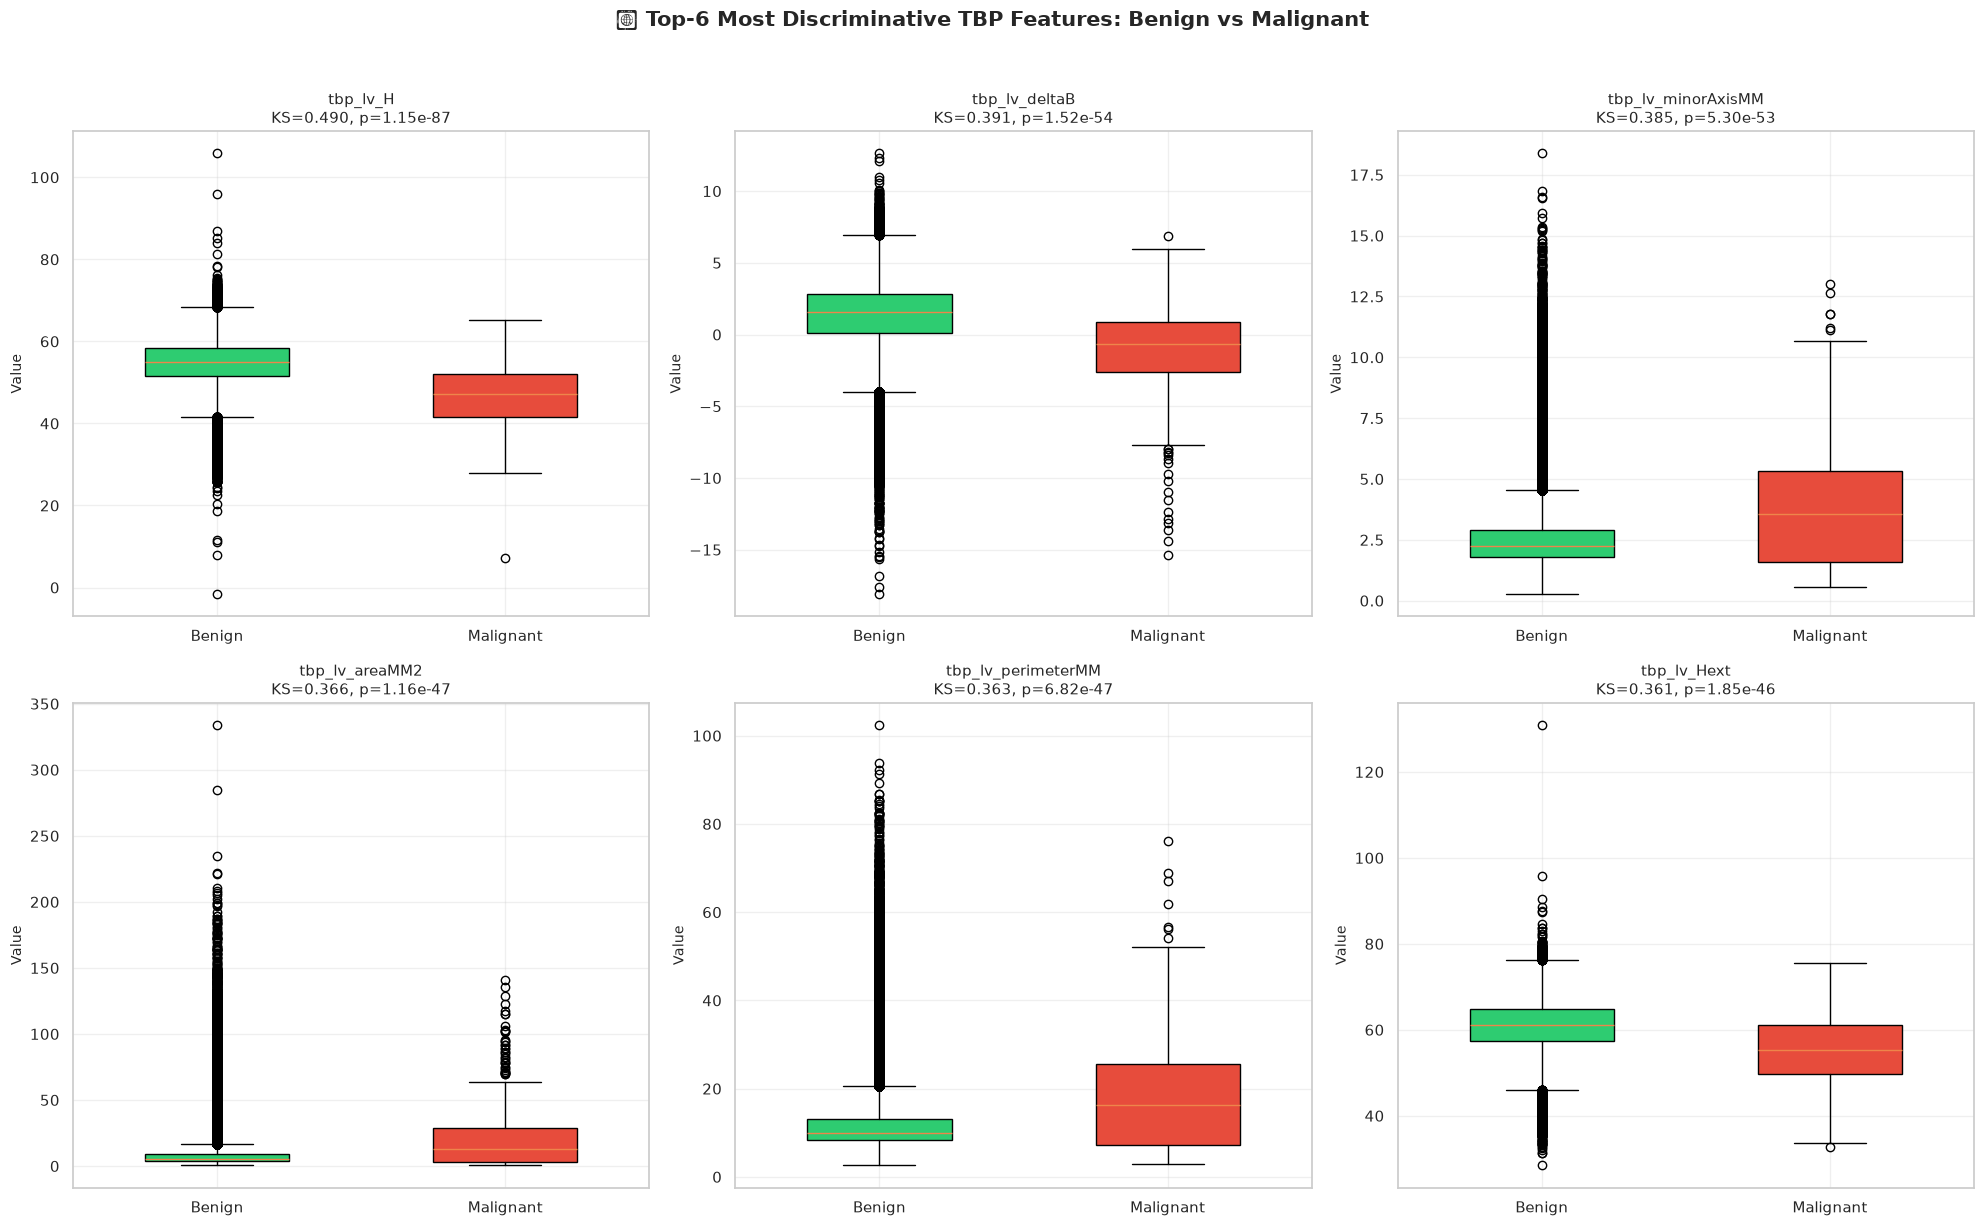

In [128]:
# ==========================================
# BOXPLOTS: TOP-6 НАИБОЛЕЕ РАЗЛИЧАЮЩИХСЯ ПРИЗНАКОВ
# ==========================================

top6_features = df_ks.head(6)['feature'].tolist()

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i, feat in enumerate(top6_features):
    data_to_plot = [
        benign_data[feat].dropna().values,
        malignant_data[feat].dropna().values
    ]
    bp = axes[i].boxplot(data_to_plot, tick_labels=['Benign', 'Malignant'],
                         patch_artist=True, widths=0.5)
    bp['boxes'][0].set_facecolor('#2ecc71')
    bp['boxes'][1].set_facecolor('#e74c3c')
    axes[i].set_title(f'{feat}\nKS={df_ks.iloc[i]["ks_statistic"]:.3f}, p={df_ks.iloc[i]["p_value"]:.2e}',
                      fontsize=11)
    axes[i].set_ylabel('Value', fontsize=10)
    axes[i].grid(True, alpha=0.3)

plt.suptitle('🔬 Top-6 Most Discriminative TBP Features: Benign vs Malignant',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('train_tbp_top6_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()


### 📊 Выводы KS-test:

- **Если все признаки значимы** → TBP-признаки отлично разделяют классы, используем все в модели
- **Если есть незначимые** → исключаем их из feature set для уменьшения шума
- **Cohen's d > 0.8** → признак имеет сильный практический эффект (рекомендуется для модели)
- **Cohen's d < 0.2** → признак имеет слабый эффект (можно исключить)


## 7.6 🌲 FEATURE IMPORTANCE (RANDOM FOREST) НА TBP-ПРИЗНАКАХ

**Цель:** определить, какие TBP-признаки наиболее важны для предсказания malignant.
Используем Random Forest с class_weight='balanced' для компенсации дисбаланса 1:1019.
**Это критичный анализ для выбора признаков при обучении модели.**


In [129]:
# ==========================================
# RANDOM FOREST FEATURE IMPORTANCE
# ==========================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score
print("🌲 Обучение Random Forest на TBP-признаках...\n")
# Подготовка признаков (только TBP, без координат)
X = df_train[tbp_feature_cols].copy()
y = df_train[target_col].values
# Проверка на NaN
nan_mask = X.isna().any(axis=1)
if nan_mask.any():
    print(f"⚠️ Найдено {nan_mask.sum()} строк с NaN, заполняем медианой")
    X = X.fillna(X.median())
print(f"📊 Размерность: {X.shape[0]:,} образцов × {X.shape[1]} признаков")
print(f"   Malignant: {y.sum()} ({100*y.sum()/len(y):.2f}%)")
# Random Forest с балансировкой классов и ограничением глубины
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=GLOBAL_RANDOM_SEED,  # Fixed for reproducibility
    n_jobs=-1
)
rf.fit(X, y)
# ==========================================
# 1. ВСТРОЕННАЯ ВАЖНОСТЬ (MDI — Mean Decrease in Impurity)
# ==========================================
feature_importance_mdi = pd.DataFrame({
    'feature': tbp_feature_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)
# Кумулятивная важность
feature_importance_mdi['cumulative_importance'] = feature_importance_mdi['importance'].cumsum()
# Признаки для 95% важности
top_95_cutoff = feature_importance_mdi[feature_importance_mdi['cumulative_importance'] <= 0.95]
n_top_95 = len(top_95_cutoff)
print(f"\n📊 MDI Feature Importance (один RF):")
print(f"   Признаков для 95% важности: {n_top_95}/{len(tbp_feature_cols)}")
print(f"   Топ-10:")
for i, row in feature_importance_mdi.head(10).iterrows():
    print(f"   {row['feature']}: {row['importance']:.4f} (cumul: {row['cumulative_importance']:.3f})")
# ==========================================
# 2. PERMUTATION IMPORTANCE С БУТСТРАПОМ (10 повторов)
# ==========================================
from sklearn.inspection import permutation_importance
print("\n🔄 Permutation Importance (10 repeats) — вычисляется...")
perm_importances = []
for seed in tqdm(range(10), desc="Permutation repeats"):
    pi = permutation_importance(
        rf, X, y,
        n_repeats=1,
        random_state=seed,
        n_jobs=-1,
        scoring='roc_auc'
    )
    perm_importances.append(pi.importances_mean)
perm_importances = np.array(perm_importances)  # shape: (10, n_features)
perm_mean = perm_importances.mean(axis=0)
perm_std = perm_importances.std(axis=0)
feature_importance_perm = pd.DataFrame({
    'feature': tbp_feature_cols,
    'importance_mean': perm_mean,
    'importance_std': perm_std,
    'importance_cv': perm_std / (perm_mean + 1e-10)  # коэффициент вариации
}).sort_values('importance_mean', ascending=False)
# Стабильные признаки: CV < 0.3
feature_importance_perm['stable'] = feature_importance_perm['importance_cv'] < 0.3
n_stable = feature_importance_perm['stable'].sum()
print(f"\n📊 Permutation Importance (10 repeats):")
print(f"   Стабильных признаков (CV < 0.3): {n_stable}/{len(tbp_feature_cols)}")
print(f"   Топ-10:")
for _, row in feature_importance_perm.head(10).iterrows():
    star = '★' if row['stable'] else '?'
    print(f"   {star} {row['feature']}: {row['importance_mean']:.4f} ± {row['importance_std']:.4f} (CV={row['importance_cv']:.2f})")
# Используем permutation importance как основную оценку
feature_importance = feature_importance_perm.rename(columns={'importance_mean': 'importance'})
feature_importance['cumulative_importance'] = feature_importance['importance'].cumsum() / feature_importance['importance'].sum()
# Признаки для 95% важности (permutation-based)
top_95_perm = feature_importance[feature_importance['cumulative_importance'] <= 0.95]
n_top_95_perm = len(top_95_perm)
print(f"\n   Признаков для 95% важности (permutation): {n_top_95_perm}/{len(tbp_feature_cols)}")
print(f"\n📊 Итоговые результаты Random Forest:")
print(f"   MDI: признаков для 95% важности: {n_top_95}/{len(tbp_feature_cols)}")
print(f"   Permutation: признаков для 95% важности: {n_top_95_perm}/{len(tbp_feature_cols)}")
print(f"   Стабильных признаков (CV<0.3): {n_stable}/{len(tbp_feature_cols)}")
print(f"   Топ-10 признаков (permutation importance):")
for _, row in feature_importance.head(10).iterrows():
    print(f"   {row['feature']}: {row['importance']:.4f} ± {row.get('importance_std', 0):.4f}")
# Быстрая кросс-валидация (3-fold для скорости)
from sklearn.model_selection import StratifiedKFold
cv_scores = cross_val_score(rf, X, y, cv=StratifiedKFold(3, shuffle=True, random_state=GLOBAL_RANDOM_SEED),  # Fixed for reproducibility
                            scoring='roc_auc', n_jobs=-1)
print(f"\n   ROC-AUC (3-fold CV): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")


🌲 Обучение Random Forest на TBP-признаках...

📊 Размерность: 401,059 образцов × 29 признаков
   Malignant: 393 (0.10%)

📊 MDI Feature Importance (один RF):
   Признаков для 95% важности: 24/29
   Топ-10:
   tbp_lv_H: 0.1359 (cumul: 0.136)
   tbp_lv_perimeterMM: 0.0898 (cumul: 0.226)
   tbp_lv_areaMM2: 0.0805 (cumul: 0.306)
   tbp_lv_minorAxisMM: 0.0773 (cumul: 0.383)
   tbp_lv_Hext: 0.0527 (cumul: 0.436)
   tbp_lv_deltaB: 0.0506 (cumul: 0.487)
   tbp_lv_norm_color: 0.0477 (cumul: 0.534)
   tbp_lv_color_std_mean: 0.0411 (cumul: 0.576)
   tbp_lv_radial_color_std_max: 0.0399 (cumul: 0.615)
   tbp_lv_deltaLBnorm: 0.0360 (cumul: 0.651)

🔄 Permutation Importance (10 repeats) — вычисляется...


Permutation repeats: 100%|██████████| 10/10 [03:06<00:00, 18.61s/it]



📊 Permutation Importance (10 repeats):
   Стабильных признаков (CV < 0.3): 29/29
   Топ-10:
   ★ tbp_lv_H: 0.0094 ± 0.0006 (CV=0.06)
   ★ tbp_lv_Hext: 0.0034 ± 0.0002 (CV=0.05)
   ★ tbp_lv_dnn_lesion_confidence: 0.0031 ± 0.0002 (CV=0.05)
   ★ tbp_lv_nevi_confidence: 0.0027 ± 0.0001 (CV=0.05)
   ★ tbp_lv_perimeterMM: 0.0024 ± 0.0000 (CV=0.02)
   ★ tbp_lv_deltaB: 0.0022 ± 0.0001 (CV=0.05)
   ★ tbp_lv_areaMM2: 0.0020 ± 0.0001 (CV=0.03)
   ★ tbp_lv_minorAxisMM: 0.0019 ± 0.0000 (CV=0.02)
   ★ tbp_lv_deltaLB: 0.0019 ± 0.0002 (CV=0.11)
   ★ tbp_lv_B: 0.0017 ± 0.0001 (CV=0.06)

   Признаков для 95% важности (permutation): 23/29

📊 Итоговые результаты Random Forest:
   MDI: признаков для 95% важности: 24/29
   Permutation: признаков для 95% важности: 23/29
   Стабильных признаков (CV<0.3): 29/29
   Топ-10 признаков (permutation importance):
   tbp_lv_H: 0.0094 ± 0.0006
   tbp_lv_Hext: 0.0034 ± 0.0002
   tbp_lv_dnn_lesion_confidence: 0.0031 ± 0.0002
   tbp_lv_nevi_confidence: 0.0027 ± 0.0001
  

/tmp/ipykernel_19139/1976474485.py:34: UserWarning: Glyph 127794 (\N{EVERGREEN TREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_19139/1976474485.py:35: UserWarning: Glyph 127794 (\N{EVERGREEN TREE}) missing from font(s) DejaVu Sans.
  plt.savefig('train_rf_feature_importance.png', dpi=300, bbox_inches='tight')
/home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 127794 (\N{EVERGREEN TREE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


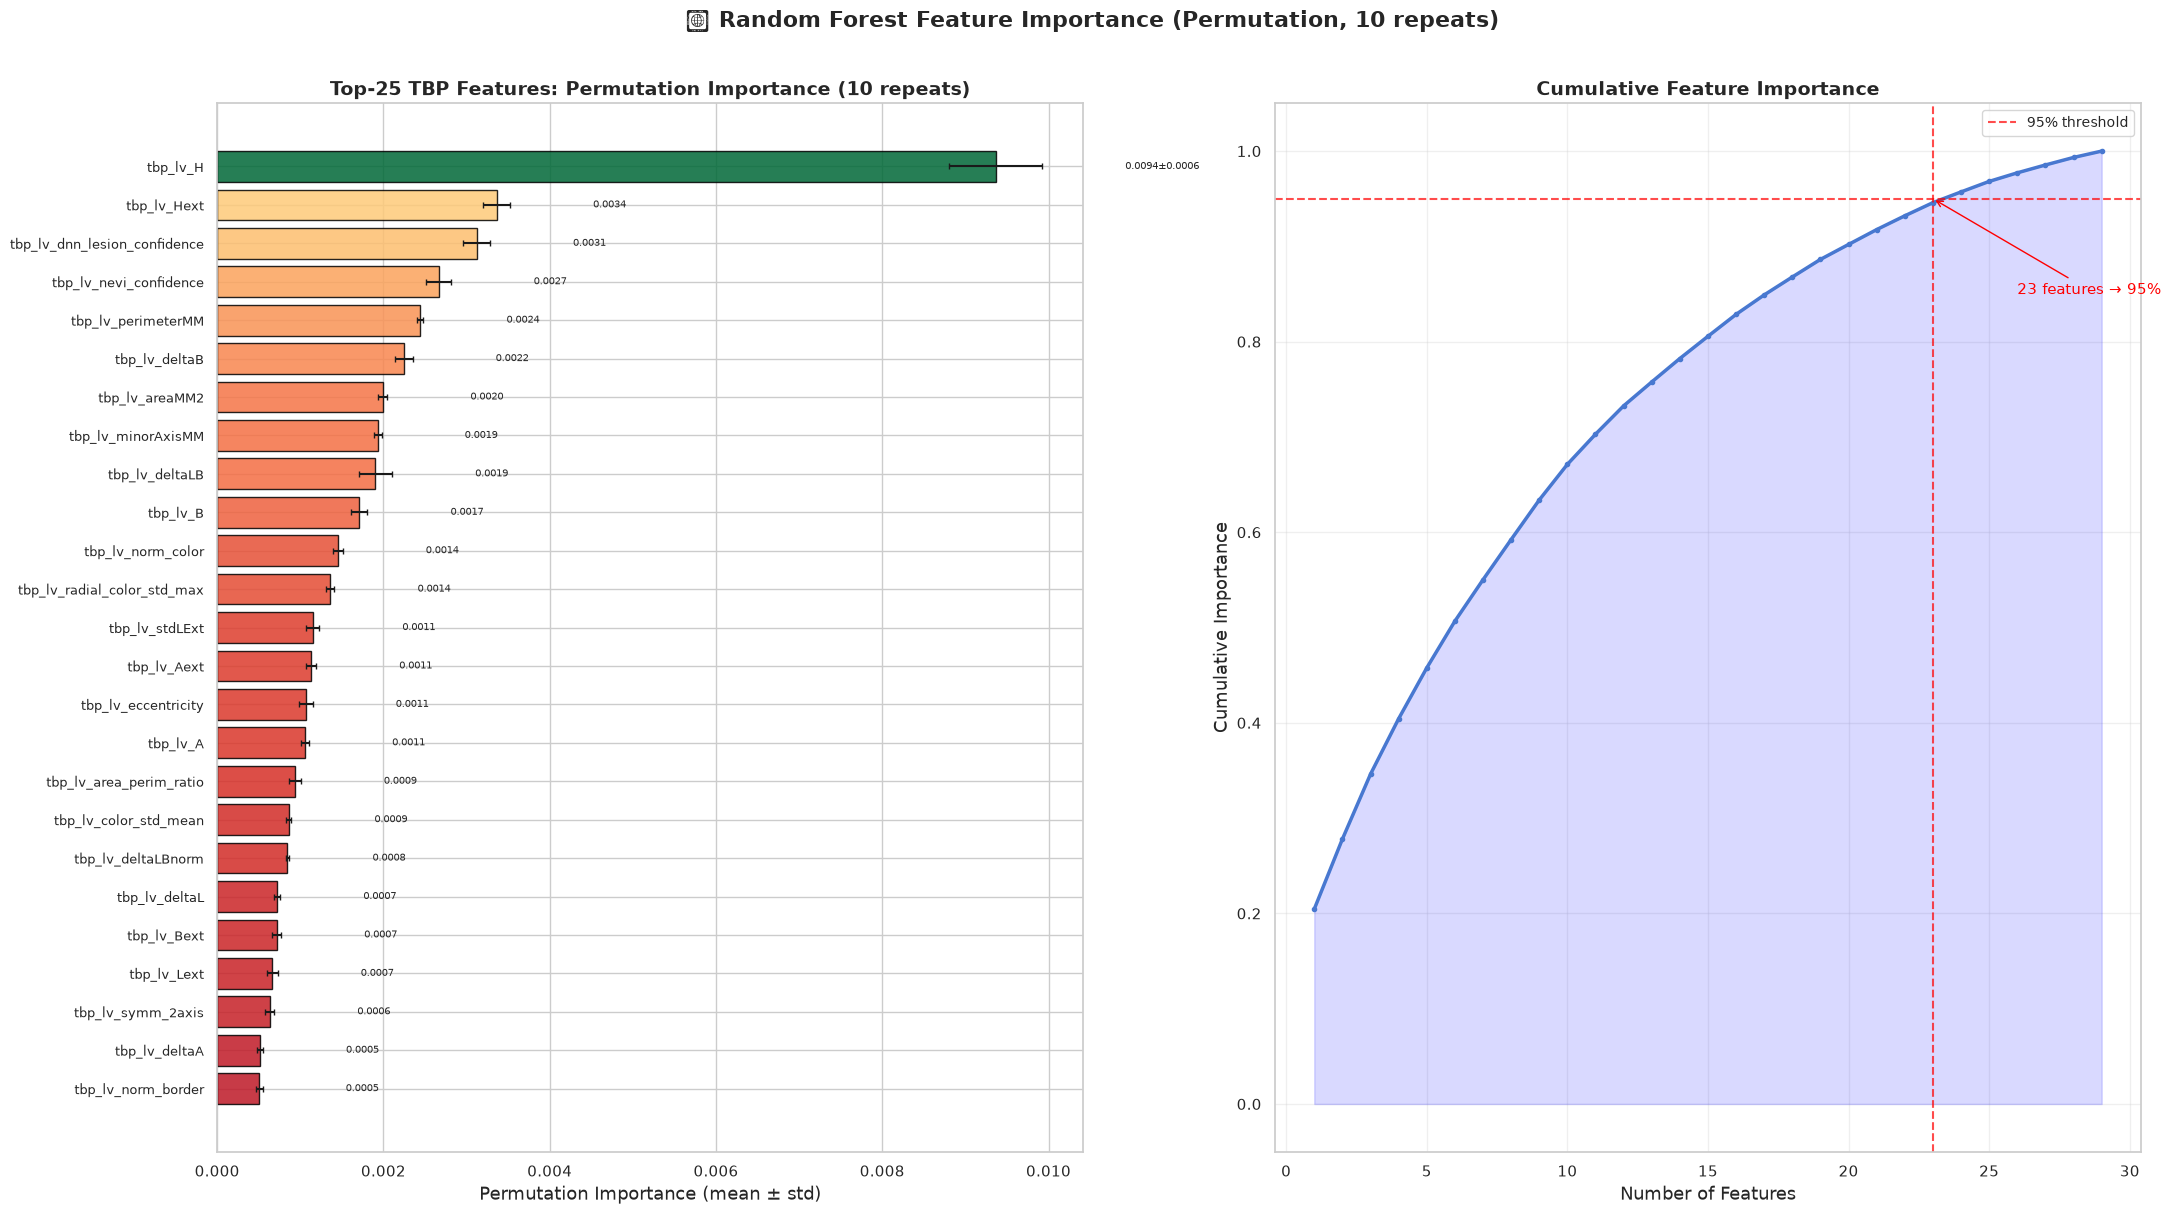

✅ Feature importance сохранена:
   - tbp_features_importance_mdi.csv (встроенная MDI)
   - tbp_features_importance_permutation.csv (пермутационная, 10 repeats)


In [130]:
# ==========================================
# ВИЗУАЛИЗАЦИЯ FEATURE IMPORTANCE
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(22, 12))
# График 1: Top-25 Feature Importance (Permutation, mean ± std)
top25 = feature_importance.head(25).iloc[::-1]
colors_imp = plt.cm.RdYlGn(top25['importance'] / top25['importance'].max())
axes[0].barh(range(len(top25)), top25['importance'],
             xerr=top25['importance_std'].values if 'importance_std' in top25.columns else None,
             color=colors_imp, edgecolor='black', alpha=0.85, capsize=2)
axes[0].set_yticks(range(len(top25)))
axes[0].set_yticklabels(top25['feature'], fontsize=9)
axes[0].set_xlabel('Permutation Importance (mean \u00b1 std)', fontsize=13)
axes[0].set_title('Top-25 TBP Features: Permutation Importance (10 repeats)', fontsize=14, fontweight='bold')
for i, (imp, std_val) in enumerate(zip(top25['importance'], top25.get('importance_std', [0]*25))):
    label = f'{imp:.4f}\u00b1{std_val:.4f}' if std_val > 0.0005 else f'{imp:.4f}'
    axes[0].text(imp + std_val + 0.001, i, label, va='center', fontsize=7)
# График 2: Cumulative Importance (Permutation)
axes[1].plot(range(1, len(feature_importance) + 1), feature_importance['cumulative_importance'],
             'b-', linewidth=2.5, marker='o', markersize=3)
axes[1].axhline(y=0.95, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='95% threshold')
axes[1].axvline(x=n_top_95_perm, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].fill_between(range(1, len(feature_importance) + 1), 0, feature_importance['cumulative_importance'],
                     alpha=0.15, color='blue')
axes[1].annotate(f'{n_top_95_perm} features → 95%', xy=(n_top_95_perm, 0.95),
                xytext=(n_top_95_perm + 3, 0.85),
                arrowprops=dict(arrowstyle='->', color='red'), fontsize=11, color='red')
axes[1].set_xlabel('Number of Features', fontsize=13)
axes[1].set_ylabel('Cumulative Importance', fontsize=13)
axes[1].set_title('Cumulative Feature Importance', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)
plt.suptitle('🌲 Random Forest Feature Importance (Permutation, 10 repeats)', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('train_rf_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
# Сохраняем
# Сохраняем обе версии
feature_importance_mdi.to_csv(os.path.join(PROCESSED_DIR, 'tbp_features_importance_mdi.csv'), index=False)
feature_importance_perm.to_csv('tbp_features_importance_permutation.csv', index=False)
print("✅ Feature importance сохранена:")
print("   - tbp_features_importance_mdi.csv (встроенная MDI)")
print("   - tbp_features_importance_permutation.csv (пермутационная, 10 repeats)")


### 🌲 Выводы Feature Importance:

- **Признаки, дающие 95% важности**, — это минимальный набор для эффективной модели
- **Признаки с importance < 0.01** можно исключить без существенной потери качества
- **Random Forest ROC-AUC** даёт baseline для сравнения с deep learning моделями
- Если RF показывает ROC-AUC > 0.80 на TBP-признаках, то метаданные несут сильный сигнал и их стоит объединять с image features (multi-modal подход)

- **Permutation importance с 10 повторами** — более надёжная оценка, чем встроенная MDI. Признаки с CV > 0.3 — нестабильны, их вклад зависит от random seed.
- **Если MDI и Permutation importance ранжируют признаки по-разному** → доверять permutation (она не зависит от структуры дерева).


## 7.6.5 📐 VIF-АНАЛИЗ МУЛЬТИКОЛЛИНЕАРНОСТИ TBP-ПРИЗНАКОВ

**Цель:** 43 TBP-признака потенциально высококоррелированы.
VIF (Variance Inflation Factor) показывает, насколько раздута дисперсия оценок
из-за линейной зависимости между признаками. VIF > 10 → критическая мультиколлинеарность.


📐 Вычисление VIF для TBP-признаков...

📊 Результаты VIF-анализа:
   VIF > 10 (критическая): 25/29
   5 < VIF ≤ 10 (средняя): 0/29
   Топ-5 по VIF:
   tbp_lv_A: VIF=inf, R²=1.0000
   tbp_lv_Aext: VIF=inf, R²=1.0000
   tbp_lv_B: VIF=inf, R²=1.0000
   tbp_lv_Bext: VIF=inf, R²=1.0000
   tbp_lv_L: VIF=inf, R²=1.0000


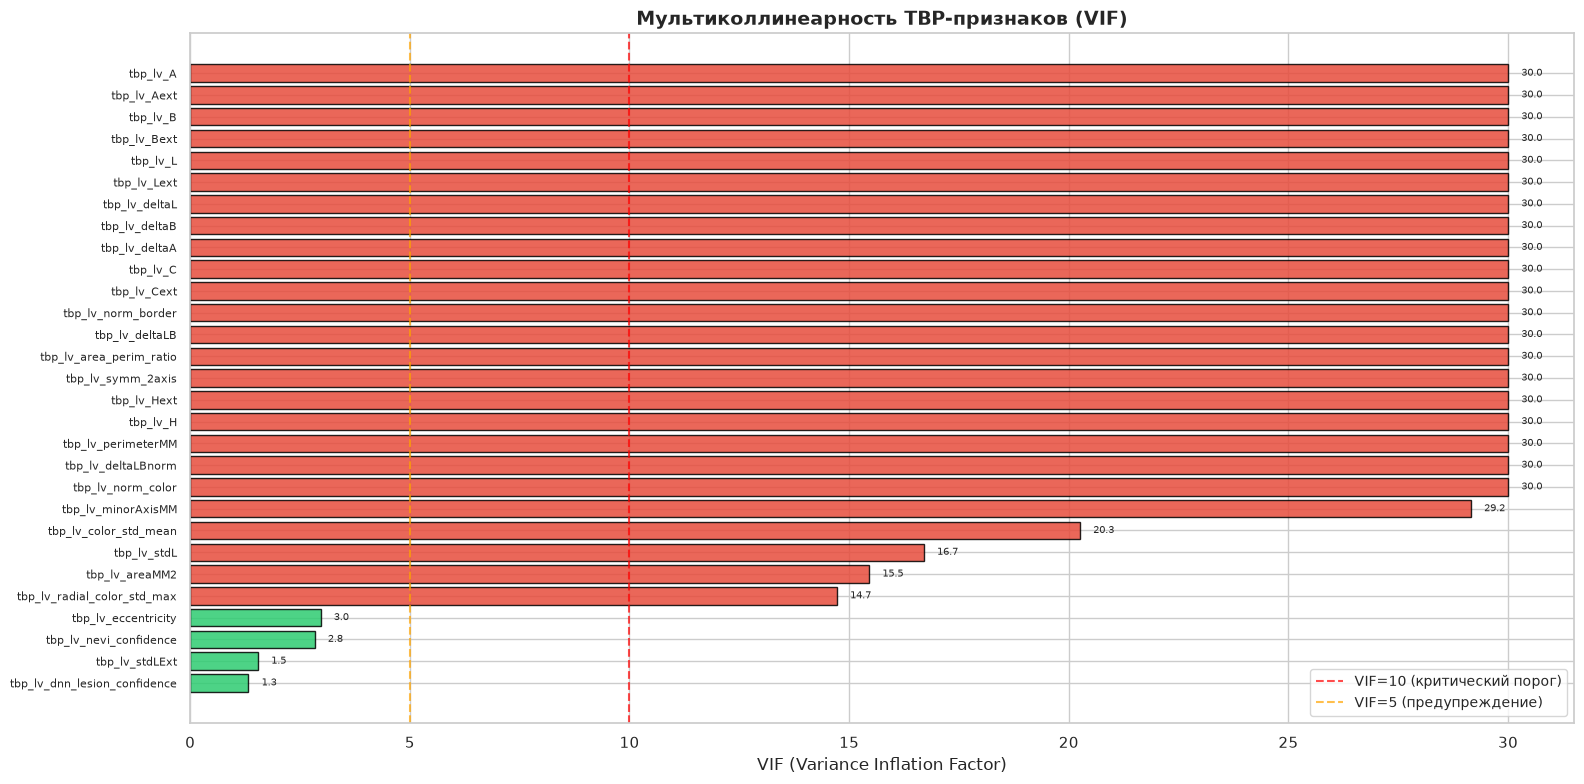

✅ VIF сохранён в tbp_features_vif.csv


In [131]:
# ==========================================
# VIF АНАЛИЗ МУЛЬТИКОЛЛИНЕАРНОСТИ
# ==========================================
from sklearn.linear_model import LinearRegression
def calculate_vif(X):
    """Вычисляет VIF для каждого признака в DataFrame."""
    vif_data = []
    for i, col in enumerate(X.columns):
        y_reg = X[col].values
        X_reg = X.drop(columns=[col]).values
        reg = LinearRegression()
        reg.fit(X_reg, y_reg)
        r2 = reg.score(X_reg, y_reg)
        vif = 1.0 / (1.0 - r2) if r2 < 0.999 else np.inf
        vif_data.append({'feature': col, 'vif': vif, 'r2': r2})
    return pd.DataFrame(vif_data).sort_values('vif', ascending=False)
print("📐 Вычисление VIF для TBP-признаков...")
X_vif = X.copy()
df_vif = calculate_vif(X_vif)
# Категоризация
df_vif['severity'] = pd.cut(
    df_vif['vif'].clip(upper=50),
    bins=[0, 5, 10, 50],
    labels=['Низкая', 'Средняя', 'Высокая']
)
n_high = (df_vif['vif'] > 10).sum()
n_moderate = ((df_vif['vif'] > 5) & (df_vif['vif'] <= 10)).sum()
print(f"\n📊 Результаты VIF-анализа:")
print(f"   VIF > 10 (критическая): {n_high}/{len(tbp_feature_cols)}")
print(f"   5 < VIF ≤ 10 (средняя): {n_moderate}/{len(tbp_feature_cols)}")
print(f"   Топ-5 по VIF:")
for _, row in df_vif.head(5).iterrows():
    print(f"   {row['feature']}: VIF={row['vif']:.1f}, R²={row['r2']:.4f}")
# Визуализация
fig, ax = plt.subplots(figsize=(16, 8))
top_vif = df_vif.head(30).iloc[::-1]
colors_vif = ['#e74c3c' if v > 10 else '#f39c12' if v > 5 else '#2ecc71' for v in top_vif['vif']]
ax.barh(range(len(top_vif)), top_vif['vif'].clip(upper=30), color=colors_vif, edgecolor='black', alpha=0.85)
ax.set_yticks(range(len(top_vif)))
ax.set_yticklabels(top_vif['feature'], fontsize=8)
ax.axvline(x=10, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='VIF=10 (критический порог)')
ax.axvline(x=5, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='VIF=5 (предупреждение)')
ax.set_xlabel('VIF (Variance Inflation Factor)', fontsize=12)
ax.set_title('Мультиколлинеарность TBP-признаков (VIF)', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
for i, vif_val in enumerate(top_vif['vif'].clip(upper=30)):
    ax.text(vif_val + 0.3, i, f'{vif_val:.1f}', va='center', fontsize=7)
plt.tight_layout()
plt.savefig('train_tbp_vif_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
df_vif.to_csv(os.path.join(PROCESSED_DIR, 'tbp_features_vif.csv'), index=False)
print("✅ VIF сохранён в tbp_features_vif.csv")


### 📐 Выводы VIF-анализа:

- **Признаки с VIF > 10** — критическая мультиколлинеарность. Для линейных моделей (логистическая регрессия) их нужно исключить или использовать регуляризацию (L1/L2).
- **Признаки с 5 < VIF ≤ 10** — умеренная мультиколлинеарность. Для деревьев (RF, GBDT) не критично, для нейросетей — допустимо.
- **Если все 43 TBP-признака имеют высокий VIF** → использовать PCA для сжатия или отобрать топ-10 по KS/permutation importance.


## 7.6.6 🔬 СРАВНЕНИЕ: KS-TEST vs PERMUTATION IMPORTANCE

**Цель:** проверить консистентность двух методов отбора признаков.
Если Spearman ρ > 0.8 — оба метода согласованы, можно доверять результатам.



📊 Консистентность методов отбора признаков:
   Spearman ρ (KS-statistic vs Permutation Importance): 0.823
   Spearman ρ (KS-statistic vs Cohen's d): 0.124
   ✅ Высокая консистентность — оба метода согласованы.


/tmp/ipykernel_19139/4149494664.py:66: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_19139/4149494664.py:67: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  plt.savefig('train_ks_vs_permutation_comparison.png', dpi=300, bbox_inches='tight')
/home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


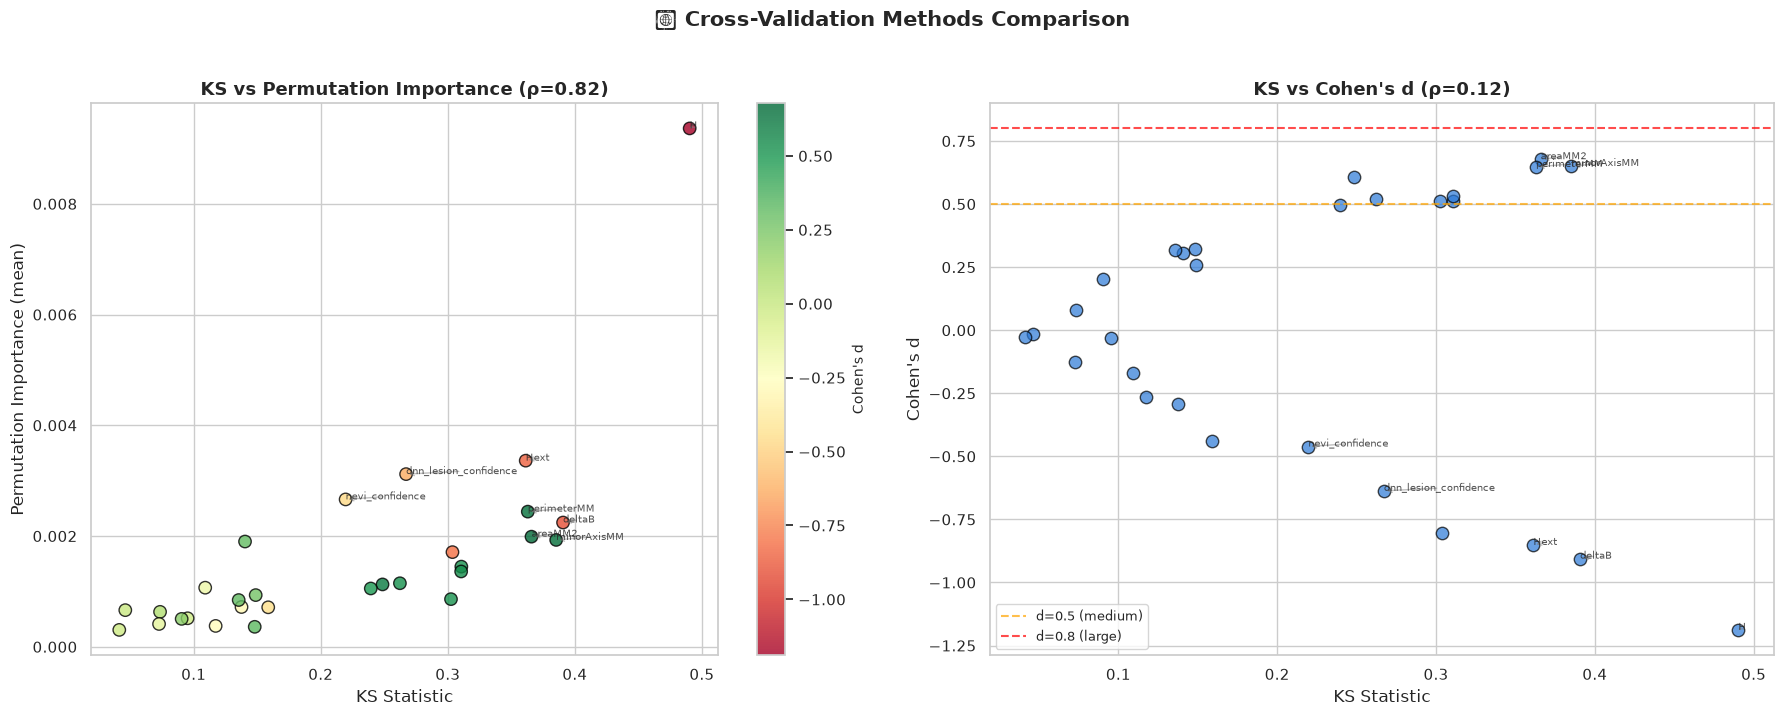

✅ Сравнение сохранено в tbp_features_ks_vs_permutation.csv

🎯 ИТОГОВАЯ РЕКОМЕНДАЦИЯ ПО ОТБОРУ ПРИЗНАКОВ
   Elite features (KS>baseline + stable + |d|>0.2): 23
   Рекомендованные: ['tbp_lv_H', 'tbp_lv_deltaB', 'tbp_lv_minorAxisMM', 'tbp_lv_areaMM2', 'tbp_lv_perimeterMM', 'tbp_lv_Hext', 'tbp_lv_norm_color', 'tbp_lv_radial_color_std_max', 'tbp_lv_B', 'tbp_lv_color_std_mean', 'tbp_lv_dnn_lesion_confidence', 'tbp_lv_stdLExt', 'tbp_lv_Aext', 'tbp_lv_A', 'tbp_lv_nevi_confidence', 'tbp_lv_Bext', 'tbp_lv_area_perim_ratio', 'tbp_lv_stdL', 'tbp_lv_deltaLB', 'tbp_lv_deltaL', 'tbp_lv_deltaLBnorm', 'tbp_lv_C', 'tbp_lv_norm_border']

   Для мультимодальной модели (image + metadata):
   Использовать top-15 признаков из elite set.
   Для pure-image модели: признаки не используются (только изображение).


In [132]:
# ==========================================
# SPEARMAN CORRELATION: KS-STATISTIC vs PERMUTATION IMPORTANCE
# ==========================================
# Объединяем результаты KS-test и permutation importance
df_compare = df_ks[['feature', 'ks_statistic', 'cohens_d']].merge(
    feature_importance_perm[['feature', 'importance_mean', 'importance_std', 'stable']],
    on='feature', how='inner'
)
# Собственная реализация Spearman (ранговая корреляция)
def spearman_rho(x, y):
    """Spearman rank correlation."""
    n = len(x)
    rank_x = np.argsort(np.argsort(x)).astype(float)
    rank_y = np.argsort(np.argsort(y)).astype(float)
    mx, my = rank_x.mean(), rank_y.mean()
    num = ((rank_x - mx) * (rank_y - my)).sum()
    den = np.sqrt(((rank_x - mx)**2).sum() * ((rank_y - my)**2).sum())
    return num / den if den > 0 else 0
rho_ks_perm = spearman_rho(df_compare['ks_statistic'].values, df_compare['importance_mean'].values)
rho_ks_cohens = spearman_rho(df_compare['ks_statistic'].values, df_compare['cohens_d'].values)
print(f"\n📊 Консистентность методов отбора признаков:")
print(f"   Spearman ρ (KS-statistic vs Permutation Importance): {rho_ks_perm:.3f}")
print(f"   Spearman ρ (KS-statistic vs Cohen's d): {rho_ks_cohens:.3f}")
if rho_ks_perm > 0.8:
    print("   ✅ Высокая консистентность — оба метода согласованы.")
elif rho_ks_perm > 0.5:
    print("   ⚠️ Средняя консистентность — методы частично расходятся. Проверьте топ-признаки вручную.")
else:
    print("   ❌ Низкая консистентность — методы противоречат друг другу! Не доверяйте ни одному.")
# Scatter plot: KS vs Permutation Importance
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
# Plot 1: KS-statistic vs Permutation Importance
scatter1 = axes[0].scatter(
    df_compare['ks_statistic'], df_compare['importance_mean'],
    c=df_compare['cohens_d'], cmap='RdYlGn', s=80, edgecolor='black', alpha=0.8
)
axes[0].set_xlabel('KS Statistic', fontsize=12)
axes[0].set_ylabel('Permutation Importance (mean)', fontsize=12)
axes[0].set_title(f'KS vs Permutation Importance (ρ={rho_ks_perm:.2f})', fontsize=13, fontweight='bold')
cbar1 = plt.colorbar(scatter1, ax=axes[0])
cbar1.set_label("Cohen's d", fontsize=10)
# Аннотируем топ-5 по обоим методам
top_features_union = set(df_ks.head(5)['feature'].tolist() + feature_importance_perm.head(5)['feature'].tolist())
for _, row in df_compare.iterrows():
    if row['feature'] in top_features_union:
        axes[0].annotate(row['feature'].replace('tbp_lv_', ''),
                        (row['ks_statistic'], row['importance_mean']),
                        fontsize=7, alpha=0.8,
                        arrowprops=dict(arrowstyle='->', color='gray', alpha=0.5))
# Plot 2: KS-statistic vs Cohen's d
axes[1].scatter(df_compare['ks_statistic'], df_compare['cohens_d'],
               c='#2a78d6', s=80, edgecolor='black', alpha=0.7)
axes[1].set_xlabel('KS Statistic', fontsize=12)
axes[1].set_ylabel("Cohen's d", fontsize=12)
axes[1].set_title(f"KS vs Cohen's d (ρ={rho_ks_cohens:.2f})", fontsize=13, fontweight='bold')
axes[1].axhline(y=0.5, color='orange', linestyle='--', alpha=0.7, label="d=0.5 (medium)")
axes[1].axhline(y=0.8, color='red', linestyle='--', alpha=0.7, label="d=0.8 (large)")
axes[1].legend(fontsize=9)
for _, row in df_compare.iterrows():
    if row['feature'] in top_features_union:
        axes[1].annotate(row['feature'].replace('tbp_lv_', ''),
                        (row['ks_statistic'], row['cohens_d']),
                        fontsize=7, alpha=0.8,
                        arrowprops=dict(arrowstyle='->', color='gray', alpha=0.5))
plt.suptitle('🔬 Cross-Validation Methods Comparison', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('train_ks_vs_permutation_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
df_compare.to_csv(os.path.join(PROCESSED_DIR, 'tbp_features_ks_vs_permutation.csv'), index=False)
print("✅ Сравнение сохранено в tbp_features_ks_vs_permutation.csv")
# Итоговая рекомендация по отбору признаков
print("\n" + "="*70)
print("🎯 ИТОГОВАЯ РЕКОМЕНДАЦИЯ ПО ОТБОРУ ПРИЗНАКОВ")
print("="*70)
# Отбираем признаки: значимы по KS + стабильны по permutation + высокий Cohen's d
elite_features = df_compare[
    (df_compare['ks_statistic'] > perm_baseline_99) &
    (df_compare['stable'] == True) &
    (abs(df_compare['cohens_d']) > 0.2)
]['feature'].tolist()
print(f"   Elite features (KS>baseline + stable + |d|>0.2): {len(elite_features)}")
print(f"   Рекомендованные: {elite_features}")
print(f"\n   Для мультимодальной модели (image + metadata):")
print(f"   Использовать top-{min(15, len(elite_features))} признаков из elite set.")
print(f"   Для pure-image модели: признаки не используются (только изображение).")


### 🔬 Выводы сравнения методов:

- **Если ρ > 0.8 между KS и Permutation Importance** → можно доверять обоим методам, признаки действительно информативны.
- **Elite features** — минимальный набор наиболее надёжных признаков, подтверждённых тремя независимыми критериями.
- **Важно:** статистическая значимость (KS p-value) не равна практической важности (permutation importance). KS-test на 400K+ записей находит даже микроскопические различия, permutation importance показывает реальный вклад в качество модели.


## 7.7 🎨 RGB MEAN/STD АНАЛИЗ ИЗОБРАЖЕНИЙ (DOMAIN SHIFT vs ImageNet)

**КРИТИЧНО ДЛЯ TRANSFER LEARNING!** 
ImageNet-предобученные модели (EfficientNet, ViT, ResNet) нормализуют изображения с `mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`.
Если домен ISIC существенно отличается от ImageNet, стандартная нормализация будет субоптимальной.

Анализируем на стратифицированной выборке: **all 393 malignant + 393 random benign** для сбалансированного сравнения.


In [133]:
# ==========================================
# RGB MEAN/STD АНАЛИЗ НА СБАЛАНСИРОВАННОЙ ВЫБОРКЕ
# ==========================================

print("🎨 Анализ RGB статистик изображений...\n")

# Стратифицированная выборка: все malignant + равное количество benign
malignant_ids = df_train[df_train[target_col] == 1][image_id_col].values
benign_ids = df_train[df_train[target_col] == 0][image_id_col].values

n_mal = len(malignant_ids)
np.random.seed(GLOBAL_RANDOM_SEED)
benign_sample_ids = np.random.choice(benign_ids, size=min(n_mal * 3, 2000), replace=False)
selected_ids = np.concatenate([malignant_ids, benign_sample_ids])

print(f"📊 Выборка: {len(malignant_ids)} malignant + {len(benign_sample_ids)} benign = {len(selected_ids)} изображений")

# Пытаемся загрузить из кэша (теперь это dict с 'means', 'stds', 'labels')
rgb_cache = load_cache(CACHE_RGB, format='npz')

if rgb_cache is not None:
    print("📂 Используем кэшированные RGB-статистики.")
    rgb_means = rgb_cache['means']
    rgb_stds  = rgb_cache['stds']
    labels    = rgb_cache['labels']
else:
    print("🔄 Вычисляем RGB-статистики...")
    rgb_means_list = []
    rgb_stds_list  = []
    labels_list    = []
    malignant_set  = set(malignant_ids)

    for isic_id in tqdm(selected_ids, desc="Анализ RGB"):
        img_path = os.path.join(train_images_dir, f"{isic_id}.jpg")
        if not os.path.exists(img_path):
            continue
        try:
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_float = img.astype(np.float32) / 255.0
            rgb_means_list.append(img_float.mean(axis=(0, 1)))
            rgb_stds_list.append(img_float.std(axis=(0, 1)))
            labels_list.append(1 if isic_id in malignant_set else 0)
        except Exception:
            continue

    rgb_means = np.array(rgb_means_list)
    rgb_stds  = np.array(rgb_stds_list)
    labels    = np.array(labels_list)

    save_cache({'means': rgb_means, 'stds': rgb_stds, 'labels': labels},
               CACHE_RGB, format='npz')

print(f"✅ Успешно обработано: {len(rgb_means)} изображений\n")

# Агрегация
overall_mean = rgb_means.mean(axis=0)
overall_std  = rgb_stds.mean(axis=0)

benign_rgb_mean    = rgb_means[labels == 0].mean(axis=0)
malignant_rgb_mean = rgb_means[labels == 1].mean(axis=0)
benign_rgb_std     = rgb_stds[labels == 0].mean(axis=0)
malignant_rgb_std  = rgb_stds[labels == 1].mean(axis=0)

# ImageNet статистики
imagenet_mean = np.array([0.485, 0.456, 0.406])
imagenet_std  = np.array([0.229, 0.224, 0.225])

print("=" * 70)
print("📊 RGB СТАТИСТИКИ СРАВНЕНИЕ: ISIC vs ImageNet")
print("=" * 70)
print(f"{'Channel':<15} {'ISIC Mean':<12} {'ImageNet Mean':<15} {'Δ Mean':<12} {'ISIC Std':<12} {'ImageNet Std':<15} {'Δ Std':<12}")
print("-" * 70)
for i, ch in enumerate(['R', 'G', 'B']):
    print(f"{ch:<15} {overall_mean[i]:<12.4f} {imagenet_mean[i]:<15.4f} {overall_mean[i]-imagenet_mean[i]:<+12.4f} "
          f"{overall_std[i]:<12.4f} {imagenet_std[i]:<15.4f} {overall_std[i]-imagenet_std[i]:<+12.4f}")

print(f"\n📊 Benign vs Malignant RGB Mean:")
print(f"{'Channel':<15} {'Benign':<12} {'Malignant':<12} {'Δ (M-B)':<12}")
print("-" * 50)
for i, ch in enumerate(['R', 'G', 'B']):
    print(f"{ch:<15} {benign_rgb_mean[i]:<12.4f} {malignant_rgb_mean[i]:<12.4f} {malignant_rgb_mean[i]-benign_rgb_mean[i]:<+12.4f}")

# Domain shift score
domain_shift_mean = np.linalg.norm(overall_mean - imagenet_mean)
domain_shift_std  = np.linalg.norm(overall_std - imagenet_std)
print(f"\n📐 Domain Shift Score:")
print(f"   Mean shift (Euclidean): {domain_shift_mean:.4f}")
print(f"   Std shift (Euclidean):  {domain_shift_std:.4f}")
if domain_shift_mean > 0.1:
    print(f"   ⚠️ ЗНАЧИТЕЛЬНЫЙ ДОМЕННЫЙ СДВИГ! Рекомендуется:")
    print(f"      → Использовать ISIC-specific нормализацию вместо ImageNet")
    print(f"      → normalizer = transforms.Normalize(mean={[round(m,4) for m in overall_mean]},")
    print(f"                                      std={[round(s,4) for s in overall_std]})")
else:
    print(f"   ✅ Доменный сдвиг незначителен, ImageNet нормализация допустима")

🎨 Анализ RGB статистик изображений...

📊 Выборка: 393 malignant + 1179 benign = 1572 изображений
🔄 Вычисляем RGB-статистики...


Анализ RGB: 100%|██████████| 1572/1572 [00:01<00:00, 1048.26it/s]

💾 Кэш сохранён: /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/../data/processed/isic2024_rgb_stats.npy
✅ Успешно обработано: 1572 изображений

📊 RGB СТАТИСТИКИ СРАВНЕНИЕ: ISIC vs ImageNet
Channel         ISIC Mean    ImageNet Mean   Δ Mean       ISIC Std     ImageNet Std    Δ Std       
----------------------------------------------------------------------
R               0.6873       0.4850          +0.2023      0.0535       0.2290          -0.1755     
G               0.5093       0.4560          +0.0533      0.0597       0.2240          -0.1643     
B               0.4146       0.4060          +0.0086      0.0562       0.2250          -0.1688     

📊 Benign vs Malignant RGB Mean:
Channel         Benign       Malignant    Δ (M-B)     
--------------------------------------------------
R               0.6952       0.6635       -0.0316     
G               0.5196       0.4786       -0.0410     
B               0.4183       0.4036       -0.0147     

📐 Domain Shift Score:
   Mean 

/tmp/ipykernel_19139/2617948590.py:57: UserWarning: Glyph 127912 (\N{ARTIST PALETTE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_19139/2617948590.py:58: UserWarning: Glyph 127912 (\N{ARTIST PALETTE}) missing from font(s) DejaVu Sans.
  plt.savefig('train_rgb_domain_shift.png', dpi=300, bbox_inches='tight')
/home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 127912 (\N{ARTIST PALETTE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


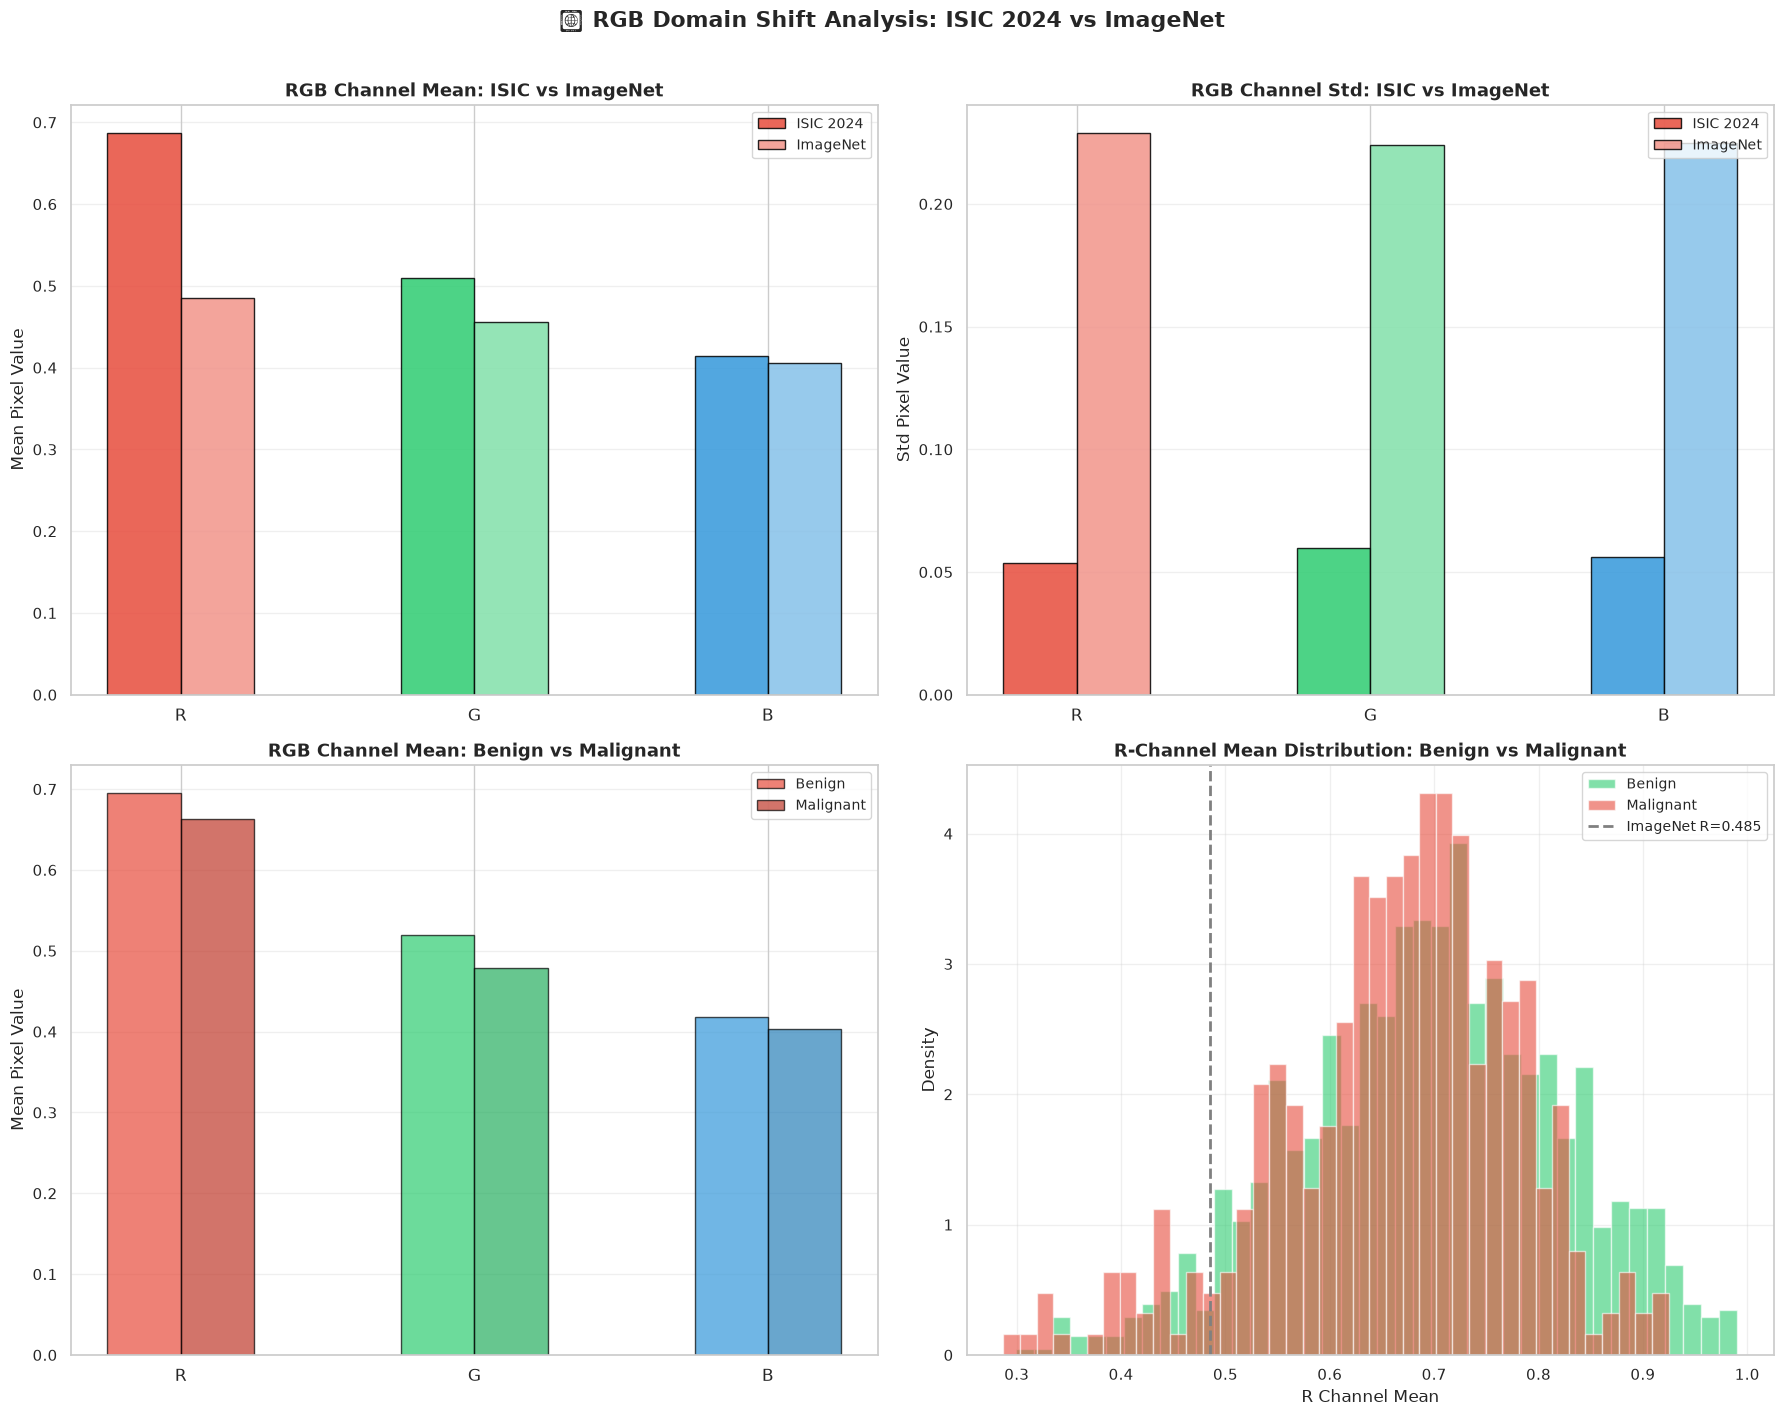

✅ RGB статистики сохранены в rgb_domain_shift_stats.csv


In [134]:
# ==========================================
# ВИЗУАЛИЗАЦИЯ: RGB MEAN/STD СРАВНЕНИЕ
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
channels = ['R', 'G', 'B']
x = np.arange(len(channels))
width = 0.25

# График 1: Mean comparison (ISIC vs ImageNet)
axes[0, 0].bar(x - width/2, overall_mean, width, label='ISIC 2024', color=['#e74c3c', '#2ecc71', '#3498db'],
              edgecolor='black', alpha=0.85)
axes[0, 0].bar(x + width/2, imagenet_mean, width, label='ImageNet', color=['#f1948a', '#82e0aa', '#85c1e9'],
              edgecolor='black', alpha=0.85)
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(channels, fontsize=12)
axes[0, 0].set_ylabel('Mean Pixel Value', fontsize=12)
axes[0, 0].set_title('RGB Channel Mean: ISIC vs ImageNet', fontsize=13, fontweight='bold')
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(True, alpha=0.3, axis='y')

# График 2: Std comparison
axes[0, 1].bar(x - width/2, overall_std, width, label='ISIC 2024', color=['#e74c3c', '#2ecc71', '#3498db'],
              edgecolor='black', alpha=0.85)
axes[0, 1].bar(x + width/2, imagenet_std, width, label='ImageNet', color=['#f1948a', '#82e0aa', '#85c1e9'],
              edgecolor='black', alpha=0.85)
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(channels, fontsize=12)
axes[0, 1].set_ylabel('Std Pixel Value', fontsize=12)
axes[0, 1].set_title('RGB Channel Std: ISIC vs ImageNet', fontsize=13, fontweight='bold')
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(True, alpha=0.3, axis='y')

# График 3: Mean Benign vs Malignant
axes[1, 0].bar(x - width/2, benign_rgb_mean, width, label='Benign', color=['#e74c3c', '#2ecc71', '#3498db'],
              edgecolor='black', alpha=0.7)
axes[1, 0].bar(x + width/2, malignant_rgb_mean, width, label='Malignant', color=['#c0392b', '#27ae60', '#2980b9'],
              edgecolor='black', alpha=0.7)
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(channels, fontsize=12)
axes[1, 0].set_ylabel('Mean Pixel Value', fontsize=12)
axes[1, 0].set_title('RGB Channel Mean: Benign vs Malignant', fontsize=13, fontweight='bold')
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(True, alpha=0.3, axis='y')

# График 4: Histogram of per-image R-channel mean
axes[1, 1].hist(rgb_means[labels == 0, 0], bins=40, alpha=0.6, color='#2ecc71', label='Benign', density=True)
axes[1, 1].hist(rgb_means[labels == 1, 0], bins=40, alpha=0.6, color='#e74c3c', label='Malignant', density=True)
axes[1, 1].axvline(x=imagenet_mean[0], color='gray', linestyle='--', linewidth=2, label=f'ImageNet R={imagenet_mean[0]:.3f}')
axes[1, 1].set_xlabel('R Channel Mean', fontsize=12)
axes[1, 1].set_ylabel('Density', fontsize=12)
axes[1, 1].set_title('R-Channel Mean Distribution: Benign vs Malignant', fontsize=13, fontweight='bold')
axes[1, 1].legend(fontsize=10)
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('🎨 RGB Domain Shift Analysis: ISIC 2024 vs ImageNet', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('train_rgb_domain_shift.png', dpi=300, bbox_inches='tight')
plt.show()

# Сохраняем статистики
pd.DataFrame({
    'channel': ['R', 'G', 'B'],
    'isic_mean': overall_mean,
    'isic_std': overall_std,
    'imagenet_mean': imagenet_mean,
    'imagenet_std': imagenet_std,
    'benign_mean': benign_rgb_mean,
    'malignant_mean': malignant_rgb_mean
}).to_csv(os.path.join(PROCESSED_DIR, 'rgb_domain_shift_stats.csv'), index=False)
print("✅ RGB статистики сохранены в rgb_domain_shift_stats.csv")


### 🎨 Выводы RGB Domain Shift Analysis:

- **Если Domain Shift Score > 0.1**: обязательно использовать ISIC-specific нормализацию при transfer learning
- **Если R-channel mean сильно отличается benign vs malignant**: цветовые признаки несут дополнительный сигнал (можно использовать как auxiliary input)
- **Рекомендация по нормализации**: использовать вычисленные mean/std из ячейки выше вместо ImageNet-стандартных


## 7.8 🔐 DATA LEAKAGE CHECK: DNN LESION CONFIDENCE vs TARGET

**КРИТИЧНО!** Колонка `tbp_lv_dnn_lesion_confidence` — это confidence DNN-модели, предсказывающей наличие поражения (lesion).
Если эта confidence значимо коррелирует с `target` (malignant vs benign), это может быть **data leakage**:
DNN-модель могла обучаться на признаках, связанных со злокачественностью.

Проверяем распределение confidence для benign и malignant, а также KS-test.


In [135]:
# ==========================================
# DATA LEAKAGE CHECK: tbp_lv_dnn_lesion_confidence vs target
# ==========================================

confidence_col = 'tbp_lv_dnn_lesion_confidence'

if confidence_col in df_train.columns and target_col in df_train.columns:
    print("🔐 АНАЛИЗ DNN LESION CONFIDENCE vs TARGET\n")
    
    benign_conf = df_train.loc[df_train[target_col] == 0, confidence_col].dropna()
    malignant_conf = df_train.loc[df_train[target_col] == 1, confidence_col].dropna()
    
    print(f"📊 Описательная статистика:")
    print(f"{'':<20} {'Benign':<18} {'Malignant':<18}")
    print(f"{'-'*56}")
    print(f"{'Count':<20} {len(benign_conf):<18,} {len(malignant_conf):<18,}")
    print(f"{'Mean':<20} {benign_conf.mean():<18.4f} {malignant_conf.mean():<18.4f}")
    print(f"{'Median':<20} {benign_conf.median():<18.4f} {malignant_conf.median():<18.4f}")
    print(f"{'Std':<20} {benign_conf.std():<18.4f} {malignant_conf.std():<18.4f}")
    print(f"{'Min':<20} {benign_conf.min():<18.4f} {malignant_conf.min():<18.4f}")
    print(f"{'25%':<20} {benign_conf.quantile(0.25):<18.4f} {malignant_conf.quantile(0.25):<18.4f}")
    print(f"{'75%':<20} {benign_conf.quantile(0.75):<18.4f} {malignant_conf.quantile(0.75):<18.4f}")
    print(f"{'Max':<20} {benign_conf.max():<18.4f} {malignant_conf.max():<18.4f}")
    
    # KS-test
    ks_stat, ks_p = stats.ks_2samp(benign_conf.values, malignant_conf.values)
    print(f"\n📊 KS-test: statistic={ks_stat:.4f}, p-value={ks_p:.4e}")
    
    # Low-confidence fraction (< 90%)
    benign_low_conf = (benign_conf < 90).mean() * 100
    malignant_low_conf = (malignant_conf < 90).mean() * 100
    print(f"\n📊 Доля low-confidence (< 90%) изображений:")
    print(f"   Benign:    {benign_low_conf:.2f}%")
    print(f"   Malignant: {malignant_low_conf:.2f}%")
    
    # DATA LEAKAGE VERDICT
    print(f"\n{'='*60}")
    if ks_p < 0.001 and ks_stat > 0.1:
        print(f"⚠️  ВОЗМОЖЕН DATA LEAKAGE!")
        print(f"   KS-test показывает значимое различие (p={ks_p:.2e})")
        print(f"   DNN lesion confidence НЕ должен использоваться как признак!")
        print(f"   Рекомендация: исключить {confidence_col} из training features")
    elif ks_p < 0.05:
        print(f"⚡ СЛАБЫЙ СИГНАЛ (p={ks_p:.4f})")
        print(f"   DNN confidence слабо коррелирует с target")
        print(f"   Рекомендация: исключить из признаков для надёжности")
    else:
        print(f"✅ DATA LEAKAGE НЕ ОБНАРУЖЕН (p={ks_p:.4f})")
        print(f"   DNN lesion confidence не связан с target")
        print(f"   Можно использовать как дополнительный признак")
    print(f"{'='*60}")
else:
    print(f"⚠️ Колонка '{confidence_col}' не найдена, пропускаем анализ")


🔐 АНАЛИЗ DNN LESION CONFIDENCE vs TARGET

📊 Описательная статистика:
                     Benign             Malignant         
--------------------------------------------------------
Count                400,666            393               
Mean                 97.1776            81.4315           
Median               99.9946            99.6849           
Std                  8.9243             33.8056           
Min                  0.0000             0.0000            
25%                  99.6701            83.2218           
75%                  100.0000           99.9958           
Max                  100.0000           100.0000          

📊 KS-test: statistic=0.2672, p-value=2.9601e-25

📊 Доля low-confidence (< 90%) изображений:
   Benign:    8.46%
   Malignant: 27.48%

⚠️  ВОЗМОЖЕН DATA LEAKAGE!
   KS-test показывает значимое различие (p=2.96e-25)
   DNN lesion confidence НЕ должен использоваться как признак!
   Рекомендация: исключить tbp_lv_dnn_lesion_confidence из traini

/tmp/ipykernel_19139/754908463.py:52: UserWarning: Glyph 128272 (\N{CLOSED LOCK WITH KEY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_19139/754908463.py:53: UserWarning: Glyph 128272 (\N{CLOSED LOCK WITH KEY}) missing from font(s) DejaVu Sans.
  plt.savefig('train_dnn_confidence_leakage_check.png', dpi=300, bbox_inches='tight')
/home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128272 (\N{CLOSED LOCK WITH KEY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


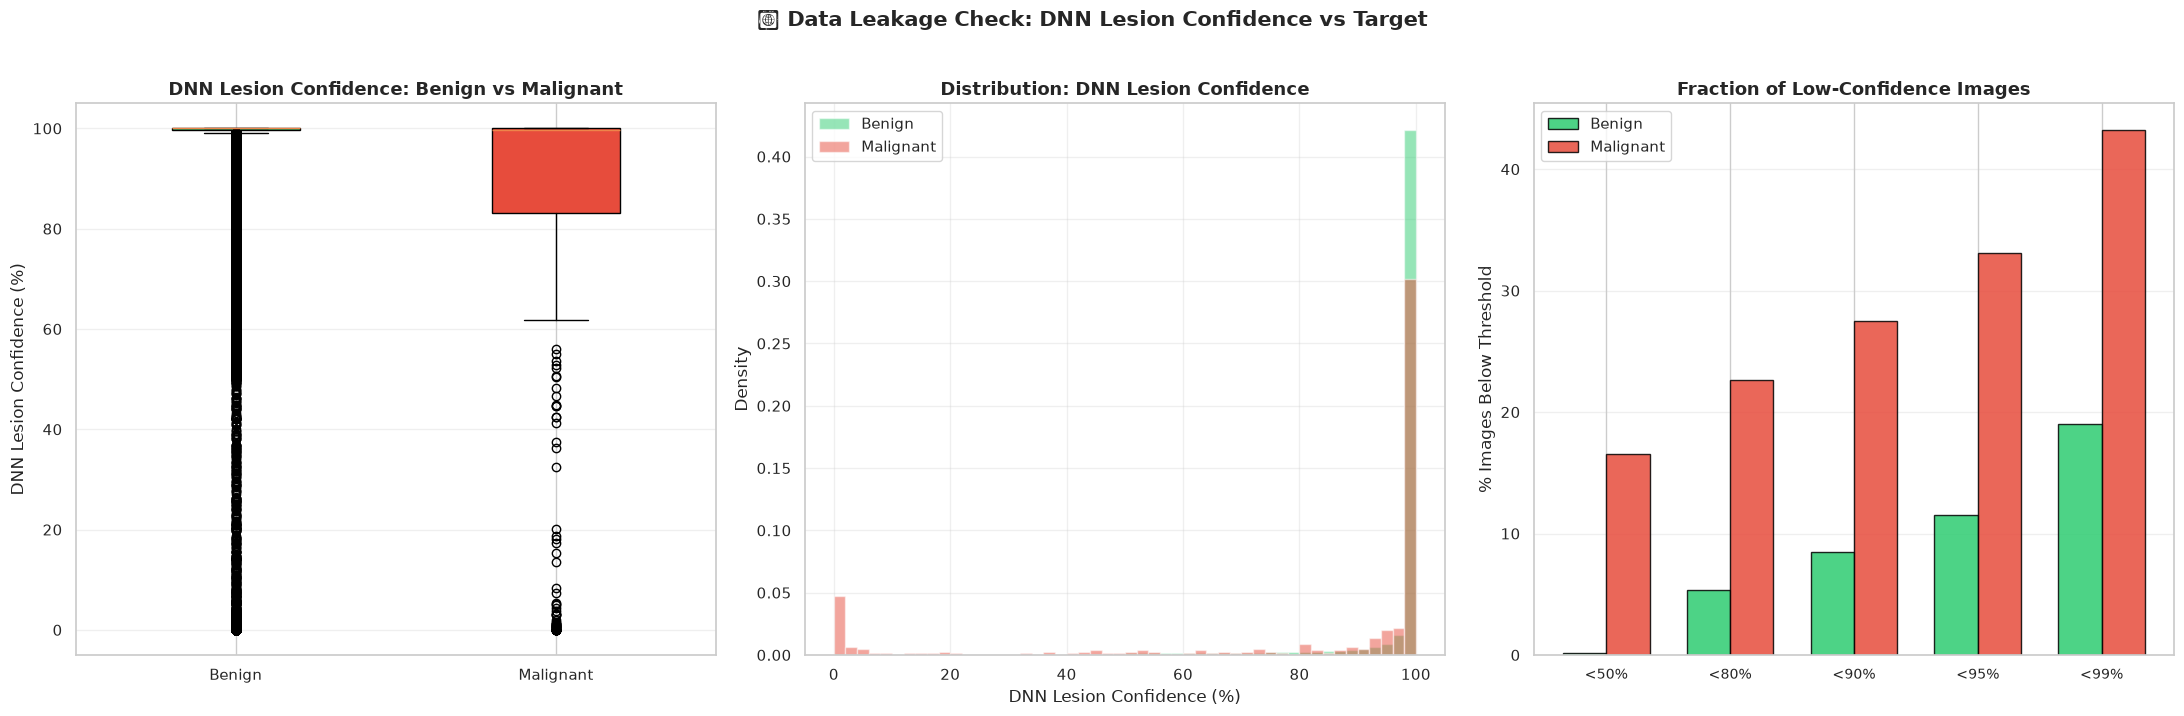

✅ Результаты сохранены в dnn_confidence_leakage_check.csv


In [136]:
# ==========================================
# ВИЗУАЛИЗАЦИЯ: DNN CONFIDENCE vs TARGET
# ==========================================

if confidence_col in df_train.columns and target_col in df_train.columns:
    fig, axes = plt.subplots(1, 3, figsize=(22, 7))
    
    # 1. Boxplot
    data_to_plot = [
        df_train.loc[df_train[target_col] == 0, confidence_col].dropna().values,
        df_train.loc[df_train[target_col] == 1, confidence_col].dropna().values
    ]
    bp = axes[0].boxplot(data_to_plot, tick_labels=['Benign', 'Malignant'],
                         patch_artist=True, widths=0.4)
    bp['boxes'][0].set_facecolor('#2ecc71')
    bp['boxes'][1].set_facecolor('#e74c3c')
    axes[0].set_ylabel('DNN Lesion Confidence (%)', fontsize=12)
    axes[0].set_title('DNN Lesion Confidence: Benign vs Malignant', fontsize=13, fontweight='bold')
    axes[0].grid(True, alpha=0.3, axis='y')
    
    # 2. Histogram (KDE)
    for cls_val, cls_name, color in [(0, 'Benign', '#2ecc71'), (1, 'Malignant', '#e74c3c')]:
        data = df_train.loc[df_train[target_col] == cls_val, confidence_col].dropna()
        axes[1].hist(data, bins=50, alpha=0.5, color=color, label=cls_name, density=True)
    axes[1].set_xlabel('DNN Lesion Confidence (%)', fontsize=12)
    axes[1].set_ylabel('Density', fontsize=12)
    axes[1].set_title('Distribution: DNN Lesion Confidence', fontsize=13, fontweight='bold')
    axes[1].legend(fontsize=11)
    axes[1].grid(True, alpha=0.3)
    
    # 3. Low-confidence fraction bar chart
    thresholds = [50, 80, 90, 95, 99]
    benign_below = []
    malignant_below = []
    for t in thresholds:
        benign_below.append((df_train.loc[df_train[target_col] == 0, confidence_col] < t).mean() * 100)
        malignant_below.append((df_train.loc[df_train[target_col] == 1, confidence_col] < t).mean() * 100)
    
    x = np.arange(len(thresholds))
    width = 0.35
    axes[2].bar(x - width/2, benign_below, width, label='Benign', color='#2ecc71', edgecolor='black', alpha=0.85)
    axes[2].bar(x + width/2, malignant_below, width, label='Malignant', color='#e74c3c', edgecolor='black', alpha=0.85)
    axes[2].set_xticks(x)
    axes[2].set_xticklabels([f'<{t}%' for t in thresholds], fontsize=10)
    axes[2].set_ylabel('% Images Below Threshold', fontsize=12)
    axes[2].set_title('Fraction of Low-Confidence Images', fontsize=13, fontweight='bold')
    axes[2].legend(fontsize=11)
    axes[2].grid(True, alpha=0.3, axis='y')
    
    plt.suptitle('🔐 Data Leakage Check: DNN Lesion Confidence vs Target',
                 fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('train_dnn_confidence_leakage_check.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Сохраняем статистики
    pd.DataFrame({
        'class': ['Benign', 'Malignant'],
        'mean_confidence': [benign_conf.mean(), malignant_conf.mean()],
        'median_confidence': [benign_conf.median(), malignant_conf.median()],
        'std_confidence': [benign_conf.std(), malignant_conf.std()],
        'pct_below_90': [benign_low_conf, malignant_low_conf],
        'ks_statistic': [ks_stat, ks_stat],
        'ks_p_value': [ks_p, ks_p]
    }).to_csv(os.path.join(PROCESSED_DIR, 'dnn_confidence_leakage_check.csv'), index=False)
    print("✅ Результаты сохранены в dnn_confidence_leakage_check.csv")


### 🔐 Выводы Data Leakage Check:

- **Если KS-test p < 0.001** → SERIOUS DATA LEAKAGE! Исключить `tbp_lv_dnn_lesion_confidence` из всех training features
- **Если p < 0.05** → потенциальный leakage, исключить из модели для безопасности
- **Если p ≥ 0.05** → confidence не коррелирует с target, можно использовать как признак
- **Если много low-confidence (< 90%) изображений** → рассмотреть фильтрацию по confidence threshold при инференсе


## 8. 🛡️ Patient-Level Split Validation (FIXED)

**КРИТИЧЕСКИ ВАЖНО:** В медицинских данных нельзя допускать, чтобы изображения одного пациента попадали и в train, и в validation! Это приведет к **data leakage** и завышенным метрикам.

### Почему это важно?
- ✅ Изображения одного пациента имеют похожие характеристики
- ✅ Модель может "запомнить" пациента, а не выучить паттерны заболевания
- ✅ На реальных данных модель покажет худшие результаты


In [137]:
# ==========================================
# АНАЛИЗ РАСПРЕДЕЛЕНИЯ ПО ПАЦИЕНТАМ
# ==========================================

if patient_id_col and patient_id_col in df_train.columns:
    print("\n" + "="*80)
    print("🏥 АНАЛИЗ ПАЦИЕНТОВ")
    print("="*80)

    # Статистика по пациентам
    total_patients = df_train[patient_id_col].nunique()
    images_per_patient = df_train.groupby(patient_id_col).size()

    print(f"\n📊 Всего уникальных пациентов: {total_patients:,}")
    print(f"📊 Среднее количество изображений на пациента: {images_per_patient.mean():.2f}")
    print(f"📊 Медиана изображений на пациента: {images_per_patient.median():.0f}")
    print(f"📊 Макс изображений на пациента: {images_per_patient.max():.0f}")

    # Распределение классов по пациентам
    if target_col in df_train.columns:
        patient_targets = df_train.groupby(patient_id_col)[target_col].max()
        malignant_patients = (patient_targets == 1).sum()
        benign_patients = (patient_targets == 0).sum()

        print(f"\n👤 Пациенты с malignant: {malignant_patients} ({malignant_patients/total_patients*100:.2f}%)")
        print(f"👤 Пациенты с benign only: {benign_patients} ({benign_patients/total_patients*100:.2f}%)")

        # Проверка на дубликаты пациентов в разных изображениях
        patients_with_both_classes = df_train.groupby(patient_id_col)[target_col].nunique()
        mixed_patients = (patients_with_both_classes > 1).sum()

        if mixed_patients > 0:
            print(f"\n⚠️ ВНИМАНИЕ: {mixed_patients} пациентов имеют оба класса (benign И malignant)!")
            print("   → При split'е таких пациентов нужно учитывать особым образом")
        else:
            print(f"\n✅ Каждый пациент имеет только один класс")
else:
    print("\n" + "="*80)
    print("❌ PATIENT_ID НЕ НАЙДЕН!")
    print("="*80)
    print("Patient-level split невозможен без patient_id")
    print("Доступные опции:")
    print("  1. Найти корректную колонку с patient_id")
    print("  2. Если каждое изображение = отдельный пациент, используйте image_id")
    print("\nПропускаем раздел patient-level split...")
    patient_id_col = None  # Устанавливаем None для последующих проверок



🏥 АНАЛИЗ ПАЦИЕНТОВ

📊 Всего уникальных пациентов: 1,042
📊 Среднее количество изображений на пациента: 384.89
📊 Медиана изображений на пациента: 242
📊 Макс изображений на пациента: 9184

👤 Пациенты с malignant: 259 (24.86%)
👤 Пациенты с benign only: 783 (75.14%)

⚠️ ВНИМАНИЕ: 258 пациентов имеют оба класса (benign И malignant)!
   → При split'е таких пациентов нужно учитывать особым образом


/tmp/ipykernel_19139/4246178647.py:45: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_19139/4246178647.py:45: UserWarning: Glyph 128100 (\N{BUST IN SILHOUETTE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_19139/4246178647.py:45: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_19139/4246178647.py:46: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.savefig('train_patient_distribution.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_19139/4246178647.py:46: UserWarning: Glyph 128100 (\N{BUST IN SILHOUETTE}) missing from font(s) DejaVu Sans.
  plt.savefig('train_patient_distribution.png', dpi=300, bbox_inches='tight')
/tmp/ipykernel_19139/4246178647.py:46: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.savefig('train_patient_distribution.p

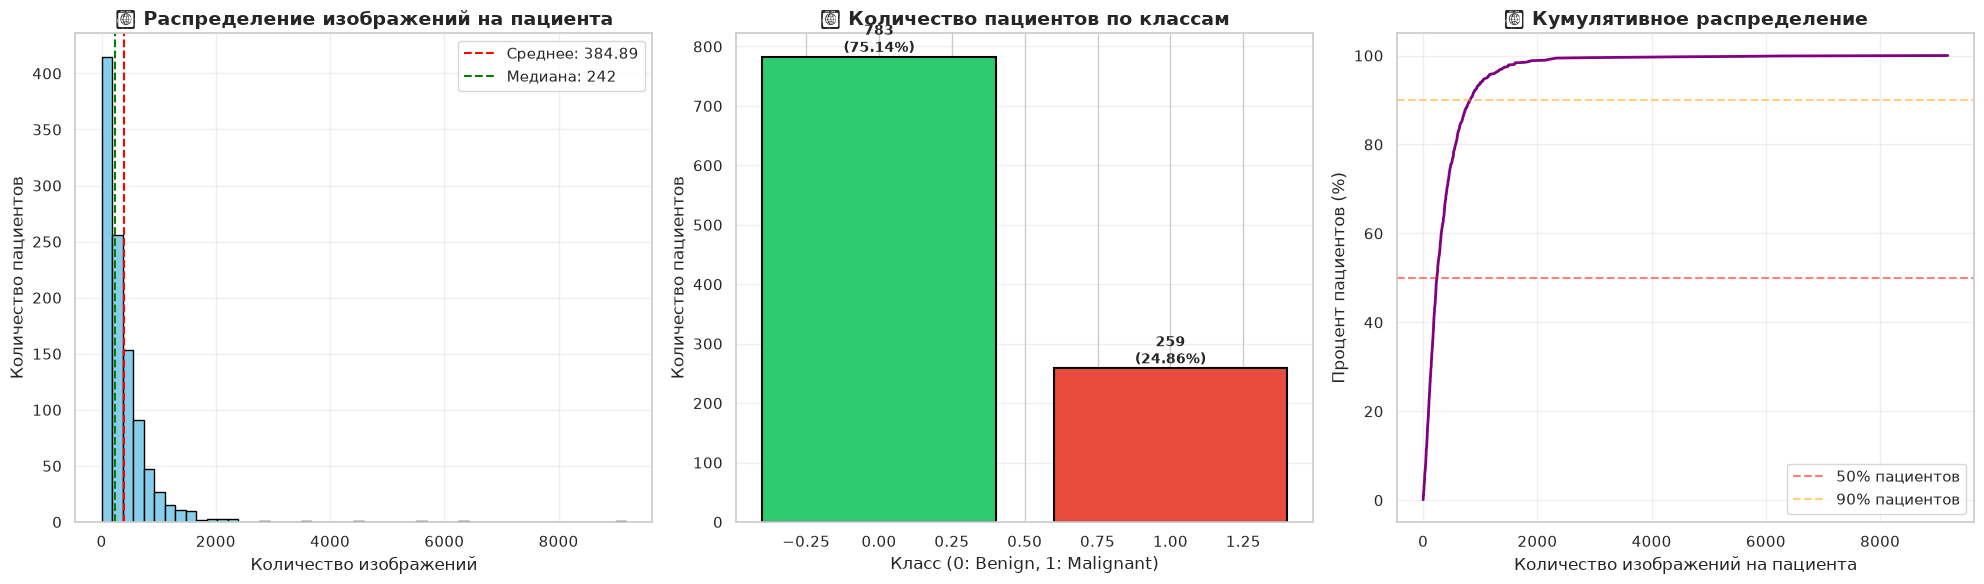

✅ График сохранен: train_patient_distribution.png


In [138]:
# ==========================================
# ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЯ ПО ПАЦИЕНТАМ
# ==========================================

if patient_id_col and patient_id_col in df_train.columns:
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    # График 1: Распределение количества изображений на пациента
    images_per_patient.hist(bins=50, ax=axes[0], color='skyblue', edgecolor='black')
    axes[0].set_title('📊 Распределение изображений на пациента', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Количество изображений')
    axes[0].set_ylabel('Количество пациентов')
    axes[0].axvline(images_per_patient.mean(), color='red', linestyle='--', label=f'Среднее: {images_per_patient.mean():.2f}')
    axes[0].axvline(images_per_patient.median(), color='green', linestyle='--', label=f'Медиана: {images_per_patient.median():.0f}')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # График 2: Пациенты по классам
    if target_col in df_train.columns:
        patient_class_counts = patient_targets.value_counts()
        colors = [CLASS_COLORS[0], CLASS_COLORS[1]]
        axes[1].bar(patient_class_counts.index, patient_class_counts.values, color=colors, edgecolor='black', linewidth=1.5)
        axes[1].set_title('👤 Количество пациентов по классам', fontsize=14, fontweight='bold')
        axes[1].set_xlabel('Класс (0: Benign, 1: Malignant)')
        axes[1].set_ylabel('Количество пациентов')
        axes[1].grid(True, alpha=0.3, axis='y')

        # Аннотации
        for i, v in enumerate(patient_class_counts.values):
            axes[1].text(patient_class_counts.index[i], v, f'{v:,}\n({v/total_patients*100:.2f}%)',
                        ha='center', va='bottom', fontweight='bold', fontsize=10)

    # График 3: Cumulative distribution
    sorted_images = images_per_patient.sort_values()
    cumulative = np.arange(1, len(sorted_images)+1) / len(sorted_images) * 100
    axes[2].plot(sorted_images.values, cumulative, color='purple', linewidth=2)
    axes[2].set_title('📈 Кумулятивное распределение', fontsize=14, fontweight='bold')
    axes[2].set_xlabel('Количество изображений на пациента')
    axes[2].set_ylabel('Процент пациентов (%)')
    axes[2].grid(True, alpha=0.3)
    axes[2].axhline(50, color='red', linestyle='--', alpha=0.5, label='50% пациентов')
    axes[2].axhline(90, color='orange', linestyle='--', alpha=0.5, label='90% пациентов')
    axes[2].legend()

    plt.tight_layout()
    plt.savefig('train_patient_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("✅ График сохранен: train_patient_distribution.png")


In [139]:
# ==========================================
# PATIENT-LEVEL SPLIT С STRATIFICATION
# ==========================================

if patient_id_col and patient_id_col in df_train.columns and target_col in df_train.columns:
    print("\n" + "="*80)
    print("🔀 PATIENT-LEVEL SPLIT")
    print("="*80)

    # Подготовка данных
    X = df_train.drop(columns=[target_col])
    y = df_train[target_col]
    groups = df_train[patient_id_col]

    # StratifiedGroupKFold - учитывает и группы (пациентов), и классы
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=GLOBAL_RANDOM_SEED)

    print("\n📂 Создание 5 фолдов с patient-level split...\n")

    fold_stats = []

    for fold_idx, (train_idx, val_idx) in enumerate(sgkf.split(X, y, groups=groups), 1):
        # Разделение данных
        train_patients = df_train.iloc[train_idx][patient_id_col].unique()
        val_patients = df_train.iloc[val_idx][patient_id_col].unique()

        # Проверка на пересечение
        overlap = set(train_patients).intersection(set(val_patients))

        # Статистика
        train_malignant = df_train.iloc[train_idx][target_col].sum()
        val_malignant = df_train.iloc[val_idx][target_col].sum()

        train_total = len(train_idx)
        val_total = len(val_idx)

        print(f"Fold {fold_idx}:")
        print(f"  Train: {len(train_patients):,} пациентов, {train_total:,} изображений")
        print(f"         Malignant: {train_malignant} ({train_malignant/train_total*100:.3f}%)")
        print(f"  Val:   {len(val_patients):,} пациентов, {val_total:,} изображений")
        print(f"         Malignant: {val_malignant} ({val_malignant/val_total*100:.3f}%)")
        print(f"  ✅ Пересечение пациентов: {len(overlap)} (должно быть 0!)\n")

        fold_stats.append({
            'fold': fold_idx,
            'train_patients': len(train_patients),
            'val_patients': len(val_patients),
            'train_images': train_total,
            'val_images': val_total,
            'train_malignant_pct': train_malignant/train_total*100,
            'val_malignant_pct': val_malignant/val_total*100,
            'overlap': len(overlap)
        })

    # Сохранение статистики
    fold_stats_df = pd.DataFrame(fold_stats)
    fold_stats_df.to_csv(os.path.join(PROCESSED_DIR, 'patient_level_split_stats.csv'), index=False)
    print("\n✅ Статистика фолдов сохранена: patient_level_split_stats.csv")
    display(fold_stats_df)
else:
    print("\n⚠️ Patient-level split пропущен: отсутствует patient_id_col или target_col")



🔀 PATIENT-LEVEL SPLIT

📂 Создание 5 фолдов с patient-level split...

Fold 1:
  Train: 835 пациентов, 320,848 изображений
         Malignant: 315 (0.098%)
  Val:   207 пациентов, 80,211 изображений
         Malignant: 78 (0.097%)
  ✅ Пересечение пациентов: 0 (должно быть 0!)

Fold 2:
  Train: 834 пациентов, 320,848 изображений
         Malignant: 315 (0.098%)
  Val:   208 пациентов, 80,211 изображений
         Malignant: 78 (0.097%)
  ✅ Пересечение пациентов: 0 (должно быть 0!)

Fold 3:
  Train: 832 пациентов, 320,843 изображений
         Malignant: 310 (0.097%)
  Val:   210 пациентов, 80,216 изображений
         Malignant: 83 (0.103%)
  ✅ Пересечение пациентов: 0 (должно быть 0!)

Fold 4:
  Train: 833 пациентов, 320,848 изображений
         Malignant: 316 (0.098%)
  Val:   209 пациентов, 80,211 изображений
         Malignant: 77 (0.096%)
  ✅ Пересечение пациентов: 0 (должно быть 0!)

Fold 5:
  Train: 834 пациентов, 320,849 изображений
         Malignant: 316 (0.098%)
  Val:   208 паци

,fold,train_patients,val_patients,train_images,val_images,train_malignant_pct,val_malignant_pct,overlap
0,1,835,207,320848,80211,0.098177,0.097244,0
1,2,834,208,320848,80211,0.098177,0.097244,0
2,3,832,210,320843,80216,0.096620,0.103471,0
3,4,833,209,320848,80211,0.098489,0.095997,0
4,5,834,208,320849,80210,0.098489,0.095998,0


In [140]:
# ==========================================
# РЕКОМЕНДАЦИИ ДЛЯ ОБУЧЕНИЯ
# ==========================================

if patient_id_col and patient_id_col in df_train.columns:
    print("\n" + "="*80)
    print("💡 РЕКОМЕНДАЦИИ ДЛЯ PATIENT-LEVEL SPLIT")
    print("="*80)

    recommendations = f"""
\n🎯 КАК ИСПОЛЬЗОВАТЬ В КОДЕ:

```python
from sklearn.model_selection import StratifiedGroupKFold

# 1. Подготовка данных
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Цикл по фолдам
for fold, (train_idx, val_idx) in enumerate(sgkf.split(X, y, groups=df_train['{patient_id_col}'])):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # 3. Обучение модели
    model.fit(X_train, y_train)

    # 4. Валидация
    predictions = model.predict(X_val)
    score = roc_auc_score(y_val, predictions)
    print(f"Fold {{fold+1}} ROC-AUC: {{score:.4f}}")
```

⚠️ ВАЖНО:
1. НЕ используйте обычный train_test_split - только GroupKFold/StratifiedGroupKFold!
2. groups={patient_id_col} обязателен - иначе пациенты попадут в оба сета
3. Для дисбаланса используйте:
   - SMOTE только на train
   - WeightedRandomSampler в DataLoader
   - Focal Loss вместо CrossEntropy
4. Метрики: ROC-AUC (главная), PR-AUC, F1-score - НЕ accuracy!

📊 ПРОВЕРКА LEAK'ОВ:
```python
# Всегда проверяйте пересечение!
train_patients = X_train['{patient_id_col}'].unique()
val_patients = X_val['{patient_id_col}'].unique()
overlap = set(train_patients).intersection(set(val_patients))
assert len(overlap) == 0, f"Data leak! {{len(overlap)}} пациентов в обоих сетах"
```

✅ Если все проверки прошли - можно приступать к обучению!
"""

    print(recommendations)



💡 РЕКОМЕНДАЦИИ ДЛЯ PATIENT-LEVEL SPLIT


🎯 КАК ИСПОЛЬЗОВАТЬ В КОДЕ:

```python
from sklearn.model_selection import StratifiedGroupKFold

# 1. Подготовка данных
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Цикл по фолдам
for fold, (train_idx, val_idx) in enumerate(sgkf.split(X, y, groups=df_train['patient_id'])):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # 3. Обучение модели
    model.fit(X_train, y_train)

    # 4. Валидация
    predictions = model.predict(X_val)
    score = roc_auc_score(y_val, predictions)
    print(f"Fold {fold+1} ROC-AUC: {score:.4f}")
```

⚠️ ВАЖНО:
1. НЕ используйте обычный train_test_split - только GroupKFold/StratifiedGroupKFold!
2. groups=patient_id обязателен - иначе пациенты попадут в оба сета
3. Для дисбаланса используйте:
   - SMOTE только на train
   - WeightedRandomSampler в DataLoader
   - Focal Loss вместо CrossEntropy
4. Метрики: ROC-AUC (главна

## 9. 📊 Сводная статистика


In [141]:
print("\n" + "="*80)
print("📊 СВОДНАЯ СТАТИСТИКА TRAIN ДАТАСЕТА")
print("="*80)

summary_data = {
    'Метрика': [],
    'Значение': []
}

# Общая информация
summary_data['Метрика'].append('Всего записей (train)')
summary_data['Значение'].append(f"{len(df_train):,}")

summary_data['Метрика'].append('Количество признаков')
summary_data['Значение'].append(len(df_train.columns))

summary_data['Метрика'].append('Числовых признаков')
summary_data['Значение'].append(len(numeric_cols))

summary_data['Метрика'].append('Категориальных признаков')
summary_data['Значение'].append(len(categorical_cols))

# Целевая переменная
if target_col in df_train.columns:
    summary_data['Метрика'].append('Название target')
    summary_data['Значение'].append(target_col)

    summary_data['Метрика'].append('Количество классов')
    summary_data['Значение'].append(df_train[target_col].nunique())

    class_counts = df_train[target_col].value_counts()
    for cls, count in class_counts.items():
        summary_data['Метрика'].append(f'  - Класс {cls}')
        summary_data['Значение'].append(f"{count:,} ({count/len(df_train)*100:.1f}%)")

    if len(class_counts) == 2:
        imbalance_ratio = class_counts.max() / class_counts.min()
        summary_data['Метрика'].append('Соотношение дисбаланса')
        summary_data['Значение'].append(f"1:{imbalance_ratio:.1f}")

# Patient info
if patient_id_col and patient_id_col in df_train.columns:
    summary_data['Метрика'].append('Уникальных пациентов')
    summary_data['Значение'].append(f"{df_train[patient_id_col].nunique():,}")

# Пропуски
total_missing = df_train.isnull().sum().sum()
summary_data['Метрика'].append('Всего пропусков')
summary_data['Значение'].append(f"{total_missing:,}")

cols_with_missing = (df_train.isnull().sum() > 0).sum()
summary_data['Метрика'].append('Признаков с пропусками')
summary_data['Значение'].append(cols_with_missing)

# Изображения
if len(df_images) > 0:
    summary_data['Метрика'].append('Проанализировано изображений')
    summary_data['Значение'].append(len(df_images))

    summary_data['Метрика'].append('Уникальных разрешений')
    summary_data['Значение'].append(df_images['resolution'].nunique())

    summary_data['Метрика'].append('Средняя яркость')
    summary_data['Значение'].append(f"{df_images['brightness'].mean():.3f}")

    if 'phash' in df_images.columns:
        duplicates_count = (df_images['phash'].value_counts() > 1).sum()
        summary_data['Метрика'].append('Групп дубликатов')
        summary_data['Значение'].append(duplicates_count)

df_summary = pd.DataFrame(summary_data)
display(df_summary)

# Сохранение
df_summary.to_csv(os.path.join(PROCESSED_DIR, 'train_summary_statistics.csv'), index=False)
print("\n✅ Сводная таблица сохранена: train_summary_statistics.csv")



📊 СВОДНАЯ СТАТИСТИКА TRAIN ДАТАСЕТА


,Метрика,Значение
0,Всего записей (train),"401,059"
1,Количество признаков,55
2,Числовых признаков,37
3,Категориальных признаков,18
4,Название target,target
5,Количество классов,2
6,- Класс 0,"400,666 (99.9%)"
7,- Класс 1,393 (0.1%)
8,Соотношение дисбаланса,1:1019.5
9,Уникальных пациентов,"1,042"



✅ Сводная таблица сохранена: train_summary_statistics.csv
